# <font color = 'bargandi'> Credit Card spending prediction</font>

## <font color='green'> Why do we spend more with credit cards?</font>

While there are benefits to paying with a credit card - such as earning rewards and building credit - they
do not account for the enormous premium that consumers seem willing to pay. While there are no definitive
answers that explain this phenomenon, there are several popular theories that have emerged over the years.


### <font color='green'>Credit Card Shoppers Focus More on Benefits Than Costs</font>

There has been evidence that shows when customers use credit cards, they tend to focus on product's benefits
than its costs. Credit card users were 28% better at recalling aspects related to product's benefits
than cash users. Conversely, cash users were 82% better at recalling aspects related to item's cost
than credit card users.



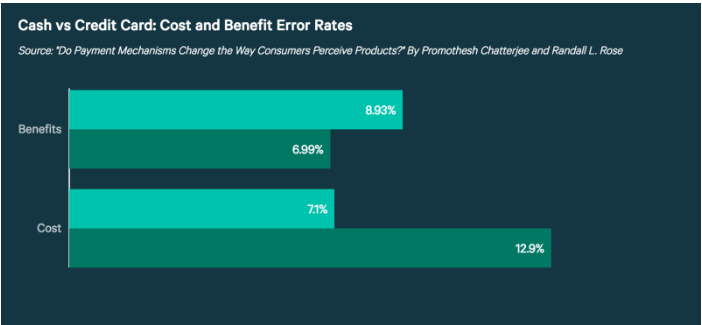

In [1]:
from IPython.display import Image
Image(r'C:\Users\Dad\Documents\Data Tales\Amex Hackathon\Pic1.png')

### <font color='green'> People Are Using Credit Cards Now More Than Ever </font>

With such an increase in credit card and remote transactions, it's important for consumers to be aware of
how their payment choice might affect their spending. This doesn't mean you shouldn't use a credit card. However,
it does mean consumers should make an effort to be especially cognizant of their choices when using a 
credit card or shopping online.

### <font color='green'> Problem Statement</font>

We will be estimating the pattern of credit cards being spent by the cardholders for the next 3 months
based on the age of the consumers, debit cards / credit cards spending rate,number of transactions being carried out by them, emi active for cardholders. 

### <font color='green'> Data Analysis</font>

In [2]:
# Importing required libraries
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import numpy as np
import warnings 
warnings.simplefilter(action='ignore', category = FutureWarning)
warnings.simplefilter(action='ignore', category = DeprecationWarning)
warnings.simplefilter(action='ignore', category = UserWarning)
import missingno as msno
from collections import Counter
import itertools

### <font color='green'> Load and explore dataset</font>

Let us explore the credit card spent dataset 

In [3]:
cc_spent_train = pd.read_csv(r'C:\Users\Dad\Documents\Data Tales\Amex Hackathon\train.csv')

In [4]:
pd.set_option('display.max_columns',45)
cc_spent_train.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,investment_3,investment_4,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
0,23334,saving,M,63,305,7695.00,NaN,479.00,NaN,622.0,NaN,2.0,1.0,3.0,NaN,NaN,NaN,150000.0,NaN,NaN,NaN,NaN,NaN,118845.2,50000.0,NaN,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0,NaN,0.00,435
1,20329,current,M,33,326,52702.00,988.72,29873.00,NaN,1087.0,2806.24,11.0,14.0,11.0,1.0,NaN,6.0,176000.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,NaN,4963.33,1921
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,6.0,9.0,6.0,3.0,2.0,14.0,65000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,NaN,0.00,1970
3,16428,saving,M,44,233,20936.00,NaN,2094.00,NaN,11778.5,NaN,9.0,6.0,6.0,NaN,NaN,NaN,600000.0,NaN,NaN,NaN,NaN,NaN,132442.0,NaN,NaN,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,NaN,1238.18,21579
4,18721,saving,F,35,324,1183.83,NaN,3656.29,NaN,945.0,NaN,2.0,7.0,9.0,NaN,NaN,NaN,100000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,NaN,0.00,1814


Let us look into the shape of data

In [5]:
cc_spent_train.shape

(32820, 44)

Now, we wil look into the Test data as well

In [6]:
cc_spent_test = pd.read_csv(r'C:\Users\Dad\Documents\Data Tales\Amex Hackathon\test.csv')

In [7]:
cc_spent_test.shape

(14067, 43)

#### <font color='green'> Understanding features </font>

- id : Unique ID for every Customer
- account_type : Account Type – current or saving
- gender : Gender of customer
- age : Age of customer
- region_code : Code assigned to region of residence (has order)
- cc_cons_apr : Credit card spend in April
- dc_cons_apr : Debit card spend in April
- cc_cons_may : Credit card spend in May
- dc_cons_may : Debit card spend in May
- cc_cons_jun : Credit card spend in June
- dc_cons_jun : Debit card spend in June
- cc_count_apr: Number of credit card transactions in April
- cc_count_may: Number of credit card transactions in May
- cc_count_jun: Number of credit card transactions in June
- dc_count_apr: Number of debit card transactions in April
- dc_count_may: Number of debit card transactions in May
- dc_count_jun: Number of debit card transactions in June
- card_lim    :Maximum Credit Card Limit allocated
- personal_loan_active : Active personal loan with other bank
- vehicle_loan_active  : Active Vehicle loan with other bank
- personal_loan_closed : Closed personal loan in last 12 months
- vehicle_loan_closed  : Closed vehicle loan in last 12 months
- investment_1 : DEMAT investment in june
    ( A Demat Account holds all the investments an individual makes in shares, govt. securities, exchange-
     traded funds, bonds and mututal funds in one place).
- investment_2 : fixed deposit investment in june
- investment_3 : Life Insurance investment in June
- investment_4 : General Insurance Investment in June
- debit_amount_apr : Total amount debited for April
- credit_amount_apr : Total amount credited for April
- debit_count_apr : Total number of times amount debited in april
- credit_count_apr : Total number of times amount credited in april
- max_credit_amount_apr : Maximum amount credited in April
- debit_amount_may : Total amount debited for May
- credit_amount_may : Total amount credited for May
- credit_count_may : Total number of times amount credited in May
- debit_count_may : Total number of times amount debited in May
- max_credit_amount_may : Maximum amount credited in May
- debit_amount_jun : Total amount debited for June
- credit_amount_jun : Total amount credited for June
- credit_count_jun : Total number of times amount credited in June
- debit_count_jun : Total number of times amount debited in June
- max_credit_amount_jun : Maximum amount credited in June
- loan_enq : Loan enquiry in last 3 months
- emi_active : Monthly EMI paid to other bank for active loans
- cc_cons : (Target) Average Credit Card Spend in next three months


Knowing the data types, memory size of the data through info() function

In [8]:
cc_spent_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32820 entries, 0 to 32819
Data columns (total 44 columns):
id                       32820 non-null int64
account_type             32820 non-null object
gender                   32820 non-null object
age                      32820 non-null int64
region_code              32820 non-null int64
cc_cons_apr              32820 non-null float64
dc_cons_apr              13768 non-null float64
cc_cons_may              32820 non-null float64
dc_cons_may              15481 non-null float64
cc_cons_jun              32820 non-null float64
dc_cons_jun              11523 non-null float64
cc_count_apr             30421 non-null float64
cc_count_may             31667 non-null float64
cc_count_jun             31230 non-null float64
dc_count_apr             13768 non-null float64
dc_count_may             15481 non-null float64
dc_count_jun             17323 non-null float64
card_lim                 32811 non-null float64
personal_loan_active     2742 non-n

There are 3 data types which are mainly used here i.e. float , int and object data type.

In [9]:
cc_spent_train.describe()

,id,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,investment_3,investment_4,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
count,32820.000000,32820.000000,32820.000000,32820.000000,13768.000000,3.282000e+04,15481.000000,32820.000000,11523.000000,30421.000000,31667.000000,31230.000000,13768.000000,15481.000000,17323.000000,32811.000000,2742.0,846.0,2883.0,1625.0,1.426000e+03,2.338000e+03,1.332000e+03,406.000000,3.093000e+04,2.951800e+04,31062.000000,31062.000000,2.951800e+04,3.051900e+04,2.941500e+04,30749.000000,30749.000000,2.941500e+04,3.062500e+04,3.127700e+04,31292.000000,31292.000000,3.127700e+04,3.282000e+04,32820.000000
mean,23450.929616,35.951676,554.854327,16661.907189,5727.615837,1.441190e+04,5635.506904,9031.179889,4666.713420,9.162191,9.540184,12.298687,5.256900,6.267618,7.897016,121553.749657,1.0,1.0,1.0,1.0,8.115118e+05,1.765459e+05,3.975786e+04,4972.642169,7.002974e+04,7.541190e+04,14.887290,3.791771,4.647113e+04,6.709618e+04,7.959347e+04,4.087352,13.934795,4.969688e+04,7.759673e+04,7.583531e+04,5.767736,16.001438,4.474355e+04,9.567620e+03,6824.631840
std,13495.676061,8.529949,188.220317,25138.435416,11544.058014,2.363688e+04,14052.343253,15720.847307,10265.189742,10.790714,9.648387,11.714253,6.147011,7.380032,9.197672,123019.826520,0.0,0.0,0.0,0.0,4.418812e+06,4.403071e+05,8.430780e+04,6107.212042,1.641944e+05,1.777199e+05,11.589652,3.482266,1.181413e+05,1.855331e+05,2.026879e+05,3.847766,11.455178,1.287256e+05,3.140103e+05,3.062791e+05,4.704716,13.370195,1.215379e+05,2.616736e+05,12459.140593
min,0.000000,22.000000,123.000000,233.970000,10.010000,1.030000e+02,20.000000,51.000000,23.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.0,1.0,1.0,1.0,2.000000e-02,3.000000e+00,0.000000e+00,-12179.000000,4.010000e+00,3.432000e+01,0.000000,0.000000,1.800000e-01,1.500000e-01,1.061000e+01,0.000000,0.000000,1.500000e-01,5.230000e+00,1.188000e+01,0.000000,0.000000,6.000000e-02,0.000000e+00,0.000000
25%,11824.750000,31.000000,425.000000,3712.000000,849.000000,2.983298e+03,796.000000,1637.875000,743.000000,3.000000,3.000000,4.000000,1.000000,2.000000,2.000000,45000.000000,1.0,1.0,1.0,1.0,4.885100e+03,3.500000e+04,6.971250e+03,977.000000,2.229260e+04,2.531025e+04,6.000000,2.000000,1.800000e+04,2.010401e+04,2.467500e+04,2.000000,6.000000,1.817300e+04,2.509642e+04,2.306400e+04,3.000000,6.000000,1.600000e+04,0.000000e+00,1285.000000
50%,23478.500000,34.000000,575.000000,8912.790000,2282.160000,7.332298e+03,2129.000000,4147.487500,1832.000000,7.000000,7.000000,9.000000,3.000000,4.000000,5.000000,75000.000000,1.0,1.0,1.0,1.0,3.289308e+04,8.500000e+04,2.500000e+04,5427.500000,4.114024e+04,4.394596e+04,12.000000,3.000000,2.813100e+04,3.836849e+04,4.538700e+04,3.000000,11.000000,3.000000e+04,4.593499e+04,4.295500e+04,5.000000,13.000000,2.687600e+04,1.510650e+02,3141.000000
75%,35096.250000,39.000000,683.000000,19932.060000,6074.600000,1.684785e+04,5640.000000,10126.250000,4607.500000,12.000000,13.000000,17.000000,7.000000,8.000000,10.000000,145000.000000,1.0,1.0,1.0,1.0,1.748331e+05,1.763457e+05,5.000000e+04,6885.000000,7.541069e+04,7.975369e+04,20.000000,5.000000,4.800000e+04,7.373561e+04,8.917050e+04,5.000000,19.000000,5.000000e+04,8.413612e+04,8.072400e+04,7.000000,22.000000,4.701000e+04,4.176868e+03,7349.250000
max,46886.000000,224.000000,977.000000,804712.580000,366223.160000,1.117246e+06,911223.490000,382914.100000,301991.940000,1012.000000,601.000000,653.000000,82.000000,97.000000,104.000000,1000000.000000,1.0,1.0,1.0,1.0,8.445222e+07,

From the describe() function, we get the interquantile range from 25% to 75% in which the data points lie the most. If there is any huge deviation among max values, there are high chances of outliers in it.
Also , if the count value is not same across all columns, the column has missing values present in it.

Also , the column "id" doesn't help us in analysis of data. Hence, we will drop the column.

In [10]:
cc_spent_train = cc_spent_train.drop(["id"], axis=1)
cc_spent_test = cc_spent_test.drop(["id"], axis=1)

Shape of train and test dataframe on dropping "id" column

In [11]:
cc_spent_train.shape

(32820, 43)

In [12]:
cc_spent_test.shape

(14067, 42)

### <font color='green'> Data Cleaning</font>

Evaluating the null values present in the dataframe

In [13]:
cc_spent_train.isnull().sum()

account_type                 0
gender                       0
age                          0
region_code                  0
cc_cons_apr                  0
dc_cons_apr              19052
cc_cons_may                  0
dc_cons_may              17339
cc_cons_jun                  0
dc_cons_jun              21297
cc_count_apr              2399
cc_count_may              1153
cc_count_jun              1590
dc_count_apr             19052
dc_count_may             17339
dc_count_jun             15497
card_lim                     9
personal_loan_active     30078
vehicle_loan_active      31974
personal_loan_closed     29937
vehicle_loan_closed      31195
investment_1             31394
investment_2             30482
investment_3             31488
investment_4             32414
debit_amount_apr          1890
credit_amount_apr         3302
debit_count_apr           1758
credit_count_apr          1758
max_credit_amount_apr     3302
debit_amount_may          2301
credit_amount_may         3405
credit_c

In [14]:
cc_spent_test.isnull().sum()

account_type                 0
gender                       0
age                          0
region_code                  0
cc_cons_apr                  0
dc_cons_apr               8230
cc_cons_may                  0
dc_cons_may               7375
cc_cons_jun                  0
dc_cons_jun               9064
cc_count_apr              1038
cc_count_may               542
cc_count_jun               634
dc_count_apr              8230
dc_count_may              7375
dc_count_jun              6552
card_lim                     3
personal_loan_active     12933
vehicle_loan_active      13712
personal_loan_closed     12808
vehicle_loan_closed      13386
investment_1             13417
investment_2             13040
investment_3             13453
investment_4             13894
debit_amount_apr           847
credit_amount_apr         1465
debit_count_apr            788
credit_count_apr           788
max_credit_amount_apr     1465
debit_amount_may          1001
credit_amount_may         1495
credit_c

<b><font color='green'> Visualization of Missing Numbers</font></b>

We will be visualizing the null values in missing numbers using "missingno".

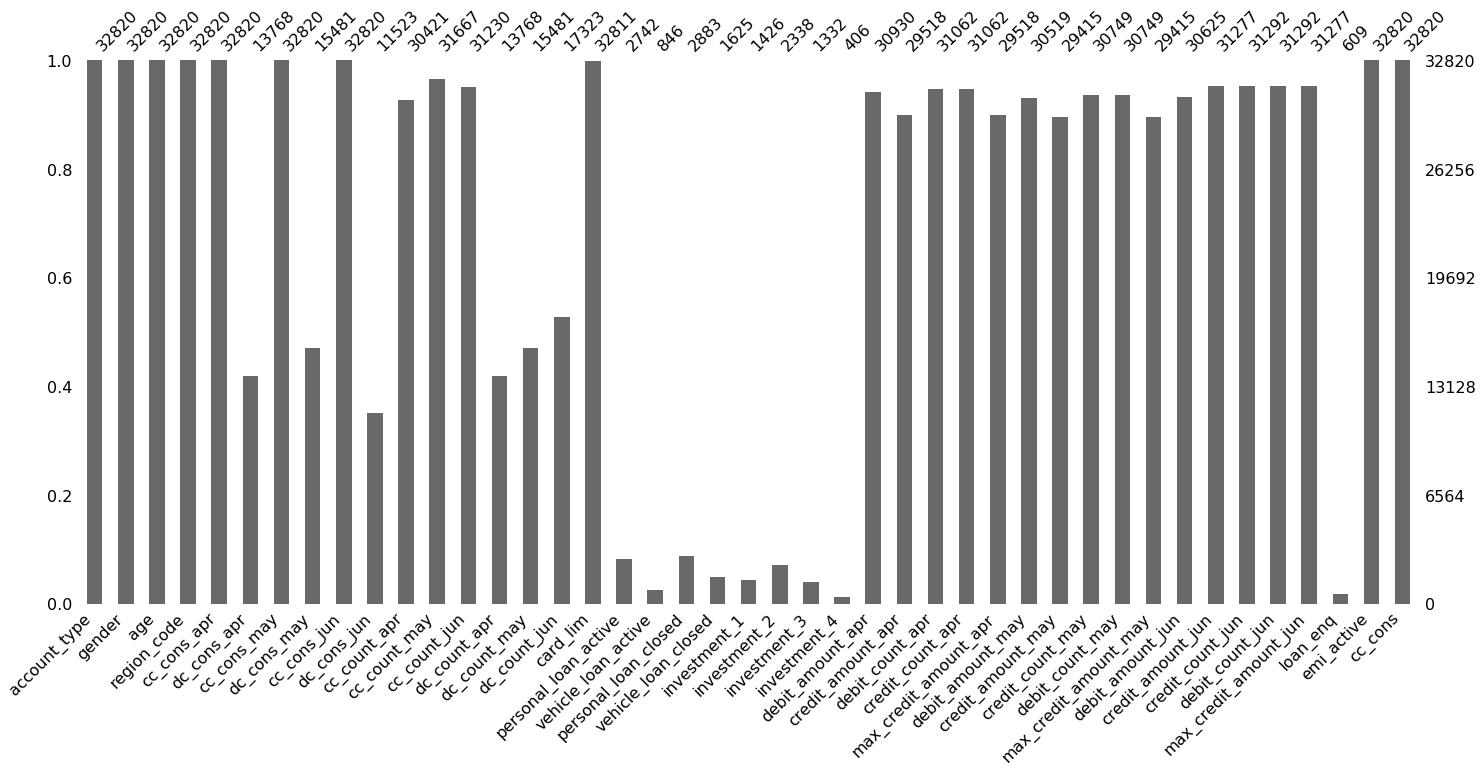

In [15]:
msno.bar(cc_spent_train)

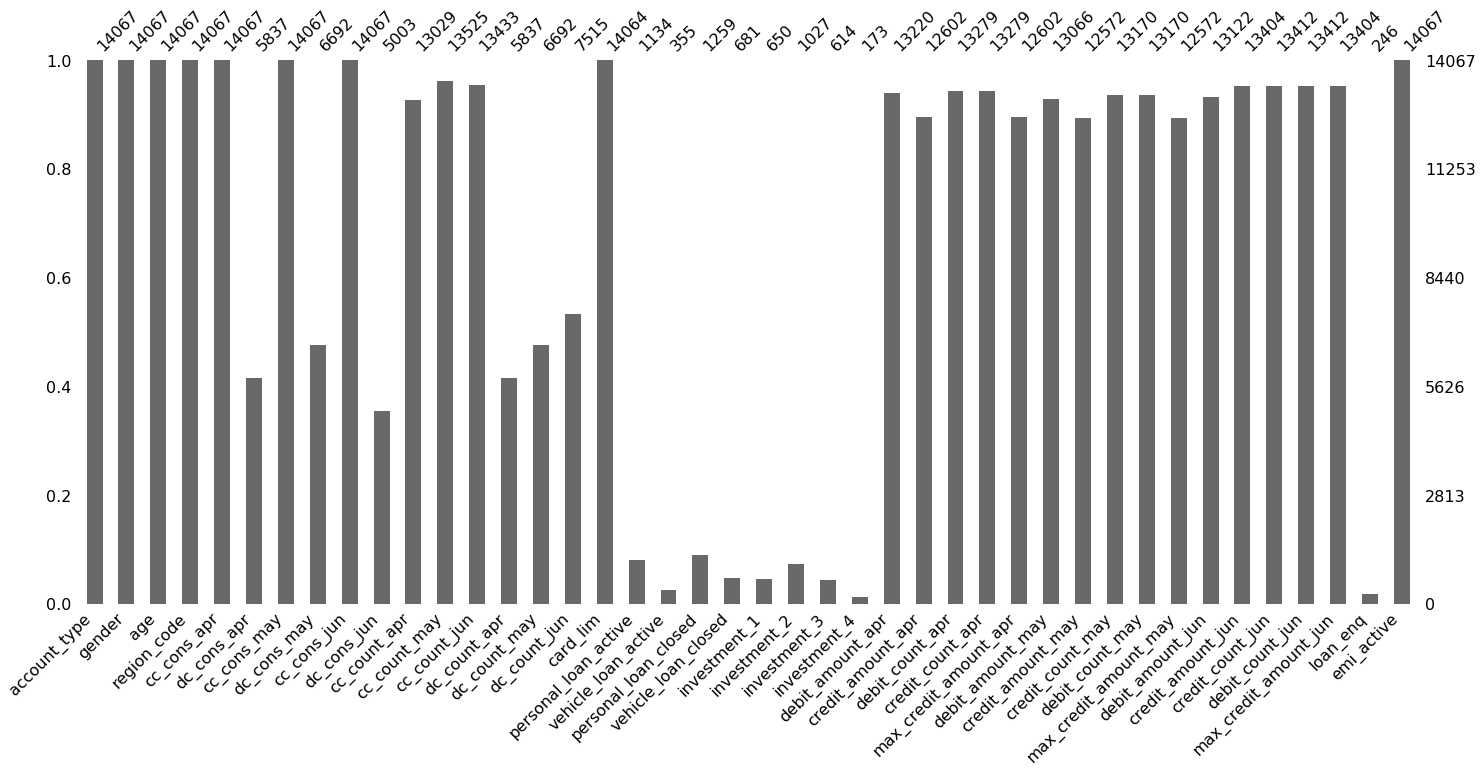

In [16]:
# Visualizing missing numbers in test set
msno.bar(cc_spent_test)

Above graphs symbolizes , missing values in Debit_card spent / No of transactions / Amount spend in Debit and Credit card in the months of April, May and June respectively. 
Credit Card limit has null values in it.The values for personal_loan and vehicle_loan with other banks are not captured properly so we need to delete it.
The features demat_investment, fixed deposits, life insurance and general insurance also contain
missing values in it. Lastly, loan enquiry status also possesses null values.


Seeing so many missing values, looks like we need to emphasize more on the data cleaning stage.

On observation of the features, we see the debit and credit amount spent, no of times amount debited/credited,
no of transactions done are being listed for each month namely April, May and June seperately. So , we can club
together all the months by using the average method.

Finding Means, Standard deviation and variance of Credit / Debit Spent, No of credit / debit transactions
and Maximum credit card allocated

Let us check the feature importance of features having null values in them.The features possessing
null values and of less importance would be eliminated from the data. For finding out feature importance
we need a ML model such as Decision Tree, Random Forest for implementation of data. Here, we will be
using Decision Tree model to get the feature importances.

In [17]:
# Copying data 'cc_spent' to data 'credit_sp'

credit_sp = cc_spent_train

# Splitting target from features while building model into X and Y variables where, X is features
# and Y is the Target
Y = credit_sp['cc_cons']
credit_sp = credit_sp.drop(['cc_cons'], axis=1)
X  = credit_sp

In [18]:
# Imputing null values in the features with the mean imputation for numerical features
X = X.fillna(X.mean())

# Imputing null values for categorical features with mode 
X['loan_enq'] = X.fillna(X.mode().iloc[0])

Let us create dummy variables from the features

In [19]:
X = pd.get_dummies(X)
X.head()

,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,investment_3,investment_4,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,account_type_current,account_type_saving,gender_F,gender_M,loan_enq_current,loan_enq_saving
0,63,305,7695.00,5727.615837,479.00,5635.506904,622.0,4666.71342,2.0,1.0,3.0,5.2569,6.267618,7.897016,150000.0,1.0,1.0,1.0,1.0,811511.814383,118845.200000,50000.000000,4972.642169,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0,0.00,0,1,0,1,0,1
1,33,326,52702.00,988.720000,29873.00,5635.506904,1087.0,2806.24000,11.0,14.0,11.0,1.0000,6.267618,6.000000,176000.0,1.0,1.0,1.0,1.0,811511.814383,176545.929358,39757.860147,4972.642169,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,4963.33,1,0,0,1,1,0
2,44,264,10800.49,3215.520000,21659.64,1607.000000,1168.0,355.00000,6.0,9.0,6.0,3.0000,2.000000,14.000000,65000.0,1.0,1.0,1.0,1.0,811511.814383,176545.929358,39757.860147,4972.642169,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,0.00,1,0,0,1,1,0
3,44,233,20936.00,5727.615837,2094.00,5635.506904,11778.5,4666.71342,9.0,6.0,6.0,5.2569,6.267618,7.897016,600000.0,1.0,1.0,1.0,1.0,811511.814383,132442.000000,39757.860147,4972.642169,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,1238.18,0,1,0,1,0,1
4,35,324,1183.83,5727.615837,3656.29,5635.506904,945.0,4666.71342,2.0,7.0,9.0,5.2569,6.267618,7.897016,100000.0,1.0,1.0,1.0,1.0,811511.814383,176545.929358,39757.860147,4972.642169,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,0.00,0,1,1,0,0,1


Recipe to check for variable importance

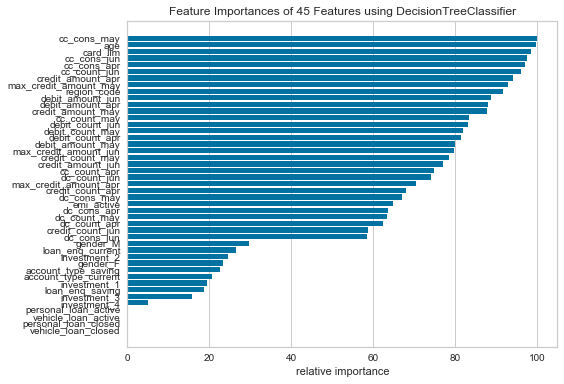

In [20]:
from sklearn.tree import DecisionTreeClassifier
from yellowbrick.features import FeatureImportances

clf = DecisionTreeClassifier()
viz = FeatureImportances(clf)
viz.fit(X[:5000],Y[:5000])
viz.poof()


From the above observation, we see that features 'vehicle_loan_closed','personal_loan_closed','vehicle_loan_active' , 'personal_loan_active','investment_4' and 'investment_3' are less important. On the other hand, we won't be getting more information from loan_enquiry even after deleting it. It is better to drop this feature as well. At this stage, we also observe that columns 'investment_1','investment2' are have missing values in them. They seem to be important features. Hence, we need to retain them.

In [21]:
cc_spent_train = cc_spent_train.drop(['personal_loan_active','vehicle_loan_active','personal_loan_closed',
                                      'vehicle_loan_closed','investment_4','investment_3','loan_enq'], axis=1)

In [22]:
cc_spent_test = cc_spent_test.drop(['personal_loan_active','vehicle_loan_active','personal_loan_closed',
                                      'vehicle_loan_closed','investment_4','investment_3','loan_enq'], axis=1)

Let us see the null values still remaining in the data (train, test)

In [23]:
cc_spent_train.isnull().sum()

account_type                 0
gender                       0
age                          0
region_code                  0
cc_cons_apr                  0
dc_cons_apr              19052
cc_cons_may                  0
dc_cons_may              17339
cc_cons_jun                  0
dc_cons_jun              21297
cc_count_apr              2399
cc_count_may              1153
cc_count_jun              1590
dc_count_apr             19052
dc_count_may             17339
dc_count_jun             15497
card_lim                     9
investment_1             31394
investment_2             30482
debit_amount_apr          1890
credit_amount_apr         3302
debit_count_apr           1758
credit_count_apr          1758
max_credit_amount_apr     3302
debit_amount_may          2301
credit_amount_may         3405
credit_count_may          2071
debit_count_may           2071
max_credit_amount_may     3405
debit_amount_jun          2195
credit_amount_jun         1543
credit_count_jun          1528
debit_co

In [24]:
cc_spent_test.isnull().sum()

account_type                 0
gender                       0
age                          0
region_code                  0
cc_cons_apr                  0
dc_cons_apr               8230
cc_cons_may                  0
dc_cons_may               7375
cc_cons_jun                  0
dc_cons_jun               9064
cc_count_apr              1038
cc_count_may               542
cc_count_jun               634
dc_count_apr              8230
dc_count_may              7375
dc_count_jun              6552
card_lim                     3
investment_1             13417
investment_2             13040
debit_amount_apr           847
credit_amount_apr         1465
debit_count_apr            788
credit_count_apr           788
max_credit_amount_apr     1465
debit_amount_may          1001
credit_amount_may         1495
credit_count_may           897
debit_count_may            897
max_credit_amount_may     1495
debit_amount_jun           945
credit_amount_jun          663
credit_count_jun           655
debit_co

We can make use of imputation methods instead of data-dropping methods.The simplest imputation method is replacing missing values with "mean" or "median" values of the dataset , or some summary statistic. This has advantage of being simple approach, as it doesn't create any bias in data. But, in case of missing values that are not strictly random , especially in the presence of great inequality in the number of missing values for the different variables , the mean substitution method may lead to inconsistent bias. Further, this doesn't add any new information and only increases sample size and leads to underestimate of errors. Hence, mean subsitution in case of missing values not random is generally not accepted.

##### <font color='green'> Imputing missing values using Linear Regression technique</font>

We will be imputing missing values to feature "card_lim" using the regression imputation technique.
In this technique, using the correlation matrix we will be figuring out the features which are highly
correlated to the missing variable. Thereby, consider the correlated features as 'X'(inputs) and 'Y'(target)
as the missing variable 'card_lim' while building the model. Once, the model is built the predicted values a
are for the missing variable and later assign it to the original dataframe.

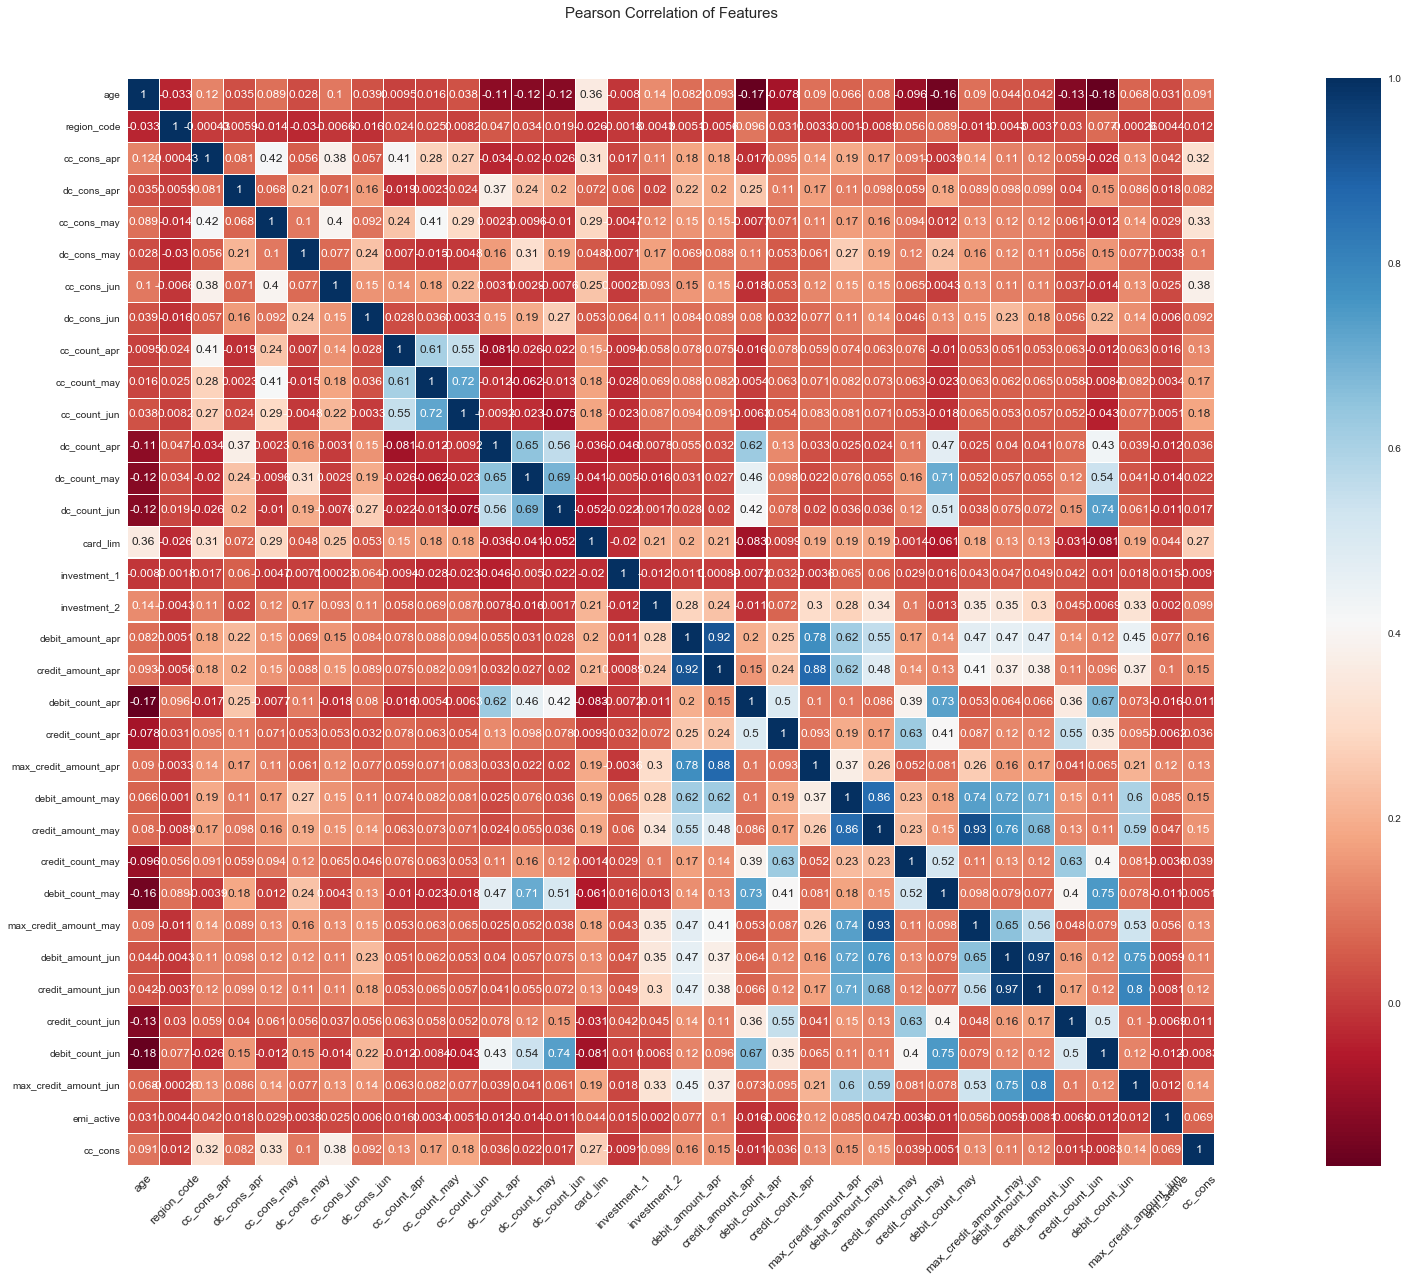

In [25]:
# Finding the correlation matrix
colormap = plt.cm.RdBu
plt.figure(figsize=(40,20))
plt.title('Pearson Correlation of Features',y=1.05, size=15)
sns.heatmap(cc_spent_train.corr(), linewidths=0.1, vmax=1.0,
            square=True, cmap=colormap, linecolor='white',
           annot=True)
plt.xticks(rotation=45,fontsize=12)
plt.show()

We figured that for column "card_lim" the features"age" and "cc_cons_apr", "cc_cons_may"
and "cc_cons_jun","cc_cons" are correlated. Hence, these variables
will be considered while model imputation and the target variable is "card_lim".

In [26]:
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
data_cl = cc_spent_train[['age','cc_cons_apr','cc_cons_may','cc_cons_jun','cc_cons','card_lim']]

# Splitting the dataset that contains missing values and no-missing values into train and test respectively
x_cl_train = data_cl[data_cl['card_lim'].notnull()].drop(columns='card_lim')
y_cl_train = data_cl[data_cl['card_lim'].notnull()]['card_lim']
x_cl_test = data_cl[data_cl['card_lim'].isnull()].drop(columns='card_lim')
y_cl_test = data_cl[data_cl['card_lim'].isnull()]['card_lim']

# Train the ml algo
linreg.fit(x_cl_train, y_cl_train)

# Predict the missing values in the attribute of the test data
predicted_cl = linreg.predict(x_cl_test)

# Let us obtain the complete dataset by combining it with the target variable
cc_spent_train.card_lim[cc_spent_train.card_lim.isnull()] = predicted_cl
cc_spent_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32820 entries, 0 to 32819
Data columns (total 36 columns):
account_type             32820 non-null object
gender                   32820 non-null object
age                      32820 non-null int64
region_code              32820 non-null int64
cc_cons_apr              32820 non-null float64
dc_cons_apr              13768 non-null float64
cc_cons_may              32820 non-null float64
dc_cons_may              15481 non-null float64
cc_cons_jun              32820 non-null float64
dc_cons_jun              11523 non-null float64
cc_count_apr             30421 non-null float64
cc_count_may             31667 non-null float64
cc_count_jun             31230 non-null float64
dc_count_apr             13768 non-null float64
dc_count_may             15481 non-null float64
dc_count_jun             17323 non-null float64
card_lim                 32820 non-null float64
investment_1             1426 non-null float64
investment_2             2338 non-

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy


#### <font color='green'> Imputing missing values for feature "card_lim" in test dataset</font>

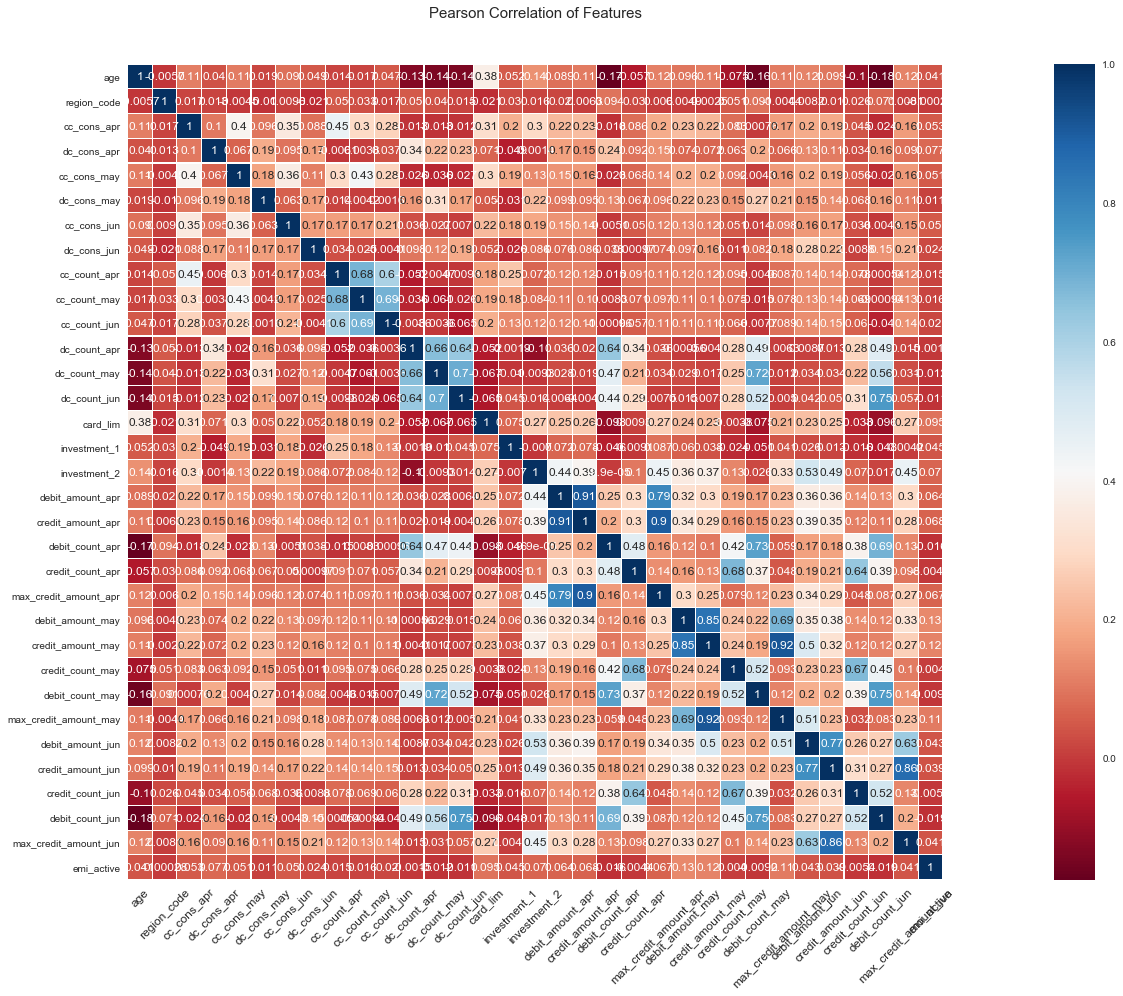

In [27]:
# Finding the correlation matrix
colormap = plt.cm.RdBu
plt.figure(figsize=(40,15))
plt.title('Pearson Correlation of Features',y=1.05, size=15)
sns.heatmap(cc_spent_test.corr(), linewidths=0.1, vmax=1.0,
            square=True, cmap=colormap, linecolor='white',
           annot=True)
plt.xticks(rotation=45, fontsize=12)
plt.show()

For the column "card_lim", we will be considering features "age" ,"cc_cons_apr",'cc_cons_may','cc_cons_jun'
and 'cc_cons'. We aren't considering other features since they possess null values in them.

In [28]:
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
data_cl = cc_spent_test[['age','cc_cons_apr','cc_cons_may','cc_cons_jun','card_lim']]

# Splitting the dataset that contains missing values and no-missing values into train and test respectively
x_cl_train = data_cl[data_cl['card_lim'].notnull()].drop(columns='card_lim')
y_cl_train = data_cl[data_cl['card_lim'].notnull()]['card_lim']
x_cl_test = data_cl[data_cl['card_lim'].isnull()].drop(columns='card_lim')
y_cl_test = data_cl[data_cl['card_lim'].isnull()]['card_lim']

# Train the ml algo
linreg.fit(x_cl_train, y_cl_train)

# Predict the missing values in the attribute of the test data
predicted_cl = linreg.predict(x_cl_test)

# Let us obtain the complete dataset by combining it with the target variable
cc_spent_test.card_lim[cc_spent_test.card_lim.isnull()] = predicted_cl
cc_spent_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14067 entries, 0 to 14066
Data columns (total 35 columns):
account_type             14067 non-null object
gender                   14067 non-null object
age                      14067 non-null int64
region_code              14067 non-null int64
cc_cons_apr              14067 non-null float64
dc_cons_apr              5837 non-null float64
cc_cons_may              14067 non-null float64
dc_cons_may              6692 non-null float64
cc_cons_jun              14067 non-null float64
dc_cons_jun              5003 non-null float64
cc_count_apr             13029 non-null float64
cc_count_may             13525 non-null float64
cc_count_jun             13433 non-null float64
dc_count_apr             5837 non-null float64
dc_count_may             6692 non-null float64
dc_count_jun             7515 non-null float64
card_lim                 14067 non-null float64
investment_1             650 non-null float64
investment_2             1027 non-null fl

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy


We now see that the null values for column 'card_lim' is imputed.

We see that inorder to impute missing values in other variables, we need to see check coefficiency
of it and the features should have non-null values in them which is a bit complicated for rest features
through regression imputation. Hence, we will be using KNN imputation technique.

#### <font color='green'> Usage of KNN imputation technique inorder to impute missing values</font>

Extracting the null valued features into a seperate dataframe "cc_null_values"

In [29]:
null_cols = cc_spent_train.columns[cc_spent_train.isnull().any()]

In [30]:
null_cols

Index(['dc_cons_apr', 'dc_cons_may', 'dc_cons_jun', 'cc_count_apr',
       'cc_count_may', 'cc_count_jun', 'dc_count_apr', 'dc_count_may',
       'dc_count_jun', 'investment_1', 'investment_2', 'debit_amount_apr',
       'credit_amount_apr', 'debit_count_apr', 'credit_count_apr',
       'max_credit_amount_apr', 'debit_amount_may', 'credit_amount_may',
       'credit_count_may', 'debit_count_may', 'max_credit_amount_may',
       'debit_amount_jun', 'credit_amount_jun', 'credit_count_jun',
       'debit_count_jun', 'max_credit_amount_jun'],
      dtype='object')

In [31]:
null_cols_train = pd.DataFrame(cc_spent_train[null_cols])


In [32]:
null_cols_test = pd.DataFrame(cc_spent_test[null_cols])

In [33]:
from fancyimpute import KNN

# fancyimpute removes column names, storing columns in the form of a list for train and test
cols = list(null_cols_train)

features = list(null_cols_test)

Using TensorFlow backend.


Splitting dataframe into 2 dataframes based on indexes, since it is causing a memory issue

In [34]:
# Use 5 nearest rows which have a feature to fill in each row's  missing features
cc_train_1 = pd.DataFrame(KNN(k=5).fit_transform(null_cols_train[1:15001]))
cc_train_1.columns = cols

Imputing row 1/15000 with 4 missing, elapsed time: 84.846
Imputing row 101/15000 with 2 missing, elapsed time: 84.939
Imputing row 201/15000 with 8 missing, elapsed time: 85.049
Imputing row 301/15000 with 8 missing, elapsed time: 85.172
Imputing row 401/15000 with 2 missing, elapsed time: 85.300
Imputing row 501/15000 with 8 missing, elapsed time: 85.396
Imputing row 601/15000 with 9 missing, elapsed time: 85.490
Imputing row 701/15000 with 2 missing, elapsed time: 85.587
Imputing row 801/15000 with 7 missing, elapsed time: 85.661
Imputing row 901/15000 with 8 missing, elapsed time: 85.755
Imputing row 1001/15000 with 10 missing, elapsed time: 85.831
Imputing row 1101/15000 with 4 missing, elapsed time: 85.924
Imputing row 1201/15000 with 8 missing, elapsed time: 86.028
Imputing row 1301/15000 with 8 missing, elapsed time: 86.114
Imputing row 1401/15000 with 7 missing, elapsed time: 86.193
Imputing row 1501/15000 with 14 missing, elapsed time: 86.287
Imputing row 1601/15000 with 23 mi

Imputing row 13501/15000 with 2 missing, elapsed time: 96.632
Imputing row 13601/15000 with 5 missing, elapsed time: 96.707
Imputing row 13701/15000 with 8 missing, elapsed time: 96.785
Imputing row 13801/15000 with 8 missing, elapsed time: 96.870
Imputing row 13901/15000 with 14 missing, elapsed time: 96.946
Imputing row 14001/15000 with 10 missing, elapsed time: 97.040
Imputing row 14101/15000 with 7 missing, elapsed time: 97.147
Imputing row 14201/15000 with 5 missing, elapsed time: 97.225
Imputing row 14301/15000 with 6 missing, elapsed time: 97.303
Imputing row 14401/15000 with 8 missing, elapsed time: 97.397
Imputing row 14501/15000 with 13 missing, elapsed time: 97.465
Imputing row 14601/15000 with 6 missing, elapsed time: 97.543
Imputing row 14701/15000 with 7 missing, elapsed time: 97.628
Imputing row 14801/15000 with 2 missing, elapsed time: 97.700
Imputing row 14901/15000 with 6 missing, elapsed time: 97.778


In [35]:
cc_train_2 = pd.DataFrame(KNN(k=5).fit_transform(null_cols_train[15000:32821]))
cc_train_2.columns = cols

Imputing row 1/17820 with 3 missing, elapsed time: 132.878
Imputing row 101/17820 with 2 missing, elapsed time: 149.584
Imputing row 201/17820 with 7 missing, elapsed time: 149.684
Imputing row 301/17820 with 2 missing, elapsed time: 149.796
Imputing row 401/17820 with 6 missing, elapsed time: 149.884
Imputing row 501/17820 with 24 missing, elapsed time: 149.984
Imputing row 601/17820 with 3 missing, elapsed time: 150.080
Imputing row 701/17820 with 3 missing, elapsed time: 150.188
Imputing row 801/17820 with 23 missing, elapsed time: 150.292
Imputing row 901/17820 with 5 missing, elapsed time: 150.396
Imputing row 1001/17820 with 2 missing, elapsed time: 150.488
Imputing row 1101/17820 with 23 missing, elapsed time: 150.588
Imputing row 1201/17820 with 8 missing, elapsed time: 150.680
Imputing row 1301/17820 with 2 missing, elapsed time: 150.776
Imputing row 1401/17820 with 5 missing, elapsed time: 150.880
Imputing row 1501/17820 with 7 missing, elapsed time: 150.980
Imputing row 1601

Imputing row 13301/17820 with 2 missing, elapsed time: 162.415
Imputing row 13401/17820 with 2 missing, elapsed time: 162.511
Imputing row 13501/17820 with 3 missing, elapsed time: 162.615
Imputing row 13601/17820 with 5 missing, elapsed time: 162.703
Imputing row 13701/17820 with 2 missing, elapsed time: 162.791
Imputing row 13801/17820 with 9 missing, elapsed time: 162.915
Imputing row 13901/17820 with 8 missing, elapsed time: 163.007
Imputing row 14001/17820 with 3 missing, elapsed time: 163.119
Imputing row 14101/17820 with 2 missing, elapsed time: 163.211
Imputing row 14201/17820 with 10 missing, elapsed time: 163.311
Imputing row 14301/17820 with 6 missing, elapsed time: 163.399
Imputing row 14401/17820 with 3 missing, elapsed time: 163.507
Imputing row 14501/17820 with 8 missing, elapsed time: 163.595
Imputing row 14601/17820 with 2 missing, elapsed time: 163.691
Imputing row 14701/17820 with 8 missing, elapsed time: 163.783
Imputing row 14801/17820 with 3 missing, elapsed time:

In [36]:
# Combining dataframes "cc_train_1" and "cc_train_2" into a single dataframe "cc_num_data" after
# imputation
cc_num_data = pd.concat([cc_train_1, cc_train_2], ignore_index=True)

In [37]:
cc_num_data.shape

(32820, 26)

In [38]:
cc_num_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32820 entries, 0 to 32819
Data columns (total 26 columns):
dc_cons_apr              32820 non-null float64
dc_cons_may              32820 non-null float64
dc_cons_jun              32820 non-null float64
cc_count_apr             32820 non-null float64
cc_count_may             32820 non-null float64
cc_count_jun             32820 non-null float64
dc_count_apr             32820 non-null float64
dc_count_may             32820 non-null float64
dc_count_jun             32820 non-null float64
investment_1             32820 non-null float64
investment_2             32820 non-null float64
debit_amount_apr         32820 non-null float64
credit_amount_apr        32820 non-null float64
debit_count_apr          32820 non-null float64
credit_count_apr         32820 non-null float64
max_credit_amount_apr    32820 non-null float64
debit_amount_may         32820 non-null float64
credit_amount_may        32820 non-null float64
credit_count_may         32

For the test dataset, the indices are not quite large. Hence, we won't be slicing it.

In [39]:
cc_test = pd.DataFrame(KNN(k=5).fit_transform(null_cols_test))
cc_test.columns = features

Imputing row 1/14067 with 6 missing, elapsed time: 79.899
Imputing row 101/14067 with 2 missing, elapsed time: 80.008
Imputing row 201/14067 with 2 missing, elapsed time: 80.102
Imputing row 301/14067 with 9 missing, elapsed time: 80.246
Imputing row 401/14067 with 2 missing, elapsed time: 80.394
Imputing row 501/14067 with 8 missing, elapsed time: 80.501
Imputing row 601/14067 with 10 missing, elapsed time: 80.622
Imputing row 701/14067 with 3 missing, elapsed time: 80.754
Imputing row 801/14067 with 3 missing, elapsed time: 80.856
Imputing row 901/14067 with 3 missing, elapsed time: 80.972
Imputing row 1001/14067 with 4 missing, elapsed time: 81.054
Imputing row 1101/14067 with 23 missing, elapsed time: 81.166
Imputing row 1201/14067 with 3 missing, elapsed time: 81.253
Imputing row 1301/14067 with 8 missing, elapsed time: 81.337
Imputing row 1401/14067 with 5 missing, elapsed time: 81.408
Imputing row 1501/14067 with 8 missing, elapsed time: 81.518
Imputing row 1601/14067 with 4 mis

Imputing row 13401/14067 with 5 missing, elapsed time: 93.505
Imputing row 13501/14067 with 9 missing, elapsed time: 93.577
Imputing row 13601/14067 with 19 missing, elapsed time: 93.655
Imputing row 13701/14067 with 8 missing, elapsed time: 93.737
Imputing row 13801/14067 with 9 missing, elapsed time: 93.828
Imputing row 13901/14067 with 3 missing, elapsed time: 93.891
Imputing row 14001/14067 with 4 missing, elapsed time: 94.031


In [40]:
cc_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14067 entries, 0 to 14066
Data columns (total 26 columns):
dc_cons_apr              14067 non-null float64
dc_cons_may              14067 non-null float64
dc_cons_jun              14067 non-null float64
cc_count_apr             14067 non-null float64
cc_count_may             14067 non-null float64
cc_count_jun             14067 non-null float64
dc_count_apr             14067 non-null float64
dc_count_may             14067 non-null float64
dc_count_jun             14067 non-null float64
investment_1             14067 non-null float64
investment_2             14067 non-null float64
debit_amount_apr         14067 non-null float64
credit_amount_apr        14067 non-null float64
debit_count_apr          14067 non-null float64
credit_count_apr         14067 non-null float64
max_credit_amount_apr    14067 non-null float64
debit_amount_may         14067 non-null float64
credit_amount_may        14067 non-null float64
credit_count_may         14

Adding the values of imputed columns back to the original dataframe "cc_spent_train"

In [41]:
cc_spent_train[null_cols] = cc_num_data
cc_spent_test[null_cols] = cc_test

Let's check the information of dataframe

In [42]:
cc_spent_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32820 entries, 0 to 32819
Data columns (total 36 columns):
account_type             32820 non-null object
gender                   32820 non-null object
age                      32820 non-null int64
region_code              32820 non-null int64
cc_cons_apr              32820 non-null float64
dc_cons_apr              32820 non-null float64
cc_cons_may              32820 non-null float64
dc_cons_may              32820 non-null float64
cc_cons_jun              32820 non-null float64
dc_cons_jun              32820 non-null float64
cc_count_apr             32820 non-null float64
cc_count_may             32820 non-null float64
cc_count_jun             32820 non-null float64
dc_count_apr             32820 non-null float64
dc_count_may             32820 non-null float64
dc_count_jun             32820 non-null float64
card_lim                 32820 non-null float64
investment_1             32820 non-null float64
investment_2             32820 no

In [43]:
cc_spent_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14067 entries, 0 to 14066
Data columns (total 35 columns):
account_type             14067 non-null object
gender                   14067 non-null object
age                      14067 non-null int64
region_code              14067 non-null int64
cc_cons_apr              14067 non-null float64
dc_cons_apr              14067 non-null float64
cc_cons_may              14067 non-null float64
dc_cons_may              14067 non-null float64
cc_cons_jun              14067 non-null float64
dc_cons_jun              14067 non-null float64
cc_count_apr             14067 non-null float64
cc_count_may             14067 non-null float64
cc_count_jun             14067 non-null float64
dc_count_apr             14067 non-null float64
dc_count_may             14067 non-null float64
dc_count_jun             14067 non-null float64
card_lim                 14067 non-null float64
investment_1             14067 non-null float64
investment_2             14067 no

Let us now convert the column "loan_enq" to categorical from binary_form

#### <font color='green'> Detecting and Removing Outliers</font>

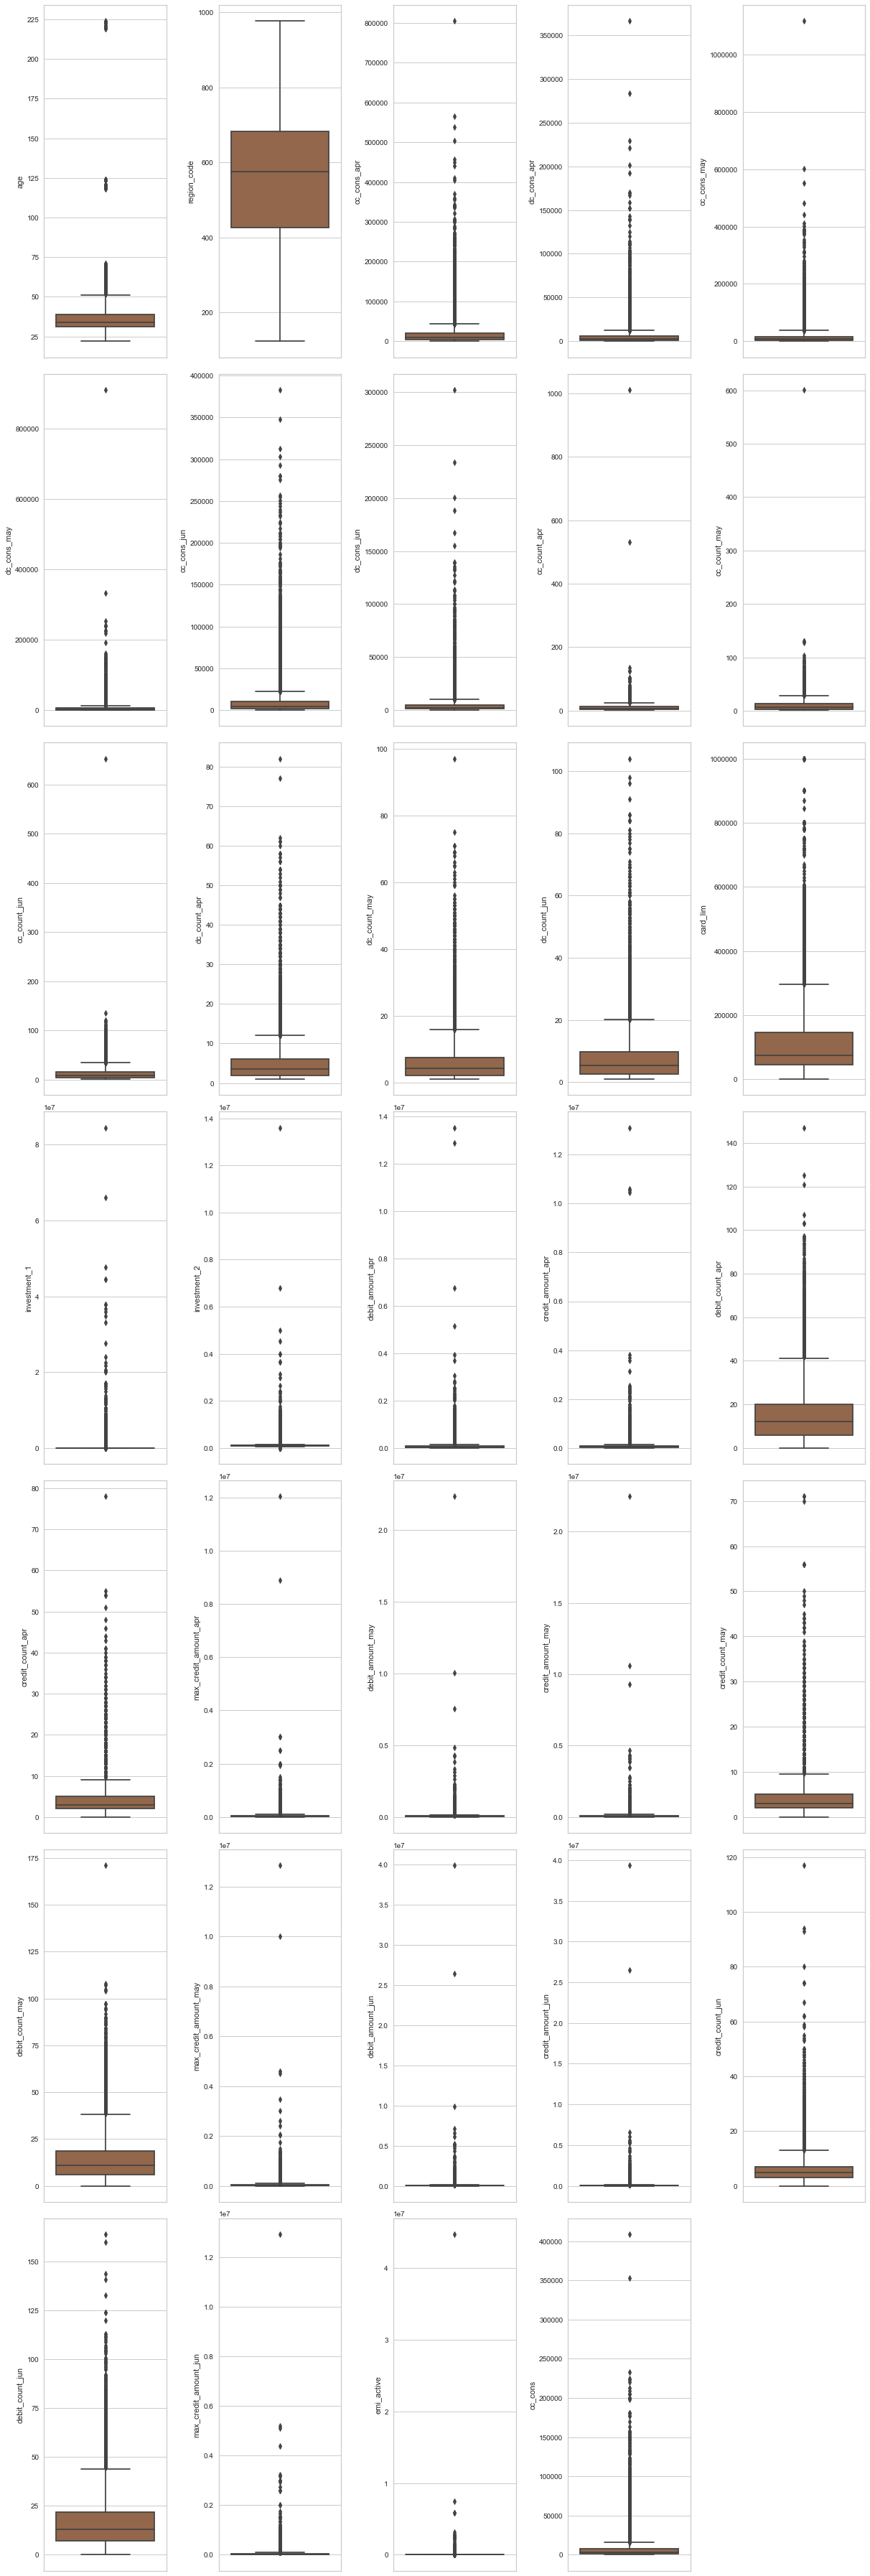

In [44]:
fig = plt.figure(figsize=(17,50))
i=1
for column in cc_spent_train.select_dtypes(["int64","float64"]):
    plt.subplot(7,5,i)
    sns.set_style("whitegrid")
    ax = sns.boxplot(cc_spent_train[column], palette="copper", orient='v')
    i = i + 1
    
plt.tight_layout()
plt.show()

    

The above graph shows the Oultier Analysis of various continuous variables, we see most of the data points
lying above the inter-quartile range. However, they cannot be termed as outliers. In this scenario, we will be gathering data points
which don't follow in the normal pattern and consider a pattern among them , detect and remove outliers.

We see few consumers spending credit amount above 800000 in month of April. Hence, finding people ranging above 800000.

In [45]:
cc_spent_train[cc_spent_train['cc_cons_apr'] >= 800000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
23080,saving,M,39,523,804712.58,15288.634731,384099.42,17823.99,99433.22,2868.83,60.0,52.0,58.0,8.568769,11.0,13.0,280000.0,62457.015284,108670.006909,537009.0,500015.0,9.0,1.0,500000.0,491283.61,500039.0,1.0,21.0,500000.0,589069.84,502173.0,3.0,15.0,500000.0,0.0,198197


Few consumers are spending debits above 250000. Hence, finding spending amount > 250000.

In [46]:
cc_spent_train[cc_spent_train['dc_cons_apr'] >= 250000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
526,current,M,28,534,3262.145,283697.75,5063.29,103663.9,239.00,2419.300869,1.0,8.0,8.0,7.0,2.0,5.0,35000.0,1385.163994,274695.982435,578617.65,462080.65,24.0,12.0,217917.86,80729.97,148195.00,10.0,7.0,60025.0,174704.04,130232.90,12.0,15.0,60025.0,2223.10,1199
1673,saving,F,44,523,2445.660,366223.16,2027.24,10940.0,2645.95,2976.331743,17.0,16.0,4.0,30.0,5.0,3.0,126000.0,6425.330278,119964.513184,545955.65,588490.61,80.0,7.0,200000.00,80552.72,60681.96,6.0,17.0,20000.0,14414.00,1022.75,5.0,5.0,515.0,45325.74,200


Credit spend by consumers are ranging above 1000000. Hence, getting the exact count.

In [47]:
cc_spent_train[cc_spent_train['cc_cons_may'] >= 1000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
17530,current,F,44,523,122265.9,774.0,1117246.31,33923.504497,128140.57,2704.88,33.0,39.0,54.0,1.0,3.088505,5.0,800000.0,57473.198191,108670.279794,448415.95,382613.0,21.0,3.0,337428.0,844686.5,842702.0,5.0,26.0,500000.0,976208.64,1021136.45,6.0,31.0,500000.0,11185.96,65782


Debit amount being spent by customers in May month is also ranging above 800000.

In [48]:
cc_spent_train[cc_spent_train['dc_cons_may'] >= 800000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
7813,saving,M,38,891,22543.56,11555.0,15759.96,911223.49,3216.0,15985.54103,42.0,17.0,21.0,1.0,11.0,1.0,46000.0,56077.122398,371443.828812,162185.62,458631.62,16.0,10.0,141500.0,1685070.26,387285.26,18.0,22.0,112450.0,306276.0,309233.0,12.0,8.0,112450.0,0.0,1527


Credit amount in June month is being spent above 350000 by few users. Let us have a look of it. 

In [49]:
cc_spent_train[cc_spent_train['cc_cons_jun'] >= 350000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
6337,current,M,39,263,335251.49,2474.962554,402086.0,14871.48,382914.1,12592.0,9.0,4.0,3.6,6.3635,10.0,5.0,243000.0,54667.92434,39457.572024,64441.57,50495.0,17.0,4.0,40000.0,46680.32,78536.84,4.0,18.0,40000.0,60786.8,40256.0,2.0,16.0,40000.0,4014.99,408630


Debit amount spent in June month is also above 300000 by consumers. Let's see how many of them belong to
this category.

In [50]:
cc_spent_train[cc_spent_train['dc_cons_jun'] >= 300000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
26857,current,F,27,683,10123.5,1204.32331,33783.5,2488.252939,889.0,301991.94,5.0,14.0,7.0,1.931124,3.858226,17.0,155000.0,7998.808668,108670.036943,43131.26,26040.0,17.0,4.0,20000.0,44256.0,300195.0,2.0,10.0,280000.0,324231.44,185175.76,5.0,19.0,155000.0,0.0,2582


Credit transactions carried out in April, May and June are 400 and 600. Let us find the pattern of users
performing such huge transactions.

In [51]:
cc_spent_train[cc_spent_train['cc_count_apr'] >= 400]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
3412,current,M,32,523,3031.00,6563.782524,1254.00,20.000000,3502.0,7376.916683,1012.0,17.0,28.0,5.387539,1.000000,10.660372,101000.0,225067.871613,198463.393895,603266.230000,876516.300000,23.000000,16.0,330000.000000,641816.640000,402243.160000,17.000000,13.000000,242209.3000,184154.21,141537.0,19.0,19.0,20000.0,6292.51,40720
22323,current,M,34,245,18208.18,1002.487643,37353.05,7257.154246,57170.0,1483.566802,531.0,601.0,653.0,1.767611,3.511149,8.381056,225000.0,73952.091016,80874.351579,128.598083,756.120891,1.396968,0.0,593.548516,975.624647,7679.641688,0.396045,1.615259,6529.8061,28154.00,51684.0,4.0,3.0,30000.0,31642.29,52951


In [52]:
cc_spent_train[cc_spent_train['cc_count_may'] >= 600]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
22323,current,M,34,245,18208.18,1002.487643,37353.05,7257.154246,57170.0,1483.566802,531.0,601.0,653.0,1.767611,3.511149,8.381056,225000.0,73952.091016,80874.351579,128.598083,756.120891,1.396968,0.0,593.548516,975.624647,7679.641688,0.396045,1.615259,6529.8061,28154.0,51684.0,4.0,3.0,30000.0,31642.29,52951


In [53]:
cc_spent_train[cc_spent_train['cc_count_jun'] >= 600]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
22323,current,M,34,245,18208.18,1002.487643,37353.05,7257.154246,57170.0,1483.566802,531.0,601.0,653.0,1.767611,3.511149,8.381056,225000.0,73952.091016,80874.351579,128.598083,756.120891,1.396968,0.0,593.548516,975.624647,7679.641688,0.396045,1.615259,6529.8061,28154.0,51684.0,4.0,3.0,30000.0,31642.29,52951


Debit transactions carried out by users in months of April, May and June are also 70-90.

In [54]:
cc_spent_train[cc_spent_train['dc_count_apr'] >= 70]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
16361,current,M,29,946,13845.90,26503.30,9618.510,14799.97,6729.00,3766.00,12.0,18.0,39.0,82.0,75.0,57.0,25000.0,13198.318749,108669.125820,42086.05,31250.75,95.0,7.0,22668.0,53238.25,57283.00,5.0,84.0,29000.0,29606.33,33128.00,5.0,70.0,25906.0,0.00,6539
24411,saving,M,33,344,3123.49,15731.91,18261.215,22363.47,32728.94,12115.42,3.0,4.6,5.0,77.0,65.0,91.0,75000.0,7443.498193,108669.942754,87292.41,80317.00,103.0,7.0,42250.0,79953.97,90349.25,8.0,84.0,42250.0,132594.54,127078.43,15.0,106.0,40750.0,2789.26,9354


In [55]:
cc_spent_train[cc_spent_train['dc_count_may'] >= 80]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
26668,current,M,27,683,1272.25,32621.65,325.5,28727.38,580.0,21125.68,3.8,1.0,4.0,52.0,97.0,96.0,75000.0,3990.177161,108671.796645,106114.5,127752.97,76.0,11.0,80292.0,84794.17,74465.5,7.0,108.0,63545.0,97444.86,80360.0,5.0,112.0,63545.0,0.0,2


In [56]:
cc_spent_train[cc_spent_train['dc_count_jun'] >= 90]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
4334,current,F,32,764,9264.00,11952.830000,843.000,13732.06,10984.00,7584.02,2.0,9.0,15.0,62.000000,53.0,98.0,78000.0,1349.127942,68331.002937,37427.860000,39401.75,81.0,7.0,27654.0,32052.16,27972.00,3.0,61.0,27654.0,29437.44,31190.85,6.0,107.0,27653.0,215.22,26954
12715,saving,F,34,513,7651.81,213.032751,1915.450,11067.09,869.00,8849.34,9.0,17.0,6.0,1.000048,38.0,104.0,100000.0,3945.406633,27334.988674,117.971571,35103.00,0.0,1.0,35007.0,35094.59,54235.50,5.0,53.0,35007.0,57250.16,47676.01,20.0,109.0,34995.0,0.00,5820
24411,saving,M,33,344,3123.49,15731.910000,18261.215,22363.47,32728.94,12115.42,3.0,4.6,5.0,77.000000,65.0,91.0,75000.0,7443.498193,108669.942754,87292.410000,80317.00,103.0,7.0,42250.0,79953.97,90349.25,8.0,84.0,42250.0,132594.54,127078.43,15.0,106.0,40750.0,2789.26,9354
26668,current,M,27,683,1272.25,32621.650000,325.500,28727.38,580.00,21125.68,3.8,1.0,4.0,52.000000,97.0,96.0,75000.0,3990.177161,108671.796645,106114.500000,127752.97,76.0,11.0,80292.0,84794.17,74465.50,7.0,108.0,63545.0,97444.86,80360.00,5.0,112.0,63545.0,0.00,2


Credit card limit above 1000000 for few.

In [57]:
cc_spent_train[cc_spent_train['card_lim'] >= 1000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
5104,current,M,45,683,8323.52,1227.000000,600699.73,1421.000000,52601.04,874.051222,6.250008,4.0,16.0,3.000000,3.000000,2.586094,1000000.0,807.997827,71307.208280,1.389188e+05,6.827100e+04,25.000000,2.000000,3.411700e+04,1.414475e+04,5.247000e+03,1.000000,8.000000,5.000000e+03,4.094342e+04,40531.00,3.0,7.0,35502.00,0.00,13261
5489,saving,M,45,723,124366.50,215.592607,96689.70,1986.663956,1160.00,3682.129541,11.333328,7.0,7.0,1.000000,3.835167,2.588296,1000000.0,7633.762883,425091.550034,2.469095e+03,6.608103e+03,1.466667,0.533333,5.126598e+03,1.150380e+05,2.152760e+05,5.000000,2.000000,1.000000e+05,1.398685e+05,421747.00,5.0,20.0,400000.00,172301.14,25330
8564,current,M,46,233,101160.74,1619.000000,77473.78,5870.000000,121728.99,2632.000000,2.000000,5.0,3.6,3.000000,7.000000,13.000000,1000000.0,20683.317334,36743.085969,4.514601e+04,4.534101e+04,15.000000,4.000000,2.396201e+04,6.149394e+04,6.224756e+04,6.000000,19.000000,2.500000e+04,4.751176e+04,48892.78,12.0,24.0,18897.78,1140462.95,68600
9154,current,F,43,683,4079.32,8905.355752,7642.64,3261.819205,475.00,1298.135088,2.000000,2.0,10.0,1.838247,1.344149,1.407980,1000000.0,1395.103049,76484.374877,1.489184e+04,2.569800e+04,4.000000,2.000000,2.356000e+04,1.672407e+04,2.496900e+04,2.000000,1.000000,2.356000e+04,1.680430e+03,1986.00,2.0,1.0,1205.00,0.00,1349
14185,saving,M,44,823,267407.02,2122.000000,1077.00,7860.000000,109773.22,3722.000000,4.000000,4.0,4.2,1.000000,13.000000,14.000000,1000000.0,29728.747855,314480.739114,4.221470e+03,2.777770e+03,7.000000,2.000000,2.500000e+03,1.166200e+04,1.670436e+04,3.000000,18.000000,1.450000e+04,9.169290e+03,7333.76,4.0,25.0,7000.00,0.00,32163
14241,saving,M,33,806,262979.34,3065.571325,53041.67,1150.647420,68414.25,643.260220,15.000000,24.0,23.0,1.051581,1.915173,3.507311,1000000.0,4324.634442,179165.713840,3.716250e+03,4.218000e+03,2.000000,1.000000,4.000000e+03,4.566500e+03,5.180000e+03,1.000000,2.000000,5.000000e+03,7.680000e+03,30312.00,2.0,3.0,30000.00,27448.91,91029
15120,current,M,59,245,126943.95,48138.000000,329842.58,27949.454107,85181.66,19940.977160,36.000000,56.0,29.0,4.000000,10.945496,21.503938,1000000.0,26250.947875,153570.160000,1.563448e+06,1.929494e+06,39.000000,9.000000,9.195920e+05,1.009562e+06,9.713800e+05,3.000000,27.000000,9.195930e+05,3.422567e+06,4228019.00,6.0,31.0,3000000.00,200858.63,38217
17928,current,M,40,683,59287.65,25577.090000,24849.90,50661.050000,5046.50,11702.400000,16.000000,13.0,20.0,12.000000,25.000000,30.000000,1000000.0,2.130000,137510.680454,2.335624e+05,2.218770e+05,34.000000,3.000000,1.843910e+05,2.845315e+05,1.895633e+05,3.000000,47.000000,1.843930e+05,3.273895e+05,195789.20,4.0,52.0,184392.00,36204.77,19940
19442,saving,M,60,523,72686.75,264.270629,59859.88,9234.177019,197694.38,3524.050644,20.000000,18.0,24.0,1.461824,1.211810,1.601934,1000000.0,308591.000000,45995.553198,1.350000e+02,3.390141e+02,1.000000,0.000000,1.489588e+02,4.189135e+03,1.022943e+04,0.380232,1.079351,5.908791e+03,2.507139e+03,480.00,1.0,0.0,384.00,319598.66,104722
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.000000,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,8822.253779,108670.000004,1.353571e+07,1.043463e+07,19.000000,24.000000,2.000000e+06,2.230122e+07,2.246350e+07,22.000000,20.000000,1.285103e+07,3.986881e+07,39339313.35,19.0,26.0,12932377.08,1127.37,135614


Some have invested huge in fixed deposits

In [58]:
cc_spent_train[cc_spent_train['investment_2'] >= 6000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
14315,current,M,54,519,1665.00,4083.213919,2879.00,67085.0,2881.0,1314.088232,3.0,6.0,3.0,1.348071,1.0,1.924362,43000.0,1653.182154,13602841.60,7168.5,328.0,1.0,2.0,33.0,69939.52,706338.0,2.0,2.0,704520.0,11180.52,4085.0,2.0,1.0,3858.0,0.00,10000
17432,saving,M,41,683,51561.65,12354.811242,105402.18,2193.0,28457.0,4049.237918,42.0,43.0,73.0,7.534297,2.0,1.000000,200000.0,19843.190604,6803111.71,3954222.0,3819581.0,12.0,9.0,2500000.0,234543.50,261789.0,12.0,12.0,98592.0,152301.87,70229.0,4.0,15.0,40000.0,2988.67,27048


Total debit amount spent in April is exceeding 12000000.

In [59]:
cc_spent_train[cc_spent_train['debit_amount_apr'] >= 12000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
26323,saving,M,58,245,139159.42,3208.994399,179209.3,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,8822.253779,108670.000004,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,1127.37,135614
30409,current,M,62,523,20912.00,4836.573237,10058.0,2286.450000,99037.00,17682.112813,2.0,2.0,10.0,6.597474,1.000000,6.000000,300000.0,4935.944142,108670.000956,12897875.00,13100583.00,11.0,5.0,12029154.0,115095.20,1054267.00,3.0,12.0,910559.00,71359.11,1173923.66,9.0,18.0,964372.00,87567.67,73281


Total credit amount spent in April is also exceeding 10000000

In [60]:
cc_spent_train[cc_spent_train['credit_amount_apr'] >= 10000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
373,current,M,27,503,3574.00,4363.997768,2415.9,9831.241554,3256.45,11065.539211,5.0,10.0,12.0,1.411516,3.976272,9.549494,50000.0,3550.070752,1.400000e+06,6751644.75,10546937.00,10.0,13.0,2000000.0,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,0.00,2012
22926,current,M,48,683,176584.68,1836.811347,128717.0,5794.510366,78539.06,4412.662812,14.0,32.0,50.0,1.389724,3.403047,4.942296,800000.0,52796.879804,1.086700e+05,5156863.79,10592125.00,23.0,7.0,8900000.0,10027004.73,4333895.16,7.0,19.0,3480000.00,1756749.09,1768645.21,10.0,27.0,510000.00,2320919.01,68379
26323,saving,M,58,245,139159.42,3208.994399,179209.3,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,1127.37,135614
30409,current,M,62,523,20912.00,4836.573237,10058.0,2286.450000,99037.00,17682.112813,2.0,2.0,10.0,6.597474,1.000000,6.000000,300000.0,4935.944142,1.086700e+05,12897875.00,13100583.00,11.0,5.0,12029154.0,115095.20,1054267.00,3.0,12.0,910559.00,71359.11,1173923.66,9.0,18.0,964372.00,87567.67,73281


Credit transactions carried out are not in the normal range. They are more than 70.

In [61]:
cc_spent_train[cc_spent_train['credit_count_apr'] >= 70]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
20377,current,M,35,723,5862.0,62721.0,24231.5,59735.78,42303.0,33525.02,7.0,2.333334,27.0,42.0,45.0,35.0,65000.0,13105.767073,108670.010427,1661981.79,1555366.0,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.3,1010548.5,74.0,141.0,219389.0,32889.01,12251


Maximum credit amount available for few consumers is above 8000000

In [62]:
cc_spent_train[cc_spent_train['max_credit_amount_apr'] >= 8000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
22926,current,M,48,683,176584.68,1836.811347,128717.0,5794.510366,78539.06,4412.662812,14.0,32.0,50.0,1.389724,3.403047,4.942296,800000.0,52796.879804,108670.000077,5156863.79,10592125.0,23.0,7.0,8900000.0,10027004.73,4333895.16,7.0,19.0,3480000.0,1756749.09,1768645.21,10.0,27.0,510000.0,2320919.01,68379
30409,current,M,62,523,20912.00,4836.573237,10058.0,2286.450000,99037.00,17682.112813,2.0,2.0,10.0,6.597474,1.000000,6.000000,300000.0,4935.944142,108670.000956,12897875.00,13100583.0,11.0,5.0,12029154.0,115095.20,1054267.00,3.0,12.0,910559.0,71359.11,1173923.66,9.0,18.0,964372.0,87567.67,73281


Total debit amount in May month is above 6000000

In [63]:
cc_spent_train[cc_spent_train['debit_amount_may'] >= 6000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
373,current,M,27,503,3574.00,4363.997768,2415.9,9831.241554,3256.45,11065.539211,5.0,10.0,12.0,1.411516,3.976272,9.549494,50000.0,3550.070752,1.400000e+06,6751644.75,10546937.00,10.0,13.0,2000000.0,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,0.00,2012
22926,current,M,48,683,176584.68,1836.811347,128717.0,5794.510366,78539.06,4412.662812,14.0,32.0,50.0,1.389724,3.403047,4.942296,800000.0,52796.879804,1.086700e+05,5156863.79,10592125.00,23.0,7.0,8900000.0,10027004.73,4333895.16,7.0,19.0,3480000.00,1756749.09,1768645.21,10.0,27.0,510000.00,2320919.01,68379
26323,saving,M,58,245,139159.42,3208.994399,179209.3,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,1127.37,135614


Credit amount being spent in May month is above 6000000

In [64]:
cc_spent_train[cc_spent_train['credit_amount_may'] >= 6000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
15471,current,M,37,523,7152.80,3404.442012,79792.5,570.143498,1863.00,15095.969520,5.0,12.0,10.0,1.507133,1.970731,6.123279,600000.0,10373.308822,4.550727e+06,886216.00,859688.00,21.0,14.0,350000.0,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,622.26,5469
26323,saving,M,58,245,139159.42,3208.994399,179209.3,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,1127.37,135614
27116,saving,M,66,233,61944.72,6250.777912,8332.4,637.267383,35898.56,5642.048936,3.0,2.0,2.0,2.121918,1.847854,10.482568,200000.0,1885.162959,1.086700e+05,402792.75,198745.00,6.0,3.0,101640.0,64779.72,10601749.00,3.0,2.0,10000000.00,5009763.78,138130.00,2.0,2.0,101640.00,0.00,15249


Credit and Debit transactions are exceeding greater than 50 and 100

In [65]:
cc_spent_train[cc_spent_train['credit_count_may'] > 50 ]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
3356,current,F,26,883,2869.00,388.000000,3345.00,281.000000,3462.500,12542.904107,3.0,8.000000,5.6,1.000000,1.000000,1.000000,59000.0,947.917819,81754.785113,26634.63,24551.5,20.0,22.0,18430.0,25185.25,32070.00,70.0,22.0,18403.0,81839.24,74728.00,117.0,31.0,22000.0,0.00,775
6625,current,M,28,245,9200.00,6552.366243,18871.00,1187.000000,1215.000,4291.100000,25.0,12.000000,12.0,4.193261,6.000000,37.000000,52000.0,5852.284547,174993.734993,243332.31,241057.0,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,85.23,1285
10048,saving,M,44,563,4612.19,8041.742518,8660.78,5174.070125,3416.000,13519.366264,2.0,1.000000,16.0,2.471530,3.991337,4.020829,20000.0,318640.580000,120000.000000,1192528.58,1199924.3,66.0,48.0,225000.0,473222.50,496219.40,56.0,90.0,111955.0,470594.57,430159.08,44.0,85.0,135000.0,26674.22,2040
12991,current,M,35,523,10653.88,4324.051514,8650.90,4152.081265,4916.420,4217.967522,43.0,32.000000,6.0,1.331324,3.928037,10.840362,390000.0,4719.992373,677899.719638,509936.84,492935.0,35.0,54.0,70000.0,841768.14,909892.50,56.0,54.0,160000.0,750534.92,803204.47,50.0,33.0,160000.0,6781.09,16466
20377,current,M,35,723,5862.00,62721.000000,24231.50,59735.780000,42303.000,33525.020000,7.0,2.333334,27.0,42.000000,45.000000,35.000000,65000.0,13105.767073,108670.010427,1661981.79,1555366.0,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.30,1010548.50,74.0,141.0,219389.0,32889.01,12251
22464,current,M,35,233,112278.84,4626.183714,157410.25,6064.284637,134847.545,14386.096610,24.0,31.000000,18.0,2.171603,6.487349,12.304743,213000.0,93830.162276,108670.052163,276200.65,262395.0,27.0,51.0,49000.0,317194.90,337091.00,56.0,23.0,46500.0,307939.02,287921.00,48.0,19.0,57500.0,692.29,1137


In [66]:
cc_spent_train[cc_spent_train['debit_count_may'] > 100]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
6625,current,M,28,245,9200.00,6552.366243,18871.00,1187.00,1215.0,4291.10,25.0,12.000000,12.0,4.193261,6.0,37.0,52000.0,5852.284547,174993.734993,243332.31,241057.00,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,85.23,1285
15764,current,M,30,683,7548.86,5550.250000,4846.73,42548.38,714.6,30053.59,6.0,5.200000,4.0,14.000000,46.0,41.0,30000.0,37018.952828,108669.950523,72333.29,79862.00,41.0,5.0,43000.0,72505.05,95479.15,19.0,107.0,53508.0,106404.48,97221.05,29.0,113.0,54979.0,0.00,11438
20377,current,M,35,723,5862.00,62721.000000,24231.50,59735.78,42303.0,33525.02,7.0,2.333334,27.0,42.000000,45.0,35.0,65000.0,13105.767073,108670.010427,1661981.79,1555366.00,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.30,1010548.50,74.0,141.0,219389.0,32889.01,12251
26668,current,M,27,683,1272.25,32621.650000,325.50,28727.38,580.0,21125.68,3.8,1.000000,4.0,52.000000,97.0,96.0,75000.0,3990.177161,108671.796645,106114.50,127752.97,76.0,11.0,80292.0,84794.17,74465.50,7.0,108.0,63545.0,97444.86,80360.00,5.0,112.0,63545.0,0.00,2
30203,current,M,33,723,35968.00,29255.000000,22071.50,18044.50,6827.0,6719.85,8.0,2.666682,14.0,9.000000,22.0,19.0,45000.0,5519.772450,108670.008544,241992.49,255282.74,97.0,24.0,52000.0,176167.00,204153.50,33.0,105.0,35000.0,211302.25,176180.00,24.0,124.0,25000.0,4122.65,6695


Maximum credit amount in May month is above 4000000

In [67]:
cc_spent_train[cc_spent_train['max_credit_amount_may'] > 4000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
9937,current,M,35,523,2118.00,2436.379144,9741.23,2781.990446,1564.00,3692.575124,2.6,1.0,7.0,1.403976,1.774956,1.000000,25000.0,1627.499583,4.896980e+05,70375.90,90534.36,18.0,5.0,68985.0,81411.80,4683929.00,7.0,18.0,4600000.00,4660986.00,90185.00,6.0,21.0,53982.00,3931.29,2032
15471,current,M,37,523,7152.80,3404.442012,79792.50,570.143498,1863.00,15095.969520,5.0,12.0,10.0,1.507133,1.970731,6.123279,600000.0,10373.308822,4.550727e+06,886216.00,859688.00,21.0,14.0,350000.0,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,622.26,5469
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,1127.37,135614
27116,saving,M,66,233,61944.72,6250.777912,8332.40,637.267383,35898.56,5642.048936,3.0,2.0,2.0,2.121918,1.847854,10.482568,200000.0,1885.162959,1.086700e+05,402792.75,198745.00,6.0,3.0,101640.0,64779.72,10601749.00,3.0,2.0,10000000.00,5009763.78,138130.00,2.0,2.0,101640.00,0.00,15249


Total credit and debit amount spent in June is above 250000000

In [68]:
cc_spent_train[cc_spent_train['credit_amount_jun'] > 25000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
16828,saving,M,27,623,126573.95,1109.832293,57698.44,4411.316057,3916.00,17373.548099,40.0,32.0,25.0,1.986811,1.837524,14.076490,75000.0,66364.017098,108670.000041,92530.10,91098.78,10.0,8.0,50000.0,4290602.79,4305198.57,15.0,23.0,1051650.00,26429152.75,26467729.93,55.0,67.0,999280.00,60480.59,600
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,8822.253779,108670.000004,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,1127.37,135614


In [69]:
cc_spent_train[cc_spent_train['debit_amount_jun'] > 25000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
16828,saving,M,27,623,126573.95,1109.832293,57698.44,4411.316057,3916.00,17373.548099,40.0,32.0,25.0,1.986811,1.837524,14.076490,75000.0,66364.017098,108670.000041,92530.10,91098.78,10.0,8.0,50000.0,4290602.79,4305198.57,15.0,23.0,1051650.00,26429152.75,26467729.93,55.0,67.0,999280.00,60480.59,600
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,8822.253779,108670.000004,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,1127.37,135614


Credit and Debit transactions carried out in June month are above 60 to 120.

In [70]:
cc_spent_train[cc_spent_train['credit_count_jun'] > 60]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
3356,current,F,26,883,2869.00,388.000000,3345.00,281.000000,3462.50,12542.904107,3.0,8.000000,5.6,1.000000,1.000000,1.0,59000.0,947.917819,81754.785113,26634.63,24551.50,20.0,22.0,18430.0,25185.25,32070.00,70.0,22.0,18403.0,81839.24,74728.00,117.0,31.0,22000.0,0.00,775
3795,current,M,28,752,2264.25,1962.600000,3531.31,38143.180000,1586.40,14392.000000,3.0,3.000000,1.0,2.000000,34.000000,9.0,28000.0,1695.937110,171277.127088,219549.00,141564.00,39.0,7.0,73601.0,369870.68,451098.00,38.0,79.0,62112.0,629194.65,570100.59,93.0,84.0,59228.0,0.00,1444
4663,current,M,31,523,12349.11,21989.821559,17758.00,1293.420000,2439.00,4413.018509,13.0,15.000000,36.0,10.789568,1.000000,2.0,27000.0,58025.084720,54000.000000,116805.54,115006.00,9.0,14.0,25000.0,110626.42,149578.00,13.0,11.0,45000.0,197362.43,193838.06,62.0,21.0,20000.0,3859.15,1308
6625,current,M,28,245,9200.00,6552.366243,18871.00,1187.000000,1215.00,4291.100000,25.0,12.000000,12.0,4.193261,6.000000,37.0,52000.0,5852.284547,174993.734993,243332.31,241057.00,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,85.23,1285
10097,current,M,34,233,19421.88,884.625122,6720.84,9343.271007,15619.00,591.520000,5.0,5.000000,4.0,1.716864,4.196658,11.0,89000.0,31202.471431,62006.000000,280904.59,277901.85,16.0,15.0,65000.0,176629.00,212995.82,25.0,11.0,50000.0,421733.17,483296.06,74.0,22.0,60000.0,786.55,2833
16869,current,M,26,534,13570.00,7451.000000,13204.52,12354.100000,12581.23,1288.000000,3.0,5.000000,5.0,6.000000,47.000000,40.0,38000.0,8715.042322,108670.075094,47485.98,48291.00,19.0,16.0,15285.0,166641.35,165968.00,50.0,88.0,98339.0,63159.75,63553.00,67.0,78.0,16834.0,1183.87,6449
20377,current,M,35,723,5862.00,62721.000000,24231.50,59735.780000,42303.00,33525.020000,7.0,2.333334,27.0,42.000000,45.000000,35.0,65000.0,13105.767073,108670.010427,1661981.79,1555366.00,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.30,1010548.50,74.0,141.0,219389.0,32889.01,12251
28893,saving,M,29,623,1078.51,1055.281853,14685.50,2244.679442,7016.28,1984.340401,1.0,8.000000,25.0,2.555191,4.074121,1.0,17000.0,9056.267446,108665.271726,10020.89,13624.50,11.0,3.0,13597.0,8489.88,15835.82,4.0,7.0,14917.0,40490.38,39990.50,94.0,8.0,12000.0,0.00,1645
31578,current,M,32,623,22543.42,3349.000000,29011.00,1905.450000,2246.50,405.000000,7.0,6.000000,15.0,1.000000,4.000000,5.0,295000.0,7484.448388,108670.028795,324408.97,334230.90,33.0,15.0,99900.0,242125.00,295010.00,37.0,35.0,50000.0,675803.75,620365.50,62.0,80.0,41239.0,25967.47,7438


In [71]:
cc_spent_train[cc_spent_train['debit_count_jun'] > 120]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
6625,current,M,28,245,9200.00,6552.366243,18871.00,1187.000000,1215.000,4291.100000,25.000000,12.000000,12.0,4.193261,6.000000,37.0,52000.0,5852.284547,174993.734993,243332.31,241057.00,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,85.23,1285
7274,current,M,36,534,6693.50,969.000000,9064.23,1576.000000,8303.365,1637.000000,1.600000,2.000000,3.0,1.000000,2.000000,5.0,56000.0,871.500000,137556.345324,59638.13,61733.75,23.0,6.0,27555.0,57407.38,54707.00,10.0,31.0,27555.0,148183.49,176397.08,21.0,124.0,93750.0,4495.91,580
14637,current,M,31,523,19905.30,969.000000,812.00,2259.000000,899.000,60068.000000,2.000003,8.000000,9.0,1.000000,4.000000,61.0,30000.0,2702.673304,218306.826394,37329.40,61815.00,29.0,6.0,23020.0,26108.44,2034.00,1.0,22.0,2000.0,319386.53,322671.75,21.0,164.0,200000.0,4353.33,1350
18524,current,M,34,623,24055.42,1595.783682,1283.92,5163.040603,10801.000,5468.112786,19.000000,3.000000,11.0,1.642932,6.247857,1.0,37000.0,1051.700180,108669.606217,35863.62,35383.00,11.0,5.0,13400.0,50191.13,76937.00,7.0,66.0,46000.0,55835.50,29714.25,12.0,144.0,18580.0,3172.39,6576
20377,current,M,35,723,5862.00,62721.000000,24231.50,59735.780000,42303.000,33525.020000,7.000000,2.333334,27.0,42.000000,45.000000,35.0,65000.0,13105.767073,108670.010427,1661981.79,1555366.00,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.30,1010548.50,74.0,141.0,219389.0,32889.01,12251
25805,current,M,24,653,14572.77,2353.000000,1645.50,3949.990000,5960.680,5888.380000,20.000000,10.000000,46.0,7.000000,19.000000,43.0,40000.0,13380.803615,108669.419258,44860.34,35615.50,51.0,11.0,18263.0,32692.33,39009.00,14.0,60.0,18263.0,231599.64,234474.30,34.0,133.0,153545.0,0.00,1564
30203,current,M,33,723,35968.00,29255.000000,22071.50,18044.500000,6827.000,6719.850000,8.000000,2.666682,14.0,9.000000,22.000000,19.0,45000.0,5519.772450,108670.008544,241992.49,255282.74,97.0,24.0,52000.0,176167.00,204153.50,33.0,105.0,35000.0,211302.25,176180.00,24.0,124.0,25000.0,4122.65,6695


Maximum credit amount available for consumers is June is 4000000

In [72]:
cc_spent_train[cc_spent_train['max_credit_amount_jun'] > 4000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
15471,current,M,37,523,7152.80,3404.442012,79792.50,570.143498,1863.00,15095.969520,5.0,12.0,10.0,1.507133,1.970731,6.123279,600000.0,10373.308822,4.550727e+06,886216.00,859688.00,21.0,14.0,350000.0,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,622.26,5469
16520,current,F,39,523,3849.00,1087.748391,3215.00,3327.467666,4750.00,21266.611100,6.0,6.0,8.0,1.567043,1.132492,15.308676,292000.0,10073.756043,1.086700e+05,181762.74,182811.00,19.0,3.0,131842.0,151077.56,192447.00,7.0,27.0,131843.00,5205393.78,5354974.00,8.0,24.0,5100000.00,0.00,6785
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,1127.37,135614
30106,current,F,35,728,74149.85,1353.216840,41049.87,1202.000000,23080.42,23002.586182,27.0,25.0,29.0,1.552219,1.000000,18.339171,600000.0,48290.432112,5.000000e+06,92247.00,173828.00,6.0,4.0,95000.0,596721.43,574419.00,8.0,13.0,300000.00,5104711.00,5251420.00,5.0,7.0,5200000.00,5583.64,21880


EMI active for some are above 40000000

In [73]:
cc_spent_train[cc_spent_train['emi_active'] > 40000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
32299,saving,M,55,683,51111.815,547.882023,83952.63,4001.040011,17425.0,942.873264,3.0,1.0,2.0,1.184267,1.005634,3.653757,500000.0,138.353858,108727.849081,597.714,2798.995902,1.2,0.2,2499.991385,2601.24,2826.334444,0.8,1.2,2087.003333,744.0,22434.5,3.0,2.0,21500.0,44687220.7,131736


Credit card to be spent for next 3 months is above 350000

In [74]:
cc_spent_train[cc_spent_train['cc_cons'] > 350000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
690,current,M,43,683,283406.61,992.000000,146831.88,3061.00,7819.0,468.0,5.0,2.0,6.0,1.0000,10.0,2.0,595000.0,742.491871,51309.015345,35627.21,33287.0,10.0,3.0,20974.0,101018.75,100861.50,10.0,19.0,30000.0,52558.5,53187.0,6.0,11.0,21032.0,9741.39,352580
6337,current,M,39,263,335251.49,2474.962554,402086.00,14871.48,382914.1,12592.0,9.0,4.0,3.6,6.3635,10.0,5.0,243000.0,54667.924340,39457.572024,64441.57,50495.0,17.0,4.0,40000.0,46680.32,78536.84,4.0,18.0,40000.0,60786.8,40256.0,2.0,16.0,40000.0,4014.99,408630


Some of the ages are above 100. Which shouldn't be the case in real scenario, the data might be entered wrongly . It is advisable to drop such rows.

In [75]:
cc_spent_train[cc_spent_train['age'] > 100]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons
1121,saving,M,119,123,12862.350,4145.629017,892.01,817.000000,6950.68,910.618563,12.0,17.0,21.0,5.986164,1.000000,1.000000,280000.0,4268.447787,110576.361564,190787.82,196532.000000,34.0,14.0,44350.000000,225599.180000,221219.570000,15.000000,29.000000,60000.000000,121365.650000,120660.50,15.0,29.0,43650.00,579.95,3392
2496,current,M,221,723,3801.500,1469.102752,5440.00,3333.000000,652.00,2976.443750,10.0,7.0,16.0,4.173708,2.000000,11.369970,130000.0,4116.328885,14251.051284,28614.88,45168.000000,10.0,3.0,20000.000000,35926.360000,25253.000000,1.000000,6.000000,25000.000000,41975.940000,38403.00,4.0,7.0,20000.00,0.00,3971
2914,current,M,119,683,31769.000,244.070644,19290.50,343.855113,6098.00,411.948314,4.0,8.0,16.0,1.008707,2.029296,5.799069,46000.0,1215.828181,105211.785003,58.25,746.940334,1.0,0.0,543.641203,4893.865693,3314.348849,1.345186,1.850753,3076.112854,512.769618,359.00,1.0,0.0,80.00,0.00,5192
3205,current,M,222,526,30425.880,4093.801088,321.00,2512.780704,10991.00,2999.013500,2.0,7.0,6.0,3.883865,3.254061,2.000000,75000.0,1385.821048,24127.084020,51359.31,63129.000000,13.0,2.0,40000.000000,30624.500000,23160.000000,1.000000,7.000000,23111.000000,25834.240000,43815.00,4.0,17.0,23111.00,0.00,4430
7071,saving,F,223,523,21008.440,8815.962157,9910.25,1210.000000,9559.00,5810.446178,13.0,7.0,19.0,4.532967,1.000000,5.676864,300000.0,4112.680912,71687.968784,42728.00,90358.000000,10.0,5.0,45542.000000,47099.000000,255516.000000,2.000000,10.000000,250000.000000,26508.930000,51462.00,4.0,4.0,35972.00,0.00,6059
7823,current,M,223,723,2975.000,5016.669034,555.00,170.000000,2920.00,1332.841370,13.0,12.0,17.0,2.991813,1.000000,3.634906,78000.0,5137.889004,150262.000000,69034.20,76582.000000,13.0,5.0,30000.000000,70462.390000,65678.500000,4.000000,12.000000,35500.000000,191686.370000,216003.00,7.0,16.0,100000.00,0.00,250
9541,current,M,123,723,4738.000,18682.950000,28221.00,1075.920000,1116.00,10558.885392,4.0,10.0,23.0,6.000000,6.000000,16.000000,50000.0,2614.405007,53124.835559,36559.20,36207.000000,10.0,11.0,13500.000000,99514.720000,99401.000000,5.000000,14.000000,49000.000000,152917.870000,180863.25,23.0,24.0,48500.00,1168.83,26936
11455,saving,M,118,513,220507.810,25511.000000,19692.50,16367.560000,12559.00,17916.390000,4.0,6.0,5.0,15.000000,23.000000,39.000000,200000.0,1611.973483,25525.288057,55925.25,57552.000000,26.0,4.0,20383.000000,22909.310000,21982.000000,3.000000,29.000000,20000.000000,45808.270000,47741.00,10.0,47.0,25000.00,0.00,1434
13862,saving,M,219,623,40445.715,3897.796988,3726.00,3979.968797,74896.43,8885.859184,24.0,11.0,20.0,9.233479,13.095053,18.259114,250000.0,5050.202885,100907.175163,23759.84,23653.000000,16.0,2.0,18606.000000,41214.960000,56896.000000,5.000000,6.000000,19683.000000,45805.810000,99984.00,6.0,15.0,40000.00,156.64,18241
14967,current,M,121,248,42635.240,2220.974548,3647.00,1990.656691,2957.00,1085.785946,12.0,10.0,16.0,3.244051,5.163849,7.904392,390000.0,5104.488323,131361.328415,38289.00,20395.000000,4.0,3.0,9770.000000,30943.750000,38500.250000,3.000000,6.000000,20000.000000,43190.000000,22687.00,5.0,3.0,14000.00,0.00,4947


In [80]:
cc_spent_train = cc_spent_train.drop(cc_spent_train[cc_spent_train['age'] > 100].index)

In [81]:
cc_spent_train.shape

(32795, 36)

#### <font color='green'> Patterns which fall under Outlier Range </font>

1. For index 22323, we see that the person is having highest credit card transactions in April, May and June.
Hence, this pattern is an outlier.
2. Also, person belonging to index 26668 has highest no of debit transactions in the month of May, June and the total number of times amount debited is also more. So, the person spends smaller amounts in large transactions. That is the spending pattern of the person from rest others.
3. Index 24411, has max debit card transactions in the month of April(>70) and June(>90), so conclude that the person is spending less amount with more transactions in it.
4. At index 26323, where the person is having a credit limit greater than 1000000, the amount being credited/debited for the respective months of April, May and June is the maximum. So, it is obivous that the person would have the maximum credit amount for the 3 months.This person doesn't follow the pattern of normal credit/debit cardholders. Hence, he can create noise in the further analysis. So, it is advisable to remove him.
5. From Index 30409, we see that the person is aged 62, and the amount being credited/ debited to him in the amount of April is huge (~100000000). It might the retirement amount he must have
received or he must have spent amount for any health related issues. Since, the card_limit is also around 300000.                                                                                                 
6. From Index 22926, we can see the debit/credit amount(>100000000) is being spent by the person in the month of April and credit amount for May. Hence, the max credit amount is execeeding than the normal range in April, but the max credit amount has reduced in May, which means the amount must have been spent in May . Hence, the max credit amount didn't exceed here.
7. Index 15471, has large debit/credit amount  upto 60000000 in it's account in the month of May.So, maximum credit amount is also large.
But, the thought the debit and credit amount for June is not so high the maximum amount being credited in June month is very high.
8. Index 27116, contains an elderly person aged 66, having huge amount credited to his account. Since, he isn't spending the amount lavishly so he is the maximum credit amount for the may amount is large.
9. Index 16828, has amount credited to account > 25000000 and debited also the same amount. Such data points can create huge noise in model. It is better we remove such points.
10. Index 6625, have high rate of credit/debit transactions being carried out, with limited amount. 

After recognising the unusual patterns which don't fall under normal category of data points. It is advisable we remove them. Hence, we will be dropping such data points using the index numbers mentioned above.

In [82]:
idx_lst = [22323,26668,24411,26323,30409,22926,15471,27116,16828,6625]

In [83]:
cc_spent_train = cc_spent_train.drop(cc_spent_train.index[[idx_lst]])

In [84]:
cc_spent_train.shape

(32785, 36)

On dropping the above mentioned indexes the count of data points has reduced by 10.

### <font color='green'> Exploratory Data Analysis(EDA) </font>

<b><font color='green'>Distribution of categorical features</font></b>

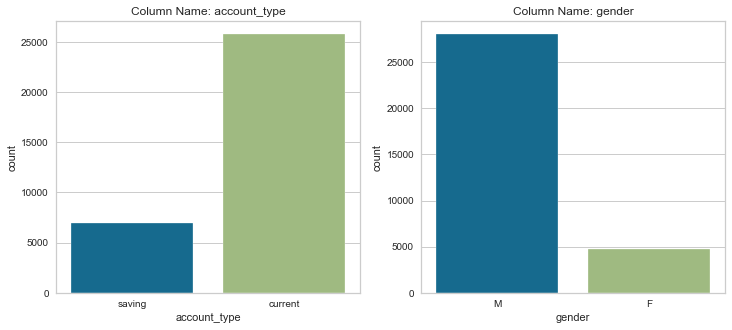

In [85]:
n=0
cat_cols = []
for col in cc_spent_train.select_dtypes("object"):
    cat_cols.append(col)
    
fig, ax = plt.subplots(1,2, squeeze=False, figsize=(12,5))
for row in range(1):
    for col in range(2):
        g = sns.countplot(cc_spent_train[cat_cols[n]], ax=ax[row][col])
        
        
        ax[row,col].set_title("Column Name: {}".format(cat_cols[n], fontsize=12.0))
        n += 1
plt.show();

<b><font color='green'>Inferences from categorical features</font></b>
* Account type is of 'savings' and 'current'. 'current' account is mostly held by customers than savings account.

* Males are mostly spending credit/debit cards then Females.

<b><font color='green'> Distribution of continuous features</font></b>

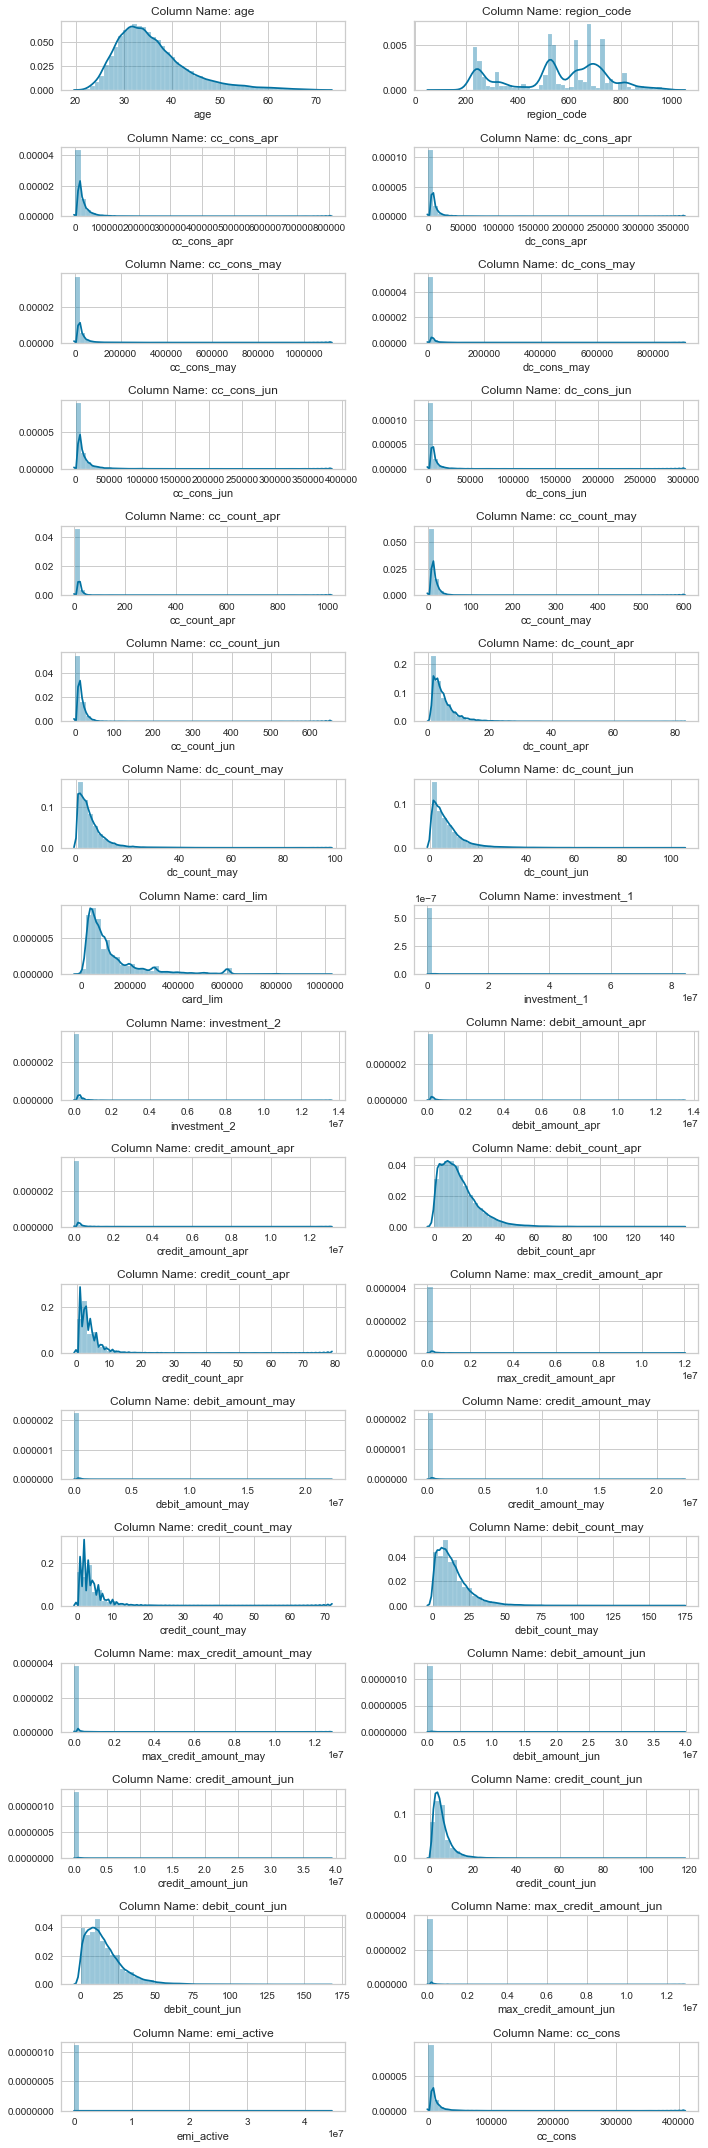

In [86]:
n=0
cont_cols = []
for col in cc_spent_train.select_dtypes(["int64","float64"]):
    cont_cols.append(col)
    
fig, ax = plt.subplots(17,2, squeeze=False, figsize=(10,30))
for row in range(17):
    for col in range(2):
        g = sns.distplot(cc_spent_train[cont_cols[n]], ax=ax[row][col])
        
        
        ax[row,col].set_title("Column Name: {}".format(cont_cols[n], fontsize=15.0))
        n += 1
plt.tight_layout()
plt.show();

<b><font color='green'> Knowing the Skewness and Kurtosis of features</font></b>

<b><font color='green'> Skewness</font></b> : Skewness is a measure of the symmetry in a distribution.  A symmetrical dataset will have a skewness equal to 0.  So, a normal distribution will have a skewness of 0.   Skewness essentially measures the relative size of the two tails. 
    
<b><font color='green'> Kurtosis</font></b> : Kurtosis is a measure of the combined sizes of the two tails.
It measusres the amount of probability in the tails. The value is often compared to the kurtosis
of the normal distribution , which is equal to 3. If the kurtosis is greater than 3, then the dataset
has heavier tails than a normal distribution.

Let us plot the skewed value and kurtosis value associated with each feature and get the inferences.

In [87]:
skew_dict = {}
kurtosis_dict = {}
for cols in cc_spent_train[cont_cols]:
    skew_dict[cols] = cc_spent_train[cols].skew()
    kurtosis_dict[cols] = cc_spent_train[cols].kurt()

In [88]:
skew_dict

{'age': 1.228728971308247,
 'region_code': -0.34401135981039316,
 'cc_cons_apr': 6.379906515580093,
 'dc_cons_apr': 10.243818171774347,
 'cc_cons_may': 8.90341669801851,
 'dc_cons_may': 24.988371593451,
 'cc_cons_jun': 6.587022885820148,
 'dc_cons_jun': 10.216406562896172,
 'cc_count_apr': 31.712810417067114,
 'cc_count_may': 9.269978944777423,
 'cc_count_jun': 7.085759253549538,
 'dc_count_apr': 3.5661228375746052,
 'dc_count_may': 3.230106626003014,
 'dc_count_jun': 3.0225681790028665,
 'card_lim': 2.4064120663475563,
 'investment_1': 39.75544025395155,
 'investment_2': 27.82833578203329,
 'debit_amount_apr': 40.76130449369575,
 'credit_amount_apr': 38.33168201471562,
 'debit_count_apr': 1.635130724923982,
 'credit_count_apr': 3.3604778715518693,
 'max_credit_amount_apr': 55.31443763241461,
 'debit_amount_may': 68.67120155137812,
 'credit_amount_may': 59.59550133562112,
 'credit_count_may': 3.380390972208716,
 'debit_count_may': 1.847638238667958,
 'max_credit_amount_may': 57.1851987

In [89]:
skew_df = pd.DataFrame([skew_dict])
skew_trans_df = skew_df.T

In [90]:
skew_trans_df.columns = ['skewed_value']

In [91]:
skew_trans_df = skew_trans_df.sort_values(ascending=False,by=['skewed_value'])

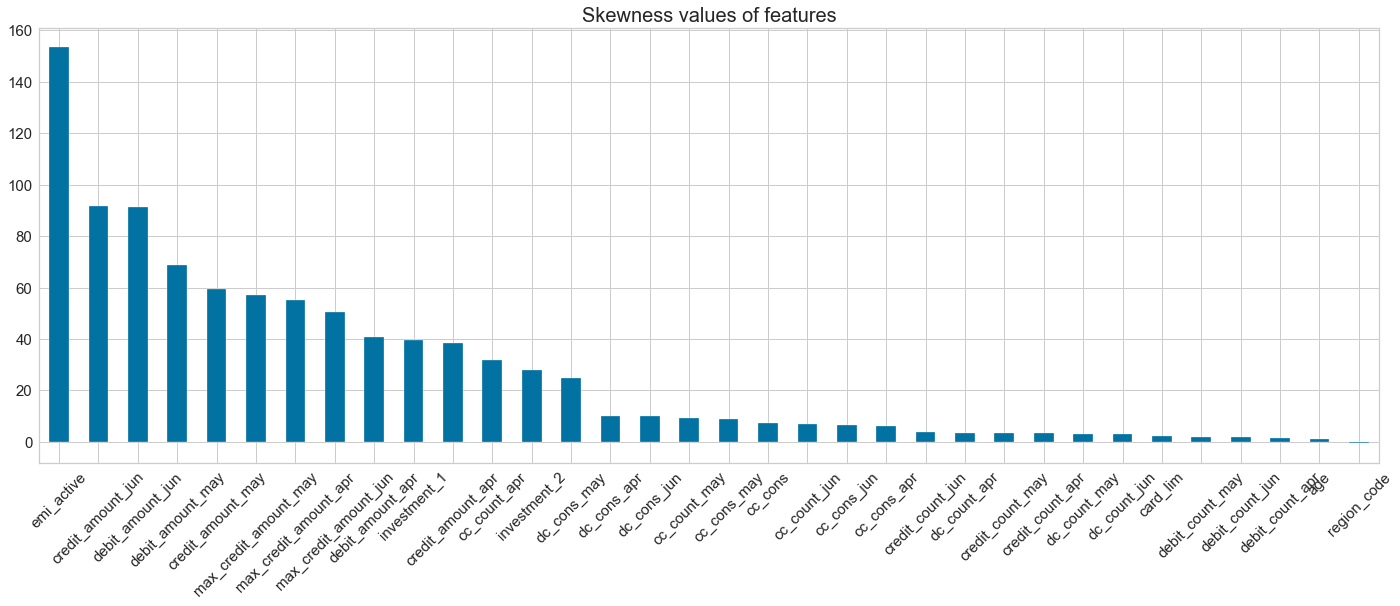

In [97]:
skew_trans_df.plot(kind='bar',figsize=(24,8),fontsize=15)
plt.legend("")
plt.xticks(rotation=45)
plt.title("Skewness values of features",fontsize=20)
plt.show()

<b><font color='green'> Inferences from above Skewness Plot</font></b>

* If skew value for features is < 0.5 it means it is symmetric. The above distplot also
depicts the column 'region_code' being symmetric. 
* While the other features have high skewness in them , column "emi_active" and "age" are having highest skewness among them .If skew value > 1 , then feature is highly skewed towards right.
* Basic way to calculates skewness mathematically, is used to use variance formula but the power is needs to be changed to 3 from 2.

In [93]:
# Converting Kurtosis_dict to Kurtosis dataframe
kurtosis_df = pd.DataFrame([kurtosis_dict])
kurtosis_trans_df = kurtosis_df.T


In [94]:
kurtosis_trans_df.columns = ['kurtosis_value']

In [95]:
# Sorting values in descending order
kurtosis_trans_df = kurtosis_trans_df.sort_values(ascending=False, by=['kurtosis_value'])

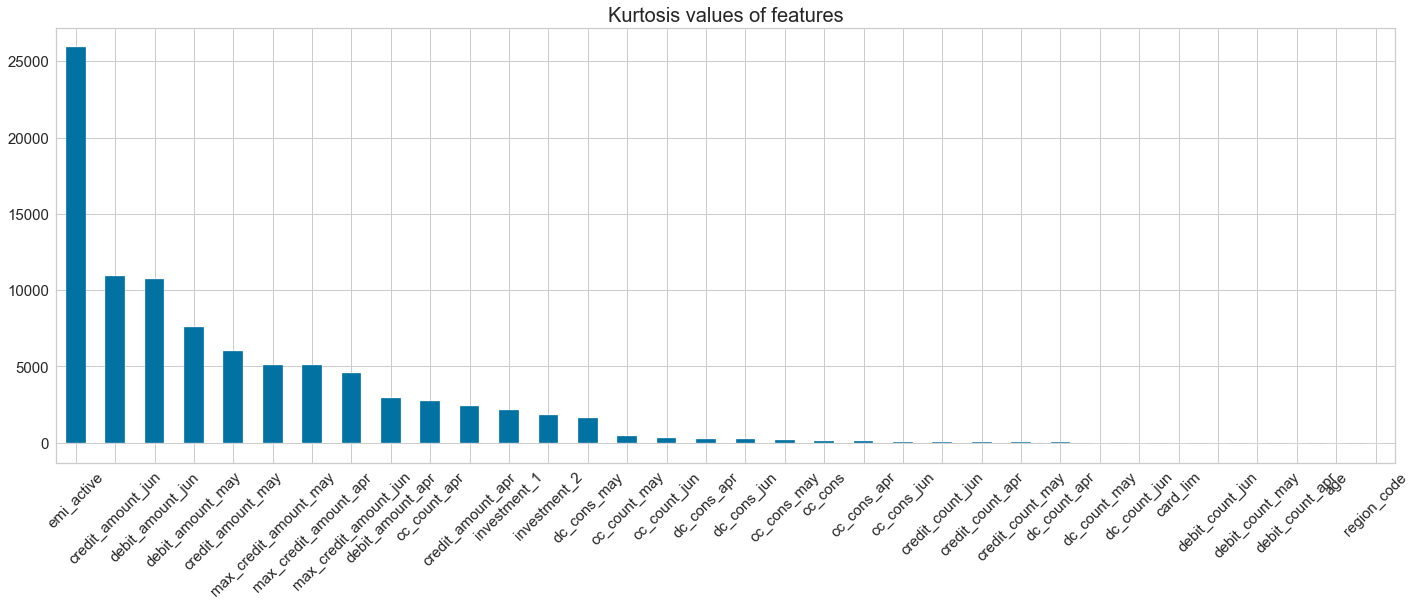

In [98]:
kurtosis_trans_df.plot(kind='bar',figsize=(24,8), fontsize=15)
plt.legend("")
plt.xticks(rotation=45)
plt.title("Kurtosis values of features",fontsize=20)
plt.show()

<b><font color='green'> Inferences from Kurtosis plot</font></b>

* The one which is having spark peak has high kurtosis. One such feature is "emi_active".
* We cannot see any perfect normal distributions from graphs. Hence, the kurtosis values for those 
will be 0.
* The curve get flatter for some features, they follow negative kurtosis.Feature "region_code" 
has negative kurtosis value in it.
* Basic way to calculates kurtosis mathematically, is used to use variance formula but the power is needs to be changed to 4 from 2.


<b><font color='green'> Inferences from continuous features</font></b>

These are mostly right-skewed and some have high kurtosis among them only exception to this feature "region_code",
which has negative skewness that means it follows symmetry and it is having flatter curve, as the kurtosis value says it.

<b><font color='green'>Analysis on the categorical features with the target (cc_cons) </font></b>

##### <font color='green'>Relationship between the account types and the credit card spent for next 3 months</font>

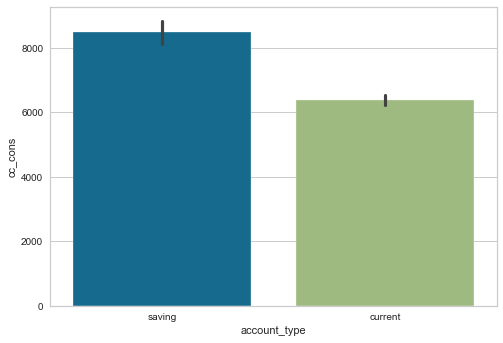

In [99]:
sns.barplot('account_type','cc_cons',data=cc_spent_train)

Cardholders are mainly using savings account type for spending credit card for next 3 months.

Feature "Gender" would not help us in predicting the spending pattern of credit card. Hence, we won't be
analysis it.

##### <font color='green'> How age is a factor in knowning the credit card spend pattern??</font>

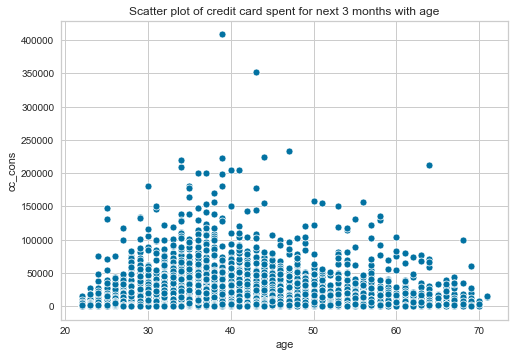

In [100]:
ax = sns.scatterplot(x='age',y='cc_cons', data=cc_spent_train)
plt.title("Scatter plot of credit card spent for next 3 months with age")
plt.show()

As we can see from the figure, the plot is pretty messy for the age group 25-75. That means this is the group
which will be spending the most and the amount spent would be < 250000.

Let bin the age column for easy understanding and visualization.

In [101]:
print("Min Age of consumers' :",min(cc_spent_train['age']))
print("Max Age of consumers' :",max(cc_spent_train['age']))

Min Age of consumers' : 22
Max Age of consumers' : 71


<b> Age bins</b>

In [104]:
cc_spent_train['age_bins'] = pd.cut(cc_spent_train.age,bins=[21,31,41,51,61,72],labels=['Adult','Middle-Aged-I','Middle-Aged-II','Middle-Aged-III','Old Aged'])

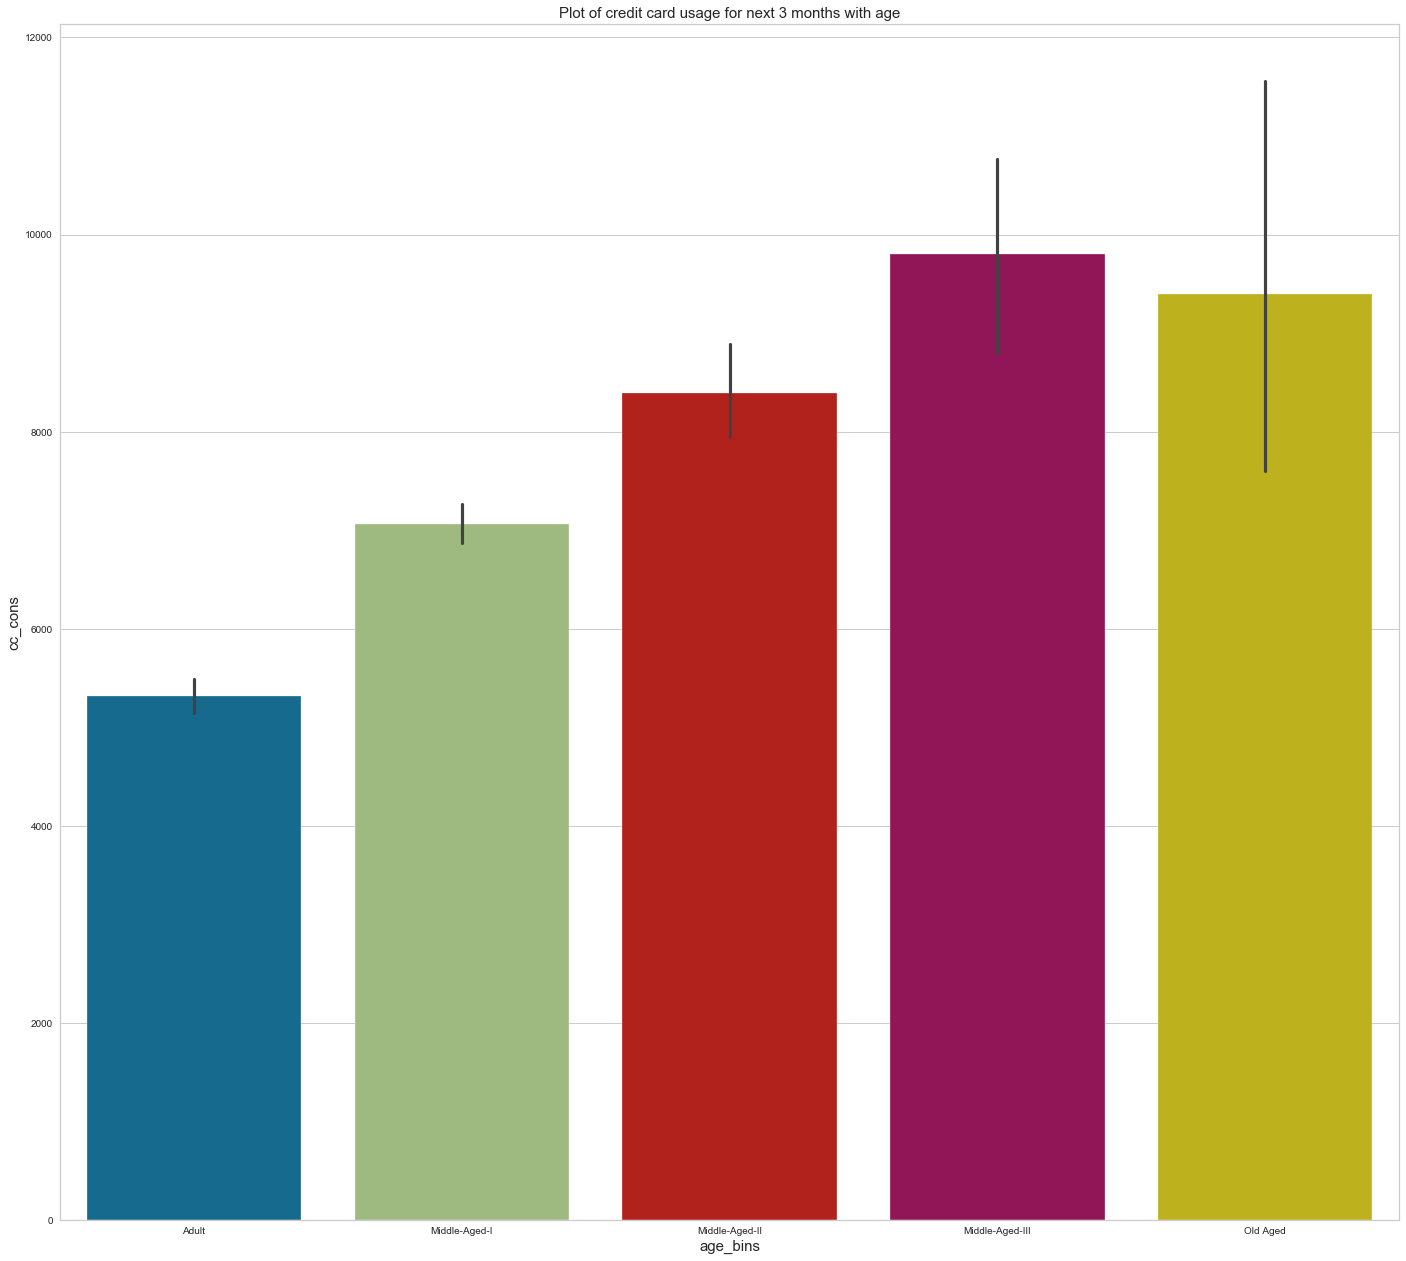

In [105]:
fig, ax = plt.subplots(figsize=(24,22))
sns.barplot('age_bins','cc_cons',data=cc_spent_train, ax=ax)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('cc_cons',fontsize=15)
plt.title("Plot of credit card usage for next 3 months with age",fontsize=15)
plt.show()

We observe that consumers who belong to Middle-Aged-III group comprising of ages 51-61 are the ones who
will be spending a lot of credit amount in next few months, followed by Old Aged Group and Middle-Aged-II.

##### <font color='green'> How maximum credit limit allocated is categorised for different age groups?</font>

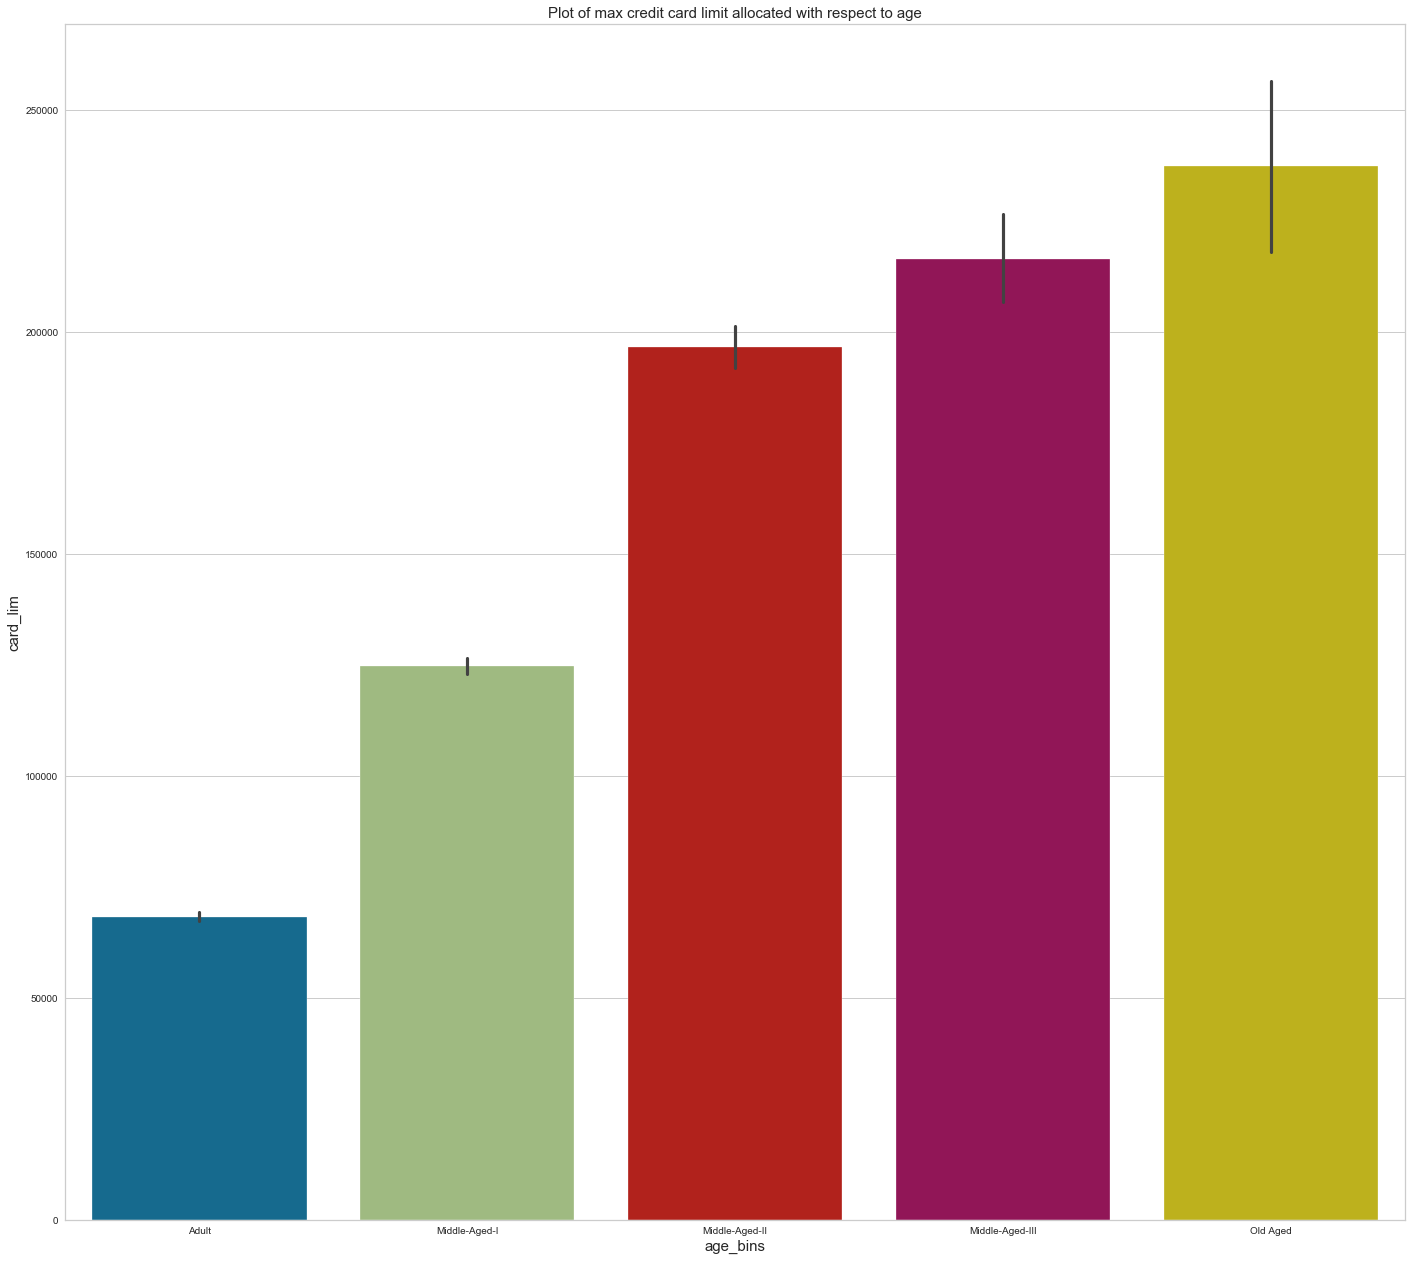

In [106]:
fig, ax = plt.subplots(figsize=(24,22))
sns.barplot('age_bins','card_lim',data=cc_spent_train, ax=ax)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('card_lim', fontsize=15)
plt.title("Plot of max credit card limit allocated with respect to age",fontsize=15)
plt.show()

We see that as the age increases the credit limit for consumers is also increasing. Also, it can be
the older people are maintaining good track record of holding credit cards.

##### <font color='green'> Analysing the debt increase with age</font>

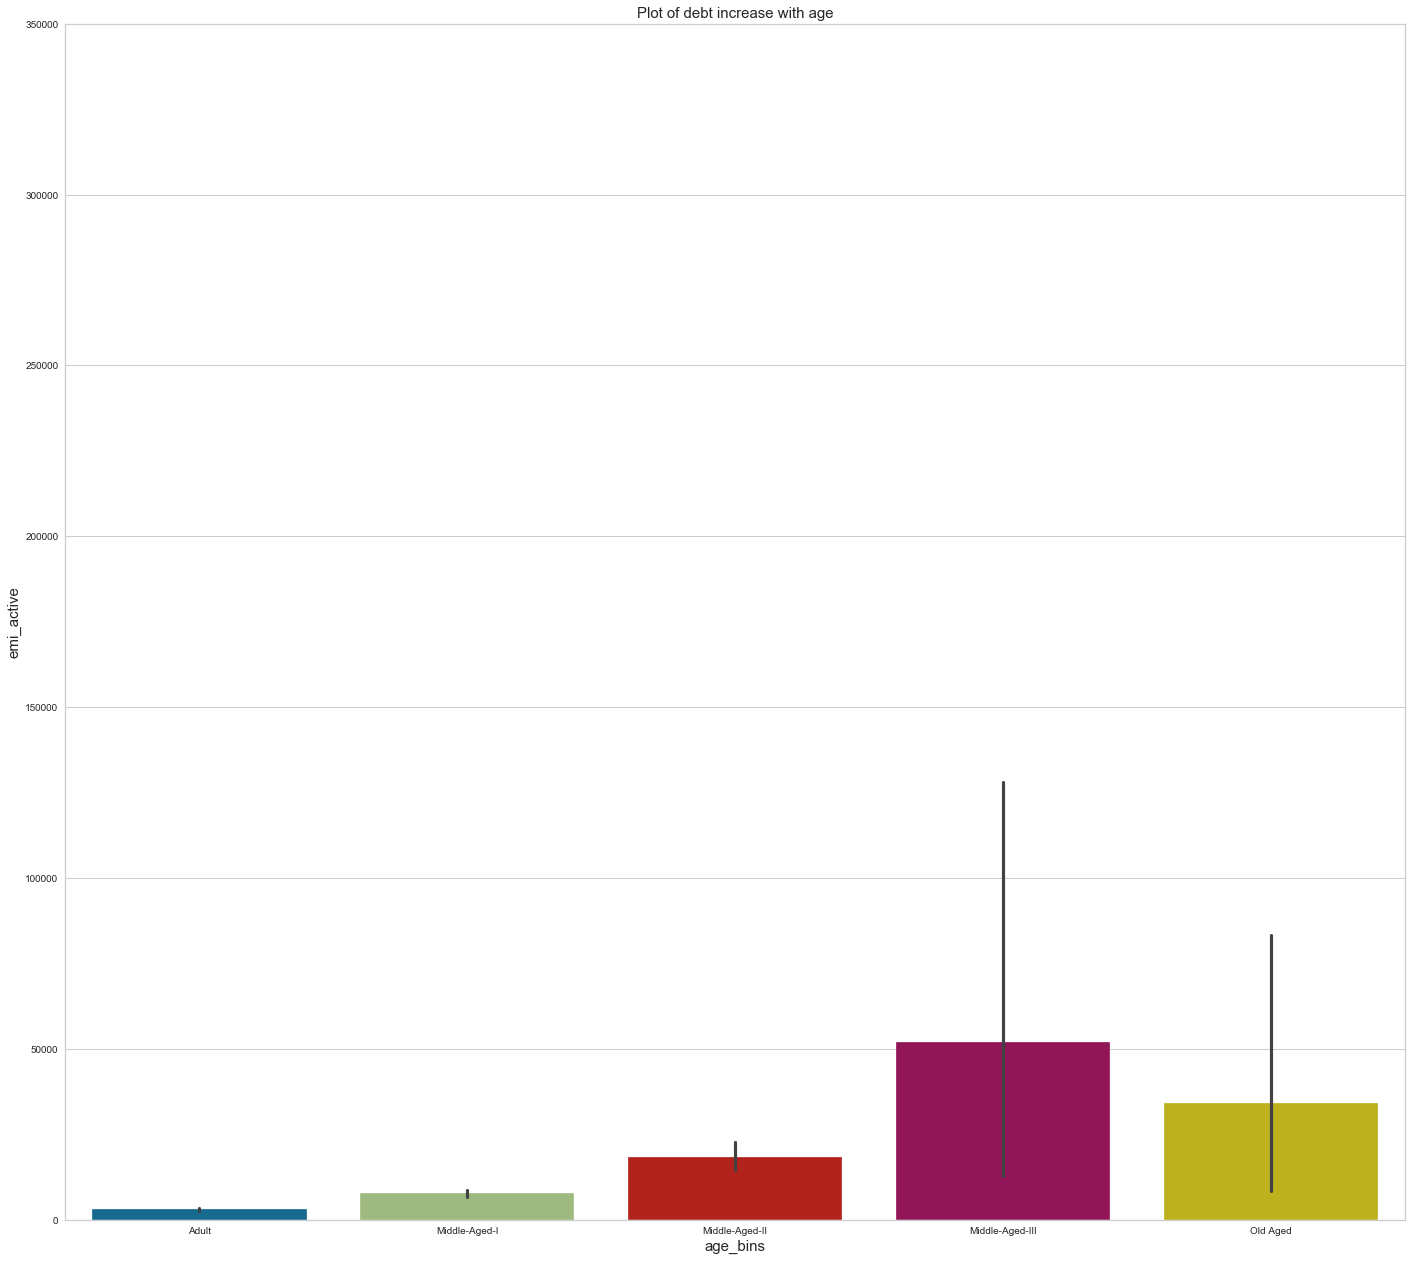

In [107]:
fig, ax = plt.subplots(figsize=(24,22))
sns.barplot('age_bins','emi_active',data=cc_spent_train, ax=ax)
ax.set_ylim(0,350000)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('emi_active', fontsize=15)
plt.title("Plot of debt increase with age",fontsize=15)
plt.show()

In this scenario, the debts are nothing but the emi's which the consumers owe to other banks. The debt's 
increase over age is following a left-skewed distribution. Where it reaches it peaks for the Middle-Aged-III age group
and declines for the Old Aged.

##### <font color='green'> Anytime analyzed why such changes of credit card usage and debts are occuring drastically??</font>

1. Credit cards help users to smooth over shocks.
2. By revolving debt over short and long terms, credit cards are a way of allocating life-cycle
consumption.
3. As a means of payment, spending on credit cards forms part of consumer expenditures.

##### <font color='green'> Which regions contribute most to spending of credit cards?</font>

Glimpse of the "region_code" column

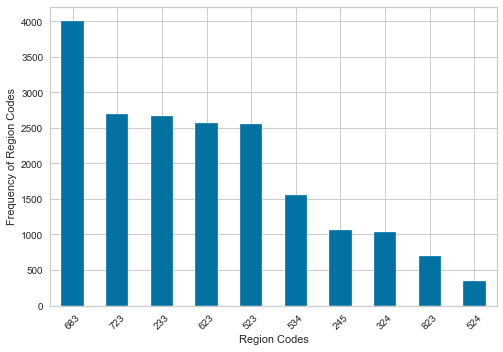

In [108]:
cc_spent_train['region_code'].value_counts()[:10].plot.bar()
plt.xticks(rotation=45)
plt.xlabel('Region Codes')
plt.ylabel('Frequency of Region Codes')
plt.show()

We see that cardholders/consumers are mostly from 683 region code followed by 723,233,623 and 523.

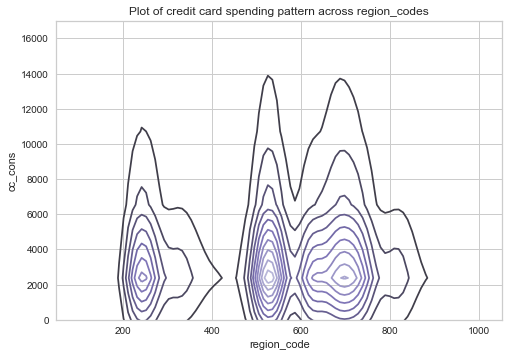

In [109]:
ax = sns.kdeplot(cc_spent_train['region_code'], cc_spent_train['cc_cons'], n_levels=10, cmap="Purples_d")
plt.ylim(0,17000)
plt.title('Plot of credit card spending pattern across region_codes')
plt.show()

From above figure, we can infer that for region_code between 500-600, the spaces between lines are quite dense which 
means many cardholders belong to these region who spend the most. While for regions between 600-800,
the lines are apart when less carholders spend in this region. Also, near 150-200 you again see some
dense region where the usage of credit cards is more.

#### <font color='green'> Understanding the pattern of credit card spent across April, May and June </font>

In [110]:
def cc_dc_pattern(df,col1,col2,col3,col4,col5,col6,low_xl,high_xl):
    sns.set()
    fig, (ax1,ax2) = plt.subplots(2, 1, sharex=True,figsize=(12,8))
    ax1 = plt.subplot(2, 1, 1)
    ax1 = sns.distplot(df[col1], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label=col1)
    ax1= sns.distplot(df[col2],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col2)
    ax1= sns.distplot(df[col3],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col3)
    ax1.set_xlabel("")
    ax1.set_title("Credit Cards/Amount in April, May and June months")
    plt.xlim(low_xl, high_xl)
    
    print("")
    
    ax2 = plt.subplot(2, 1, 2)
    ax2 = sns.distplot(df[col4], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label=col4)
    ax2= sns.distplot(df[col5],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col5)
    ax2= sns.distplot(df[col6],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col6)
    ax2.set_xlabel("")
    ax2.set_title("Debit Cards/Amount in April, May and June months")
    plt.xlim(low_xl, high_xl)
    
    plt.tight_layout()
    plt.show()
    
    
    
    

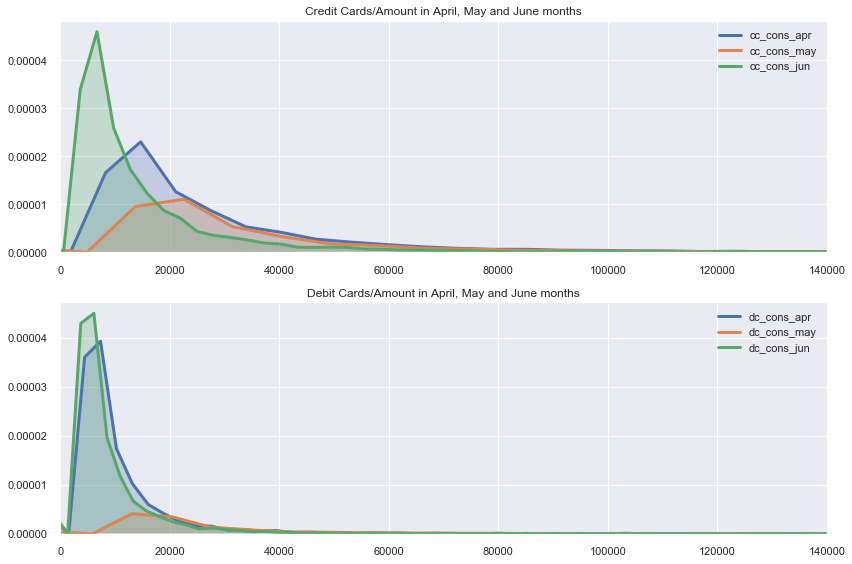

In [111]:
cc_dc_pattern(cc_spent_train,'cc_cons_apr','cc_cons_may','cc_cons_jun','dc_cons_apr','dc_cons_may',
              'dc_cons_jun',0,140000)

In [112]:
cc_cons_lst = ['cc_cons_apr','cc_cons_may','cc_cons_jun']
dc_cons_lst = ['dc_cons_apr','dc_cons_may','dc_cons_jun']

In [113]:
cc_spent_train[cc_cons_lst].describe()


,cc_cons_apr,cc_cons_may,cc_cons_jun
count,32785.000000,3.278500e+04,32785.000000
mean,16653.277354,1.441537e+04,9024.848361
std,25120.441735,2.364551e+04,15675.752215
min,233.970000,1.030000e+02,51.000000
25%,3712.000000,2.981940e+03,1636.750000
50%,8911.300000,7.334930e+03,4147.000000
75%,19919.930000,1.684971e+04,10127.000000
max,804712.580000,1.117246e+06,382914.100000


<b><font color='darkpink'>Credit Cards spending pattern(April, May and June)</font></b>
1. We see that deviation for month of June is around 15000+ compared to May and April months which have deviations of 25000+.
2. So, we see a narrow curve in June in comparison to May and June months.
3. Also, IQR values for June Month is about 8000+ and for May and April is about 13000+ and 16000+ respectively.


In [114]:
cc_spent_train[dc_cons_lst].describe()

,dc_cons_apr,dc_cons_may,dc_cons_jun
count,32785.000000,32785.000000,32785.000000
mean,5140.519050,5244.473021,4349.191808
std,8545.030212,10725.803519,7208.633776
min,10.010000,20.000000,23.000000
25%,1294.000000,1246.843948,1232.000000
50%,2922.142401,2796.252000,2459.258510
75%,5910.195820,5666.150000,4806.750009
max,366223.160000,911223.490000,301991.940000


<b><font color='darkpink'>Debit Cards spending pattern(April, May and June)</font></b>

1. The deviation for April and June month is about 8000+ and 7000+ , as compared to April and May, which shows people have spent very less debit cards
compared to April and May.
2. Also, we observe that the curves are right-skewed as the mean are greater than median.
3. IQR is about 3000+ and 4500+ for June , April and May months respectively, which means the debit spent in these 3 months lie in this ranges.

<b><font color='darkpink'>Debit/ Card Cards spending pattern(April, May and June)</font></b>

1. From statistics, we see that the min amount be debit spent is 10 as compared to 51 credit spent.
2. Also, the IQR pattern for debit is around 3000-4500+ with few exceptions to it spending around 300000+ a month, when it comes to credit card spent amount spend is ranging about 8000-16000+ 
a month and max around 110000+ a month.
3. Hence, we say that the credit cards are spent more than the debit cards.

<b><font color='green'>Debit/Credit card usage pattern individually for 3 months through mean and std</font></b>

In [115]:
# Credit cards spent(mean and std)

cc_spent_train['cc_spent_monthly_average'] =(cc_spent_train['cc_cons_apr'] + cc_spent_train['cc_cons_may'] + cc_spent_train['cc_cons_jun']) / 3
cc_spent_train['cc_spent_monthly_deviation'] = cc_spent_train[cc_cons_lst].std(axis=1)

In [116]:
# Creating same features in test as well
cc_spent_test['cc_spent_monthly_average'] =(cc_spent_test['cc_cons_apr'] + cc_spent_test['cc_cons_may'] + cc_spent_test['cc_cons_jun']) / 3
cc_spent_test['cc_spent_monthly_deviation'] = cc_spent_test[cc_cons_lst].std(axis=1)

In [117]:
# Finding the correlation matrix w.r.t target 'cc_cons'
cc_cons_corr_lst= ['cc_spent_monthly_average', 'cc_spent_monthly_deviation','cc_cons']
cc_spent_train[cc_cons_corr_lst].corr()

,cc_spent_monthly_average,cc_spent_monthly_deviation,cc_cons
cc_spent_monthly_average,1.000000,0.823902,0.432805
cc_spent_monthly_deviation,0.823902,1.000000,0.289022
cc_cons,0.432805,0.289022,1.000000


We see that 43% of consumers are likely to spend in the same way for next 3 months . However, 28% of consumers
are likely to be inconsistent in their spending pattern for avg of next 3 months.

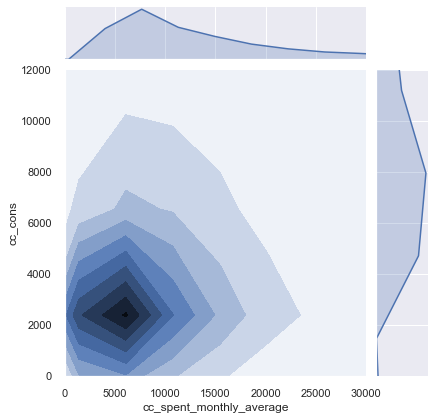

In [118]:
plot = sns.jointplot(x='cc_spent_monthly_average',y='cc_cons',data=cc_spent_train, kind='kde')
plot.ax_marg_x.set_xlim(0,30000)
plot.ax_marg_y.set_ylim(0,12000)
plt.show()

The above graph shows a darker region around 5000-10000, which is nothing but the credit amount being
spent on an average basis. However, the credit amount spent for next 3 months is around 2000-2500 range.
This indicates many consumers are spending credit card in this region. As the shape of the figure expands,
it becomes lighter and lighter which means there are few consumers spending amount in this region. 

##### <font color='green'> Credit card spending ratio by checking the card limit</font>

The credit card spending ratio is calculated by dividing the average amount spent on credit card to the credit card limit allocated .

In [119]:
cc_spent_train['cc_spent_ratio'] = cc_spent_train['cc_spent_monthly_average'] / cc_spent_train['card_lim']

In [120]:
# Retaining the decimal places to only 4
cc_spent_train['cc_spent_ratio'] = cc_spent_train['cc_spent_ratio'].round(4) * 100

In [121]:
cc_spent_train['cc_spent_ratio'].head()

0     1.95
1    15.85
2    17.25
3     1.93
4     1.93
Name: cc_spent_ratio, dtype: float64

Let us now find out the relationship of the spent ratio with the credit card spent in next 3 months.

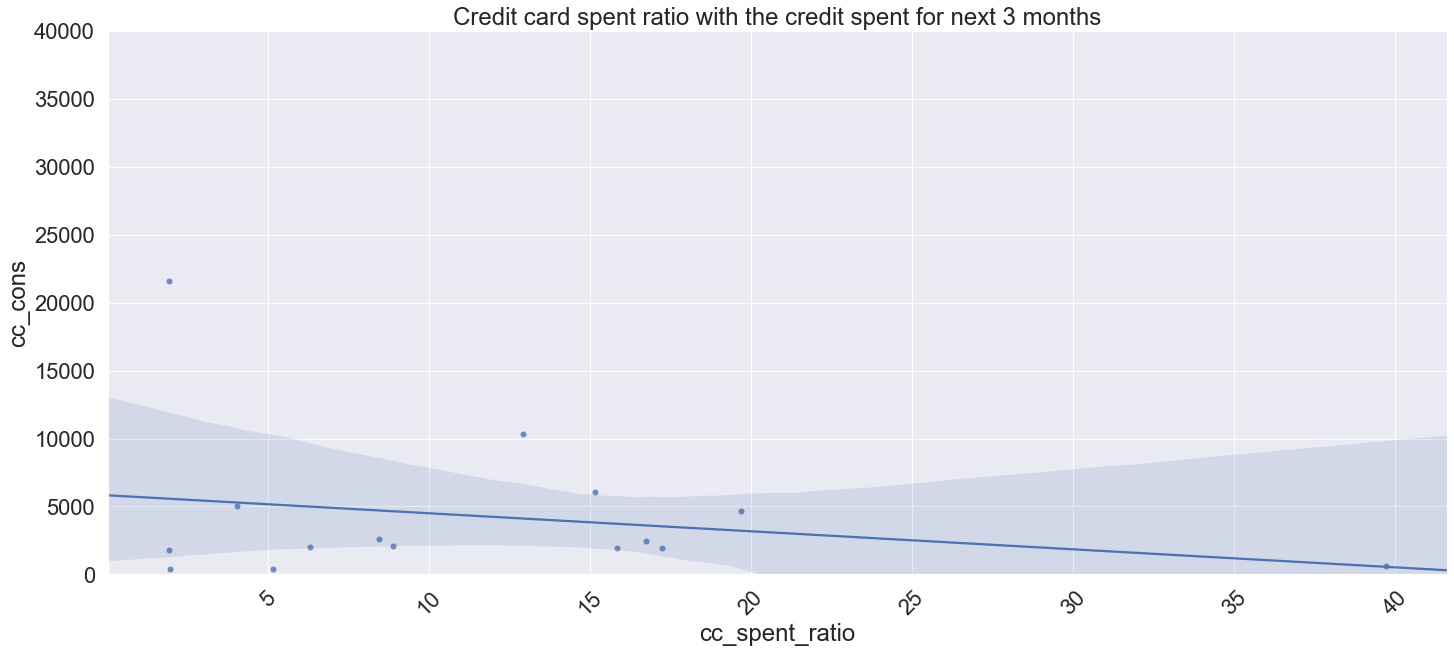

In [122]:
sns.set(rc={'figure.figsize':(24,10)}, font_scale=2)
ax = sns.regplot(x='cc_spent_ratio', y='cc_cons', data=cc_spent_train[:15])
ax.set(ylim=(0,40000))
plt.xticks(rotation=45)
plt.title("Credit card spent ratio with the credit spent for next 3 months")
plt.show()

We are observing that as the credit spend ratio increases the credit amount being spent for next
3 months is decreasing drastically reaching almost to 0 value.

##### <font color='green'> How increase in credit spent causes increase in debt ?</font>

We often foresight that if the credit amount being spent increases, there might be chances that the
debt also increases. Let us understand this better through a graph.

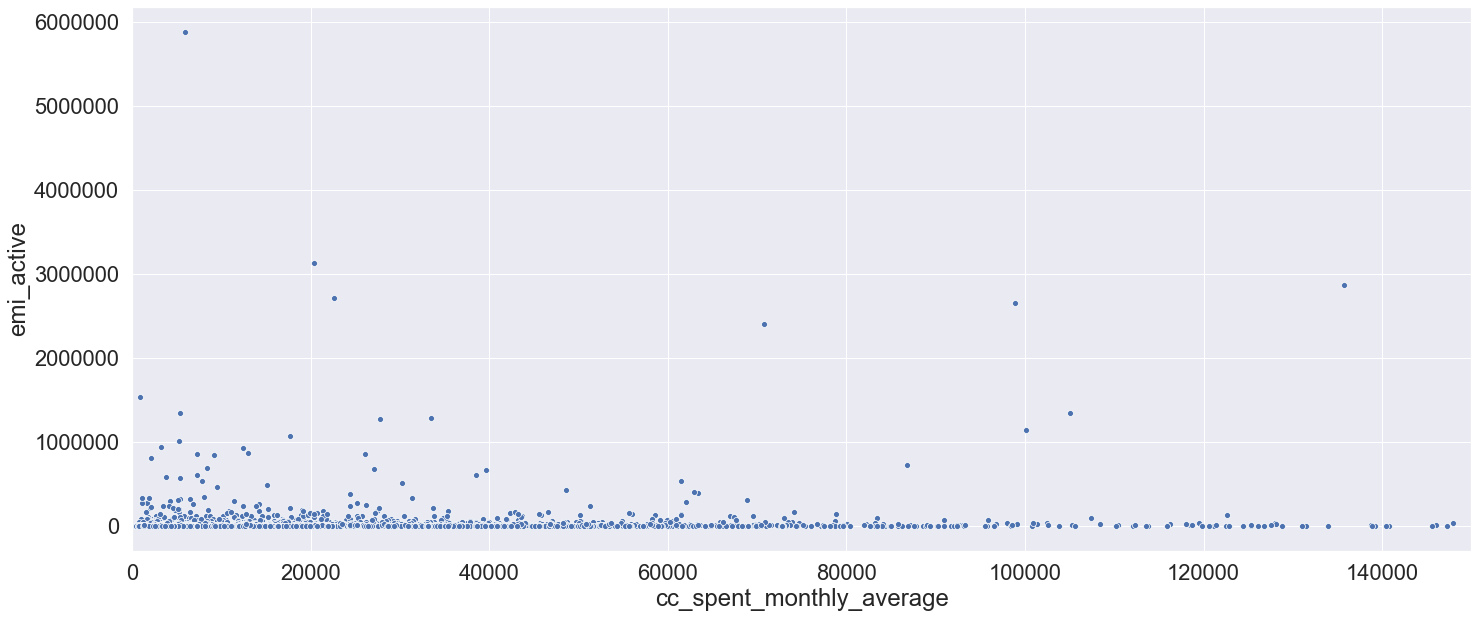

In [123]:
ax = sns.scatterplot(x='cc_spent_monthly_average',y='emi_active',data=cc_spent_train[:15000])
ax.set_xlim(0,150000)
plt.show()

Above graph says , even  though the rate of spending credit card is increasing across the scale
the active loans/debts being paid is not enormous , except few cases that may lead to bankruptcy.

##### <font color='green'> Debit card spending pattern by consumers</font>

In [124]:
## Debit Cards
# Traind data
cc_spent_train['dc_spent_monthly_average'] =(cc_spent_train['dc_cons_apr'] + cc_spent_train['dc_cons_may'] + cc_spent_train['dc_cons_jun']) / 3
cc_spent_train['dc_spent_monthly_deviation'] = cc_spent_train[dc_cons_lst].std(axis=1)

In [125]:
# Test data
cc_spent_test['dc_spent_monthly_average'] =(cc_spent_test['dc_cons_apr'] + cc_spent_test['dc_cons_may'] + cc_spent_test['dc_cons_jun']) / 3
cc_spent_test['dc_spent_monthly_deviation'] = cc_spent_test[dc_cons_lst].std(axis=1)

In [126]:
# Finding the correlation matrix w.r.t target 'cc_cons'
dc_cons_corr_lst= ['dc_spent_monthly_average','dc_spent_monthly_deviation','cc_cons']
cc_spent_train[dc_cons_corr_lst].corr()

,dc_spent_monthly_average,dc_spent_monthly_deviation,cc_cons
dc_spent_monthly_average,1.000000,0.891889,0.049937
dc_spent_monthly_deviation,0.891889,1.000000,0.029873
cc_cons,0.049937,0.029873,1.000000


We hardly see any correlation of debit cards with the spending pattern of credit card for the next 3 months.

Let us see the correlation between monthly average of credit card spent and debit card spent.

In [127]:
cc_dc_cons = ['cc_spent_monthly_average','dc_spent_monthly_average','cc_spent_monthly_deviation',
              'dc_spent_monthly_deviation']
cc_spent_train[cc_dc_cons].corr()


,cc_spent_monthly_average,dc_spent_monthly_average,cc_spent_monthly_deviation,dc_spent_monthly_deviation
cc_spent_monthly_average,1.000000,0.081780,0.823902,0.059904
dc_spent_monthly_average,0.081780,1.000000,0.072937,0.891889
cc_spent_monthly_deviation,0.823902,0.072937,1.000000,0.056989
dc_spent_monthly_deviation,0.059904,0.891889,0.056989,1.000000


We aren't finding any correlation between credit card spent on an average month and debit card spent on an average monthly basis.

#### <font color='green'>Understanding the credit card transactions for the month of April, May and June </font>

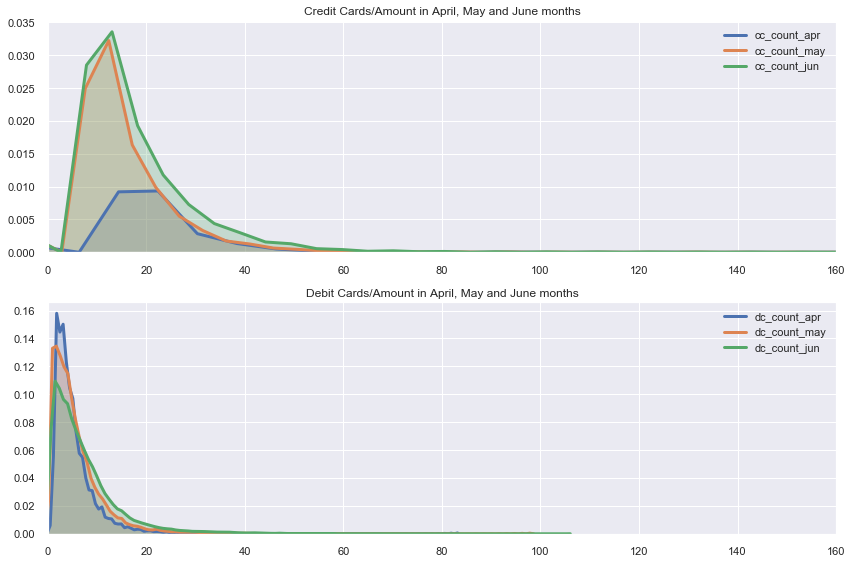

In [128]:
cc_dc_pattern(cc_spent_train,'cc_count_apr','cc_count_may','cc_count_jun','dc_count_apr',
             'dc_count_may','dc_count_jun',0,160)


In [129]:
cc_count_lst = ['cc_count_apr','cc_count_may','cc_count_jun']
dc_count_lst = ['dc_count_apr','dc_count_may','dc_count_jun']

In [130]:
cc_spent_train[cc_count_lst].describe()

,cc_count_apr,cc_count_may,cc_count_jun
count,32785.000000,32785.000000,32785.000000
mean,8.922407,9.351553,12.051350
std,10.494230,9.542418,11.519487
min,1.000000,1.000000,1.000000
25%,3.000000,3.000000,4.000000
50%,6.000000,7.000000,9.000000
75%,12.000000,13.000000,16.000000
max,1012.000000,601.000000,653.000000


<b><font color='darkpink'>Number of Credit card transactions in April, May and June</font></b>

The transactions for May month is quite sharp , as there are less deviation in the pattern. That means most people are
doing transactions in the same range. For June month , also it follows the same pattern.When you see the April Month, the max value is quite large. So, it means there are
high transactions in this month.

In [131]:
cc_spent_train[dc_count_lst].describe()

,dc_count_apr,dc_count_may,dc_count_jun
count,32785.000000,32785.000000,32785.000000
mean,4.746937,5.907033,7.423939
std,4.595877,5.723291,7.399570
min,1.000000,1.000000,1.000000
25%,2.000000,2.059209,2.731847
50%,3.500000,4.268067,5.390553
75%,6.000000,7.564135,9.687017
max,82.000000,97.000000,104.000000


<b><font color='darkpink'>Number of Debit card transactions in April, May and June</font></b>

June month has little variation compared to the rest two. Hence, it has maximum debit card transactions
done.

<b><font color='dark pink'>Comparison of Debit/Credit Transactions for April, May and June months</font>

1. Credit transactions are carried out more than the debit transactions.
2. Credit transaction for April are carried out in the range of 9 with a maximum transaction reaching
upto 1000+. While the debit transactions done by people is around 7 with the max one reaching 104 
in the June month.
3. The curves in Debit transactions all overlap each other and are right skewed.

<b><font color='dark pink'> Debit/Card Transactions carried out on an individual level</font></b>

In [132]:
# Credit Transactions
# Train data
cc_spent_train['cc_trans_monthly_avg'] =(cc_spent_train['cc_count_apr'] + cc_spent_train['cc_count_may'] + cc_spent_train['cc_count_jun']) / 3
cc_spent_train['cc_trans_monthly_deviation'] = cc_spent_train[cc_count_lst].std(axis=1)

In [133]:
# Credit Transactions
# Test data
cc_spent_test['cc_trans_monthly_avg'] =(cc_spent_test['cc_count_apr'] + cc_spent_test['cc_count_may'] + cc_spent_test['cc_count_jun']) / 3
cc_spent_test['cc_trans_monthly_deviation'] = cc_spent_test[cc_count_lst].std(axis=1)

In [134]:
# Finding the correlation matrix w.r.t target 'cc_cons'
cc_count_corr_lst = ['cc_trans_monthly_avg','cc_trans_monthly_deviation','cc_cons']
cc_spent_train[cc_count_corr_lst].corr()

,cc_trans_monthly_avg,cc_trans_monthly_deviation,cc_cons
cc_trans_monthly_avg,1.000000,0.601027,0.097283
cc_trans_monthly_deviation,0.601027,1.000000,0.057841
cc_cons,0.097283,0.057841,1.000000


We don't observe any relation with credit card transactions helping us predict the credit card spent for next 3 months.

On knowing the credit card transactions, let us calculate the weighted average of credit card amount
being spent , considering the transactions as the weights and get the insights.

In [135]:
# Let us get the weighted average of amount spent by considering weights of transactions
cc_spent_train['weighted_avg_cc_cons'] = ((cc_spent_train['cc_cons_apr'] * cc_spent_train['cc_count_apr'])
                                  + (cc_spent_train['cc_cons_may'] * cc_spent_train['cc_count_may'])
                                  + (cc_spent_train['cc_cons_jun'] * cc_spent_train['cc_count_jun'])) / (cc_spent_train['cc_count_apr'] + cc_spent_train['cc_count_may'] + cc_spent_train['cc_count_jun'])

In [136]:
weigh_avg_cc_lst = ['weighted_avg_cc_cons','cc_cons']
cc_spent_train[weigh_avg_cc_lst].corr()

,weighted_avg_cc_cons,cc_cons
weighted_avg_cc_cons,1.00000,0.42102
cc_cons,0.42102,1.00000


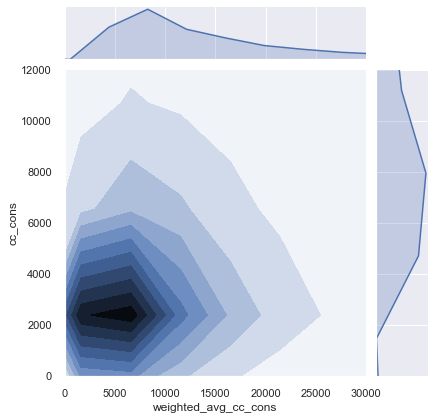

In [137]:
plot = sns.jointplot(x='weighted_avg_cc_cons',y='cc_cons',data=cc_spent_train, kind='kde')
plot.ax_marg_x.set_xlim(0,30000)
plot.ax_marg_y.set_ylim(0,12000)
plt.show()

However, we are observing the same kind of graph through the weighted average as well.

#### <font color='green'> How debit transactions would be helpful in knowing the credit card spending pattern</font>

In [138]:
# Debit Transactions
cc_spent_train['dc_trans_monthly_avg']=  (cc_spent_train['dc_count_apr'] + cc_spent_train['dc_count_may'] + cc_spent_train['dc_count_jun']) / 3
cc_spent_train['dc_trans_monthly_deviation'] = cc_spent_train[dc_count_lst].std(axis=1)

In [139]:
# Finding the correlation matrix w.r.t target 'cc_cons'
dc_count_corr_lst = ['dc_trans_monthly_avg','dc_trans_monthly_deviation','cc_cons']
cc_spent_train[dc_count_corr_lst].corr()

,dc_trans_monthly_avg,dc_trans_monthly_deviation,cc_cons
dc_trans_monthly_avg,1.000000,0.708330,0.010434
dc_trans_monthly_deviation,0.708330,1.000000,0.003407
cc_cons,0.010434,0.003407,1.000000


As with the credit card transactions, we see the same scenario with the debit card as well , no correlation with
the spending pattern . Also, we aren't getting much insights through debit which would help us in 
predicting the credit card amount being spent.

<b><font color='dark pink'> Total amount credited/debited for the months of April, May and June</font></b>


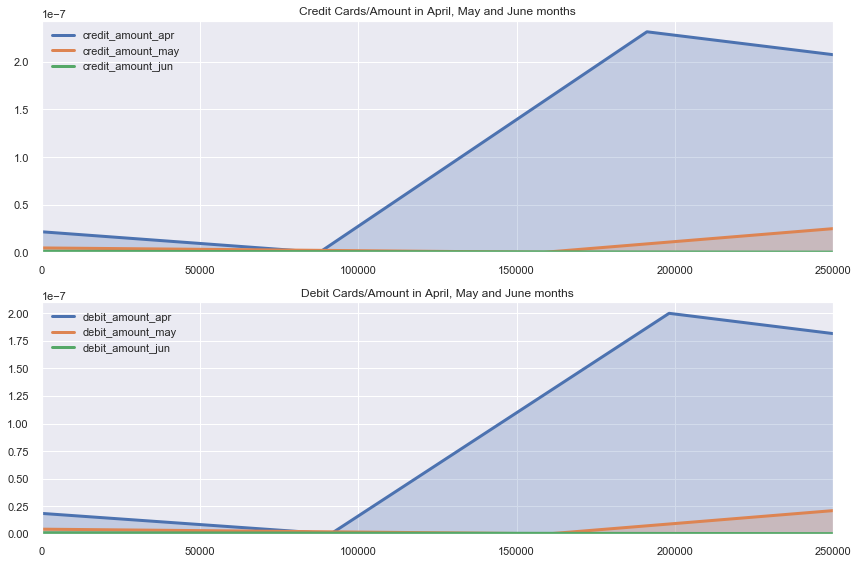

In [140]:
cc_dc_pattern(cc_spent_train,'credit_amount_apr','credit_amount_may','credit_amount_jun',
             'debit_amount_apr','debit_amount_may','debit_amount_jun',0,250000)



In [141]:
credit_amt_lst = ['credit_amount_apr','credit_amount_may','credit_amount_jun']
cc_spent_train[credit_amt_lst].describe()

,credit_amount_apr,credit_amount_may,credit_amount_jun
count,3.278500e+04,3.278500e+04,3.278500e+04
mean,7.080092e+04,7.518128e+04,7.516104e+04
std,1.698905e+05,1.930250e+05,2.993656e+05
min,3.432000e+01,1.061000e+01,1.188000e+01
25%,2.280800e+04,2.250139e+04,2.348800e+04
50%,4.168100e+04,4.327341e+04,4.344100e+04
75%,7.595900e+04,8.508600e+04,8.033100e+04
max,1.310058e+07,2.246350e+07,3.933931e+07


<b><font color='dark pink'> Observations from graph on Total number of credit amount in months of April, May and June</font></b>

1. June month is having wide fluctuation from the months of May and April .
2. When we look at the IQR's for June, May and April respectively we achieve about 56000+, 62000+ and
53000+ respectively. But when it comes to the maximum value of credit amount is upto 1000000+ for April month respectively
which is such a huge gap from 53000+ to 10000000+. Hence, you can see a wider curve for April.

In [142]:
debit_amount_lst = ['debit_amount_apr','debit_amount_may','debit_amount_jun']
cc_spent_train[debit_amount_lst].describe()

,debit_amount_apr,debit_amount_may,debit_amount_jun
count,3.278500e+04,3.278500e+04,3.278500e+04
mean,6.860572e+04,6.506688e+04,7.546393e+04
std,1.600155e+05,1.795343e+05,3.038902e+05
min,4.010000e+00,1.500000e-01,5.230000e+00
25%,2.191040e+04,1.927957e+04,2.437375e+04
50%,4.089699e+04,3.760776e+04,4.541925e+04
75%,7.442132e+04,7.212782e+04,8.246864e+04
max,1.353571e+07,2.230122e+07,3.986881e+07


<b><font color='dark pink'>Observations on Total Debit Amount for months of (Apr,May and June)</font></b>

1. There is an interesting observation in this graph which we haven't come across from the previous
graphs. We see that the min debit amount for may is around -0.15 which means people have execessively spent
from their debit accounts, and there is no debit balance left. To make the balances to  positive, it 
need to credit some amount to their respective accounts, till it reaches some debit amount limits, based
on the type of account they hold "current" or "savings".

2. Some deviation in pattern in observed for June month.

3. April and May months graph almost overlap each other.

<font color='dark pink'><b>Knowing the Credit/Debit Amount spent individually for 3 months</b></font>

In [143]:
# Credit Card
# Monthly Avg
cc_spent_train['cc_amount_monthly_avg'] = (cc_spent_train['credit_amount_apr'] + cc_spent_train['credit_amount_may'] +
                                               cc_spent_train['credit_amount_jun']) / 3
# Std Deviation

cc_spent_train['cc_amount_monthly_std'] = cc_spent_train[credit_amt_lst].std(axis=1)

In [144]:
cc_amt_corr_lst = ['cc_amount_monthly_avg','cc_amount_monthly_std','cc_cons']
cc_spent_train[cc_amt_corr_lst].corr()

,cc_amount_monthly_avg,cc_amount_monthly_std,cc_cons
cc_amount_monthly_avg,1.000000,0.896864,0.101574
cc_amount_monthly_std,0.896864,1.000000,0.078363
cc_cons,0.101574,0.078363,1.000000


Here, too the correlation between monthly avg . credit amount and std. deviation is ~9.5% and ~6.5%
respectively, which is very low. That means the total credit amount doesn't help us in determining the spending pattern.

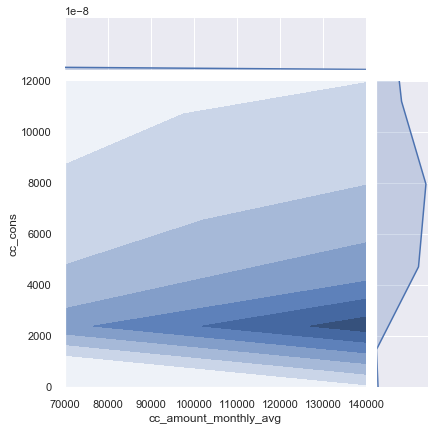

In [173]:
plot = sns.jointplot(x='cc_amount_monthly_avg',y='cc_cons',data=cc_spent_train, kind='kde')
plot.ax_marg_x.set_xlim(70000,140000)
plot.ax_marg_y.set_ylim(0,12000)
plt.show()

Credit amount is mostly spent by consumers on a monthly basis around 3000-4000 and their spending pattern
might decrease to 2000-3000 as the graph signifies it.

##### <font color='green'> Plotting of credit amount with age</font>

Text(0.5, 1.0, 'Plot of credit amount being spent w.r.t age group')

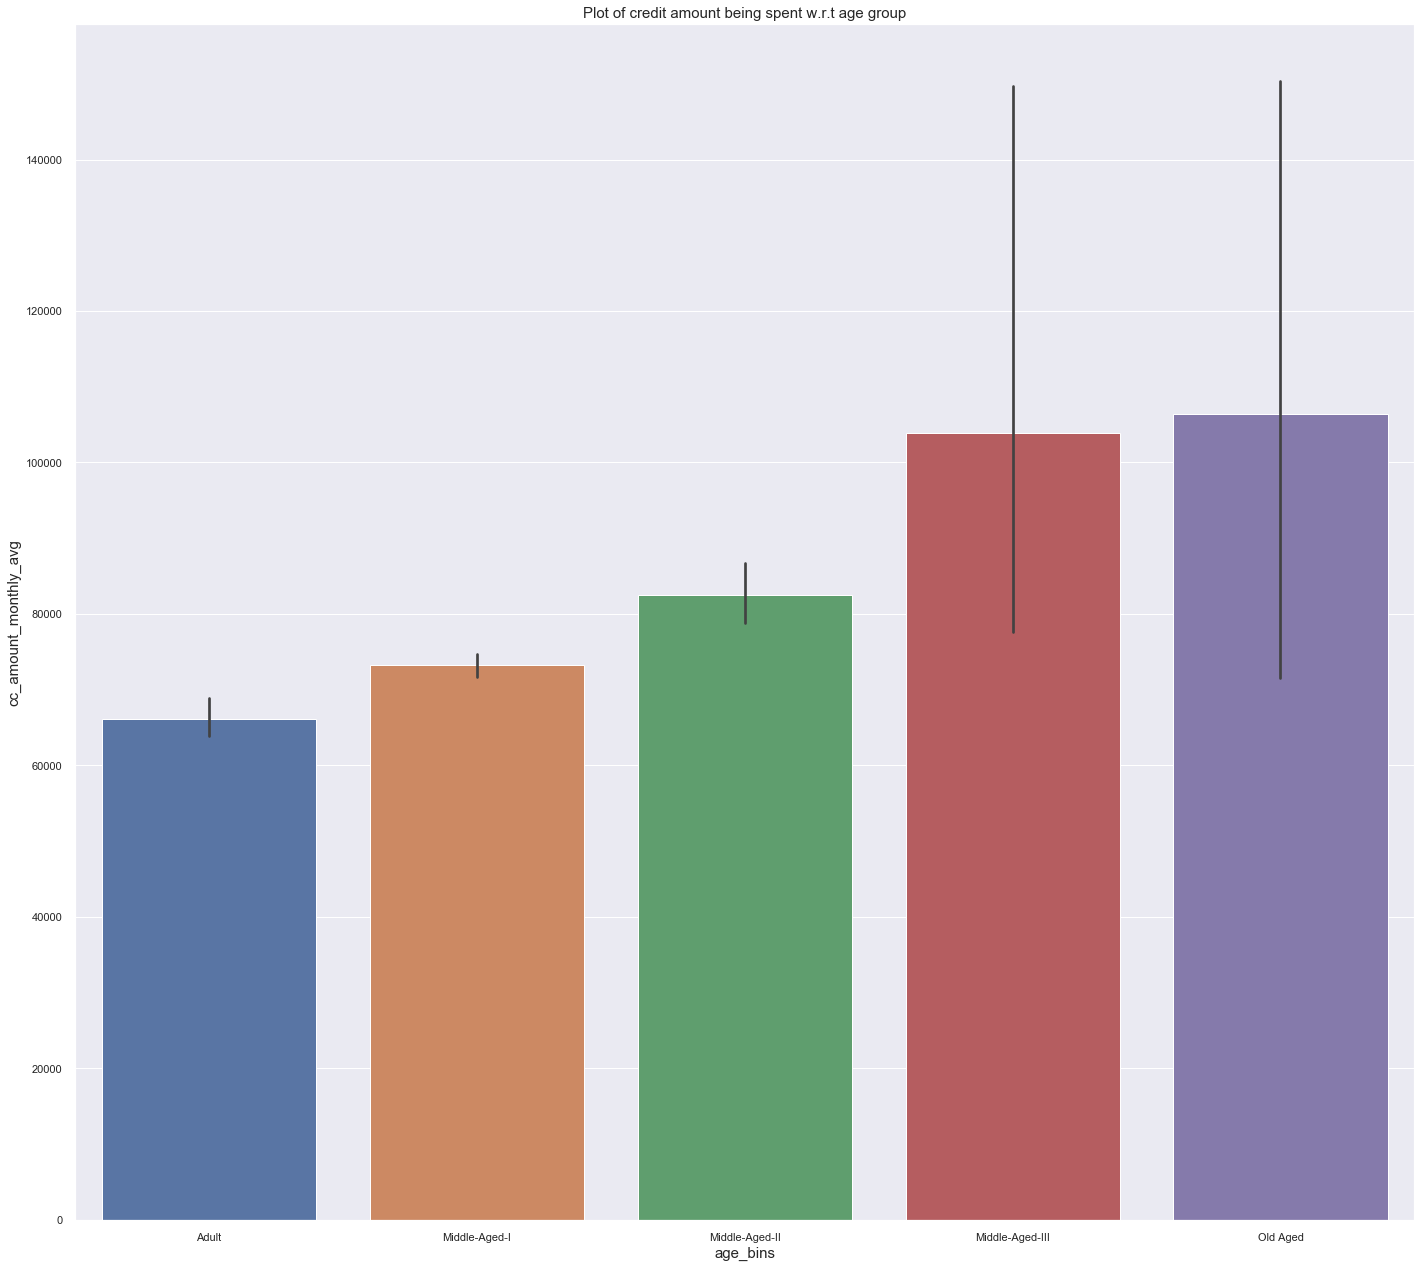

In [146]:
fig, ax = plt.subplots(figsize=(24,22))
sns.barplot('age_bins','cc_amount_monthly_avg',data=cc_spent_train, ax=ax)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('cc_amount_monthly_avg', fontsize=15)
plt.title("Plot of credit amount being spent w.r.t age group",fontsize=15)

We see that the credit amount being spent is increasing with age . Since , they categories save a lot
so they might be finding best deals with prices and with caskback available spending credit amount.

Text(0.5, 1.0, 'Plot of credit amount being spent w.r.t age group')

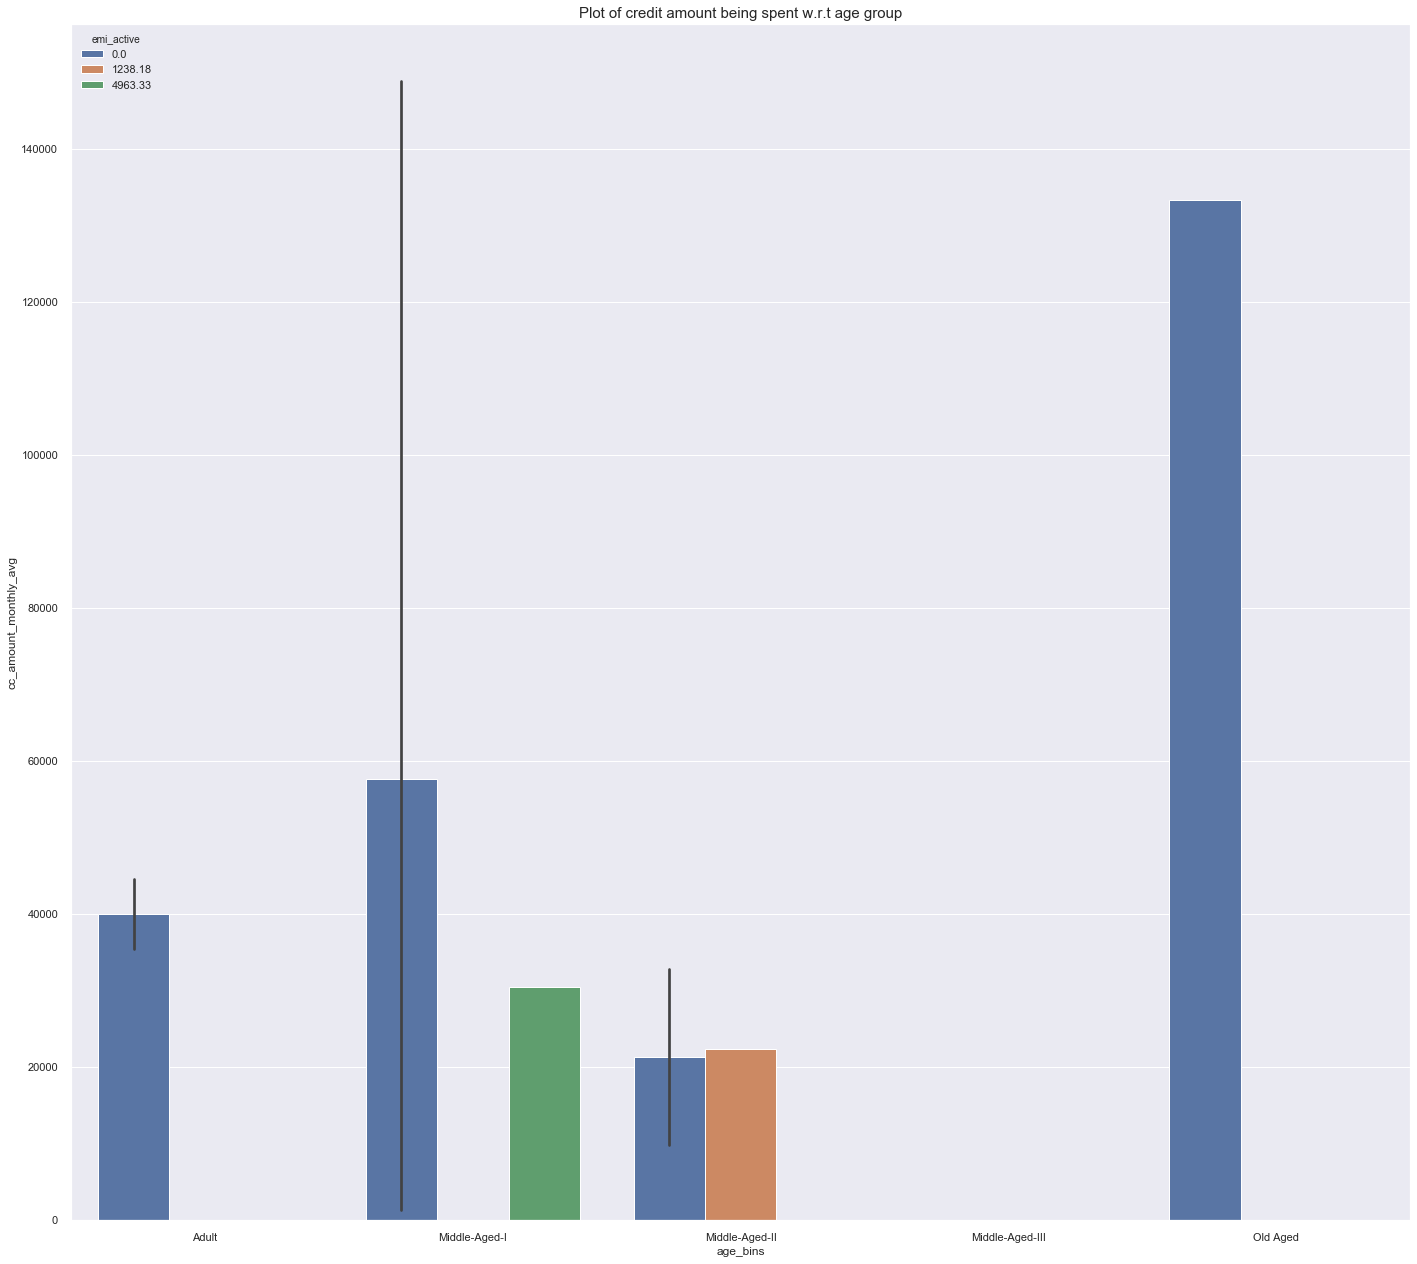

In [177]:
fig, ax = plt.subplots(figsize=(24,22))
ax = sns.barplot(x='age_bins',y='cc_amount_monthly_avg',hue='emi_active',data=cc_spent_train[:10])
plt.title("Plot of credit amount being spent w.r.t age group",fontsize=15)

We see the debt with other banks are almost nil for most of them . While some are having debts and their
spending pattern of credit cards is also less.

<font color='dark pink'><b>Observations from graph on Total number of debit amount in months of April, May and June</b></font>

In [148]:
# Total debit amount monthly average
cc_spent_train['dc_amt_monthly_avg'] = ( cc_spent_train['debit_amount_apr'] + cc_spent_train['debit_amount_may']
                                        + cc_spent_train['debit_amount_jun'] ) /3

# Total debit amount std deviation
cc_spent_train['dc_amt_monthly_std'] = cc_spent_train[debit_amount_lst].std(axis=1)

In [149]:
# Finding out the correlation of monthly average debit amount with average credit card spent
# for next 3 months
dc_amt_corr_lst = ['dc_amt_monthly_avg','dc_amt_monthly_std','cc_cons']
cc_spent_train[dc_amt_corr_lst].corr()

,dc_amt_monthly_avg,dc_amt_monthly_std,cc_cons
dc_amt_monthly_avg,1.000000,0.878749,0.098645
dc_amt_monthly_std,0.878749,1.000000,0.077350
cc_cons,0.098645,0.077350,1.000000


We see the same insights as we have seen with the credit amount. It means that total credit/debit
amount are highly correlated with each other.

In [150]:
cc_dc_amt_corr = ['dc_amt_monthly_avg','dc_amt_monthly_std','cc_amount_monthly_avg','cc_amount_monthly_std']

In [151]:
cc_spent_train[cc_dc_amt_corr].corr()

,dc_amt_monthly_avg,dc_amt_monthly_std,cc_amount_monthly_avg,cc_amount_monthly_std
dc_amt_monthly_avg,1.000000,0.878749,0.988086,0.866961
dc_amt_monthly_std,0.878749,1.000000,0.878075,0.954447
cc_amount_monthly_avg,0.988086,0.878075,1.000000,0.896864
cc_amount_monthly_std,0.866961,0.954447,0.896864,1.000000


Thus, above correlation matrix concludes there is high correlation between debit amount and credit amount.

A simple example, will make us more understand on it.

Whenever, we get our wages it is crediting amount to the account. On the other hand, the amount
being credited becomes amount debited to the bank i.e bank owes the amount to you (it is like a
liability from them).The same applies when you debit amount from bank. Hence, these features are
highly correlated.

<font color='red pink'><b>Total number of times amount debited/credited in April, May and June</font></b>

In [152]:
cc_amt_nof_lst = ['credit_count_apr','credit_count_may','credit_count_jun']
dc_amt_nof_lst = ['debit_count_apr','debit_count_may','debit_count_jun']

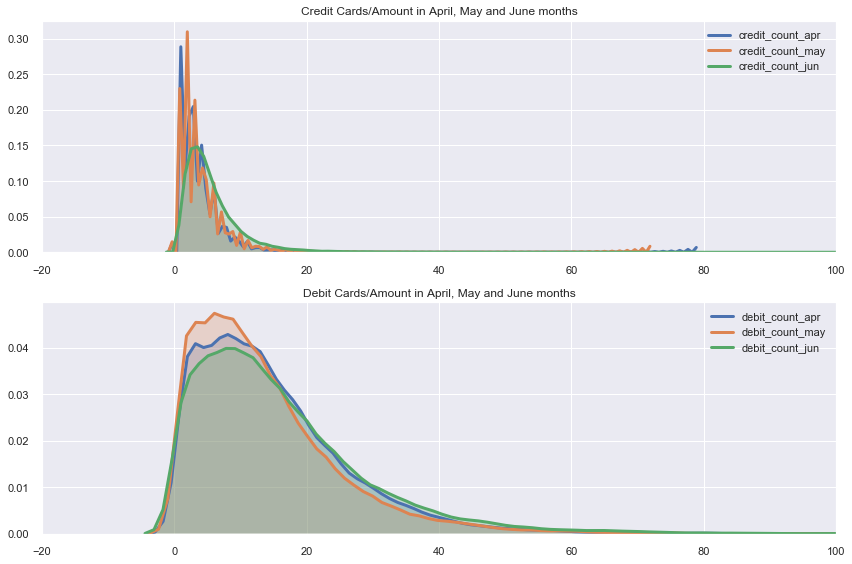

In [153]:
cc_dc_pattern(cc_spent_train,'credit_count_apr','credit_count_may','credit_count_jun',
              'debit_count_apr','debit_count_may','debit_count_jun',-20,100)

<font color='red pink'><b>Total no of credit transactions in April , May and June months</font></b>


In [154]:
cc_spent_train[cc_amt_nof_lst].describe()

,credit_count_apr,credit_count_may,credit_count_jun
count,32785.000000,32785.000000,32785.000000
mean,3.744123,4.022368,5.750013
std,3.428603,3.774935,4.632328
min,0.000000,0.000000,0.000000
25%,2.000000,2.000000,3.000000
50%,3.000000,3.000000,5.000000
75%,5.000000,5.000000,7.000000
max,78.000000,71.000000,117.000000


1. We see that the mean and median values almost being similar to each other.
2. The IQR range lies between 3-4 that means 3-4 credit transactions are carried out monthly
by most customers.
3. Also, for June month we see the difference between 3rd Quartile and maximum value being 117 . A 
difference of 110 amounting to. Which means there are few people who are carring out huge credit 
transactions.

<b><font color='dark pink'>Total no of credit transactions in April , May and June months</font></b>

In [155]:
cc_spent_train[dc_amt_nof_lst].describe()

,debit_count_apr,debit_count_may,debit_count_jun
count,32785.000000,32785.000000,32785.000000
mean,14.757659,13.716976,15.988533
std,11.449615,11.309208,13.176411
min,0.000000,0.000000,0.000000
25%,6.000000,6.000000,7.000000
50%,12.000000,11.000000,13.000000
75%,20.000000,18.800000,22.000000
max,147.000000,171.000000,164.000000


1. The mean values are greater than the median which means the data is mostly right skewed.
2. Debit transactions are in the range 12-15. We infer this through IQR's
3. However, the maximum debit transactions carried out is almost similar in all three. Hence,
we can observe all three months overlapping each other with slight deviations in it.

<b><font color='dark pink'> Understanding the Debit/Credit Transactions carried out on a average basis /month</font></b>

In [156]:
cc_trans_lst = ['credit_count_apr','credit_count_may','credit_count_jun']

In [157]:
cc_spent_train['cc_nof_trans_monthly_avg'] = (cc_spent_train['credit_count_apr'] + cc_spent_train['credit_amount_may']
                                             + cc_spent_train['credit_count_jun']) /3

cc_spent_train['cc_nof_trans_std'] = cc_spent_train[cc_trans_lst].std(axis=1)

In [158]:
# Finding the correlation matrix w.r.t target cc_cons
cc_trans_corr_lst = ['cc_nof_trans_monthly_avg','cc_nof_trans_std','cc_cons']
cc_spent_train[cc_trans_corr_lst].corr()

,cc_nof_trans_monthly_avg,cc_nof_trans_std,cc_cons
cc_nof_trans_monthly_avg,1.000000,0.097363,0.091370
cc_nof_trans_std,0.097363,1.000000,-0.001937
cc_cons,0.091370,-0.001937,1.000000


The no of credit transactions carried out has no relation with the credit card spent.

##### <font color='green'> Using Transasctions let us calculate the weighted average of credit amount spent </font>

In [159]:
cc_spent_train['credit_amt_weighted_average'] = (( cc_spent_train['credit_amount_apr'] * cc_spent_train['credit_count_apr'])
                                               + (cc_spent_train['credit_amount_may'] * cc_spent_train['credit_count_may'])
                                               + (cc_spent_train['credit_amount_jun'] * cc_spent_train['credit_count_jun']) / 3)

In [160]:
cc_spent_train['credit_amt_weighted_average'].head()


0    2.723651e+06
1    2.604658e+05
2    2.936700e+04
3    8.796967e+04
4    1.884553e+05
Name: credit_amt_weighted_average, dtype: float64

##### <font color='green'> Relationship of "weighted average of credit amount" with the "credit card spent for next 3 months"</font>

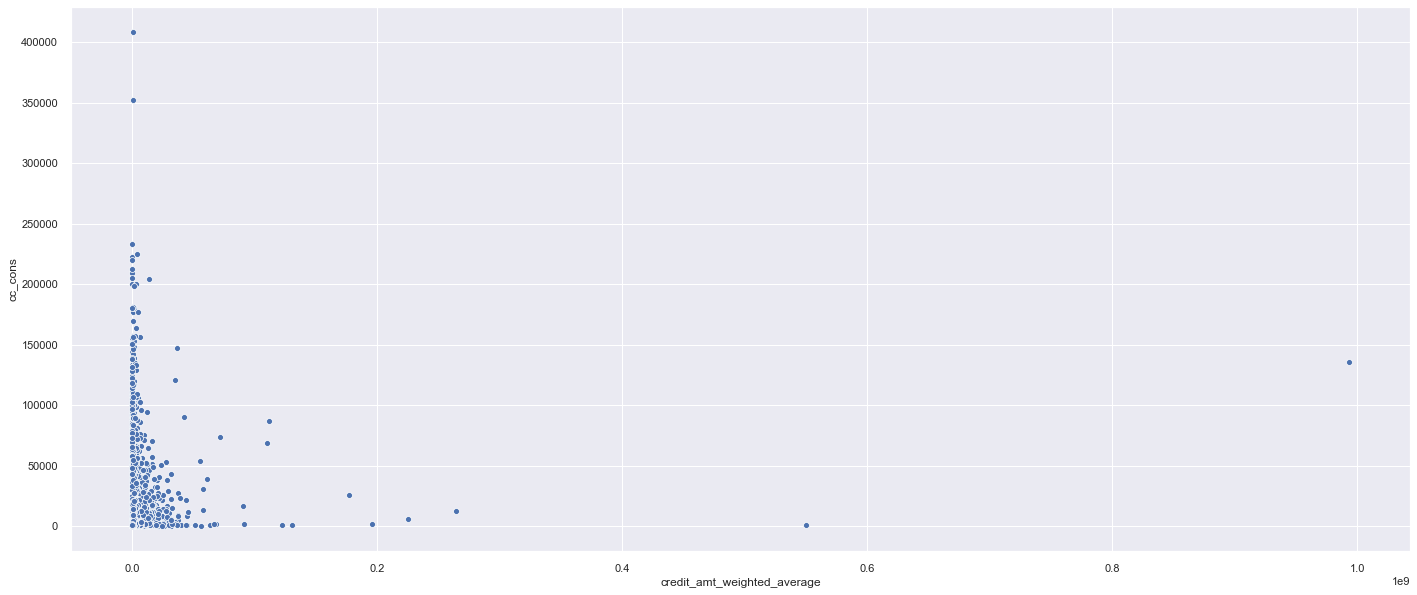

In [161]:
ax = sns.scatterplot(x='credit_amt_weighted_average', y='cc_cons', data=cc_spent_train)
plt.show()

When visualizing the above graph we see a dense region around 0 to 5000000 in x-axis and across y-axis
from 0 to 150000. So, the credit amount spent will also be based on these figures.

##### <font color='green'> Debit Transactions</font>

In [162]:
# Debit transactions
dc_trans_lst = ['debit_count_apr','debit_count_may','debit_count_jun']

cc_spent_train['dc_nof_trans_monthly_avg'] = (cc_spent_train['debit_count_apr'] + cc_spent_train['debit_amount_may']
                                             + cc_spent_train['debit_count_jun']) / 3

cc_spent_train['dc_nof_trans_std'] = cc_spent_train[dc_trans_lst].std(axis=1)

In [163]:
# Finding the correlation matrix w.r.t target cc_cons
dc_trans_corr_lst = ['dc_nof_trans_monthly_avg','dc_nof_trans_std','cc_cons']
cc_spent_train[dc_trans_corr_lst].corr()

,dc_nof_trans_monthly_avg,dc_nof_trans_std,cc_cons
dc_nof_trans_monthly_avg,1.000000,0.074482,0.093671
dc_nof_trans_std,0.074482,1.000000,-0.013990
cc_cons,0.093671,-0.013990,1.000000


We almost see the same correlation of number of debit transactions , which means the no of debit transactions
are highly correlated with the debit transactions. Which can be the case that the more amount being credited to account,
we feel like spending it a lot. Hence, keep debiting amount from account causing lot of debit/credit transactions as a result.

<b><font color='dark pink'> Understanding Maximum amount credited for April, May and June</font></b>

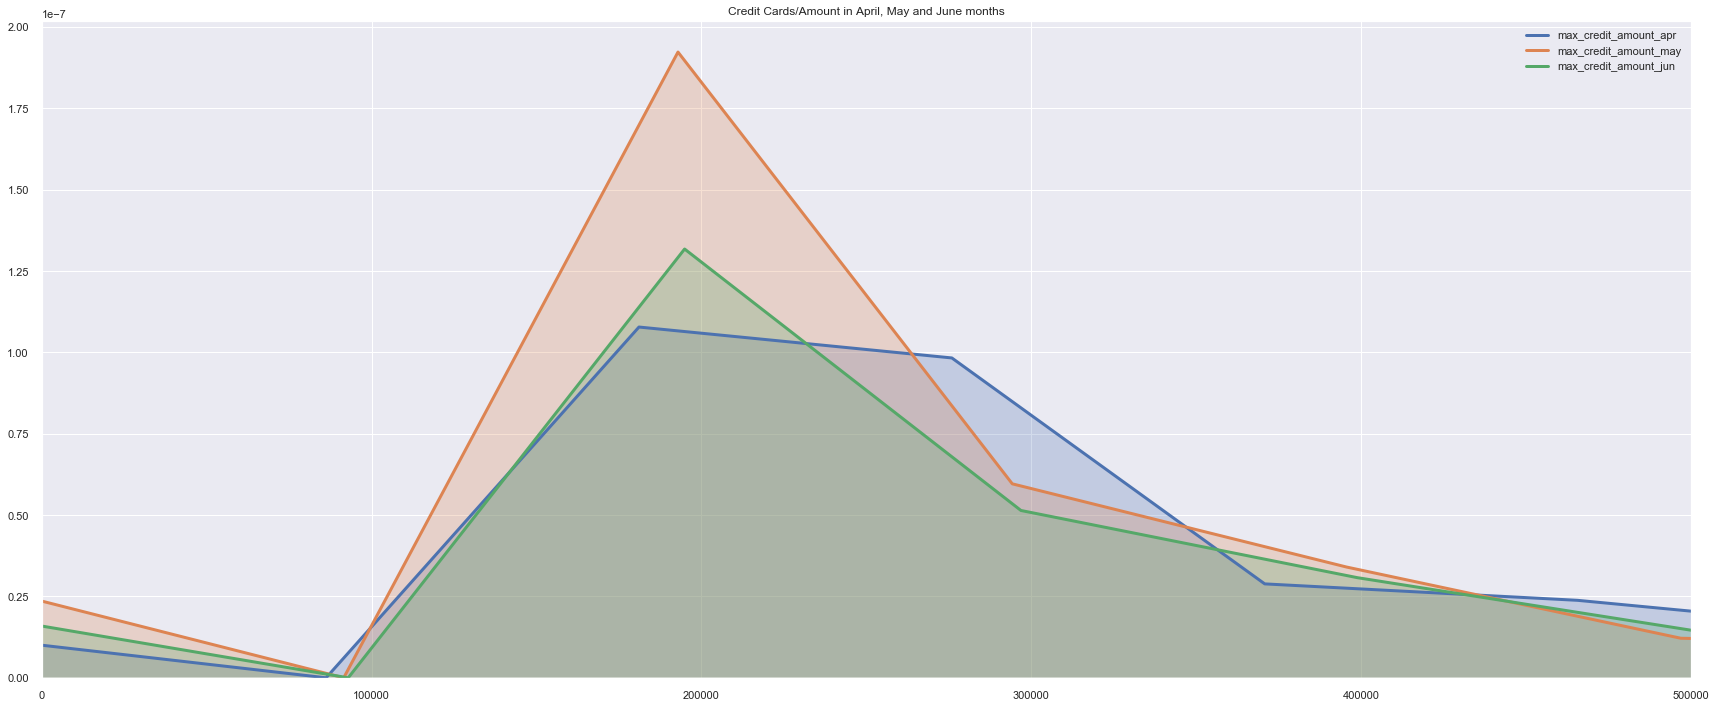

In [164]:
sns.set()
sns.distplot(cc_spent_train[['max_credit_amount_apr']], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label='max_credit_amount_apr')
sns.distplot(cc_spent_train['max_credit_amount_may'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='max_credit_amount_may')
sns.distplot(cc_spent_train['max_credit_amount_jun'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='max_credit_amount_jun')
plt.xlabel("")
plt.title("Credit Cards/Amount in April, May and June months")
plt.xlim(0, 500000)
    
print("")
plt.tight_layout()
plt.show()
    

In [165]:
max_credit_amt_lst = ['max_credit_amount_apr','max_credit_amount_may','max_credit_amount_jun']
cc_spent_train[max_credit_amt_lst].describe()

,max_credit_amount_apr,max_credit_amount_may,max_credit_amount_jun
count,3.278500e+04,3.278500e+04,3.278500e+04
mean,4.371779e+04,4.713414e+04,4.443550e+04
std,1.129092e+05,1.226044e+05,1.189443e+05
min,1.800000e-01,1.500000e-01,6.000000e-02
25%,1.636900e+04,1.676100e+04,1.625577e+04
50%,2.690000e+04,2.908400e+04,2.702500e+04
75%,4.570200e+04,5.000000e+04,4.696700e+04
max,1.202915e+07,1.285103e+07,1.293238e+07


We see that the mean is lying in the same range, while the deviation is more in the max_credit_amount for June.That
means customers have more amount credited to their accounts in the June month.
Also,  we see the min amount to be 0.06 and maximum amount to be 5.20e+06 for Month June. The amount being credited for most customers is lying in the range of 29000+ to 33000+ for months of April, May and June. 

#### <font color='dark pink'> Finding the mean and standard deviation of max_credit_amount</font>

In [166]:
max_cc_amt = ['max_credit_amount_apr','max_credit_amount_may','max_credit_amount_jun']
# Finding Mean
cc_spent_train['cc_max_amt_monthly_avg'] = (cc_spent_train['max_credit_amount_apr'] + cc_spent_train['max_credit_amount_may']
                                           + cc_spent_train['max_credit_amount_jun']) / 3

# Finding Std.
cc_spent_train['cc_max_amt_monthly_std'] = cc_spent_train[max_cc_amt].std(axis=1)

In [167]:
# Finding the correlation w.r.t target
max_cc_amt_avg_std_lst = ['cc_max_amt_monthly_avg','cc_max_amt_monthly_std','cc_cons']
cc_spent_train[max_cc_amt_avg_std_lst].corr()

,cc_max_amt_monthly_avg,cc_max_amt_monthly_std,cc_cons
cc_max_amt_monthly_avg,1.000000,0.890028,0.111715
cc_max_amt_monthly_std,0.890028,1.000000,0.077005
cc_cons,0.111715,0.077005,1.000000


Even maximum amount being credited to account on a monthly basis makes it difficult to predict the 
credit card spent for next 3 months.

In [168]:
cc_tot_max_corr_lst = ['cc_max_amt_monthly_std','cc_max_amt_monthly_avg',
                       'cc_amount_monthly_avg','cc_amount_monthly_std']
cc_spent_train[cc_tot_max_corr_lst].corr()

,cc_max_amt_monthly_std,cc_max_amt_monthly_avg,cc_amount_monthly_avg,cc_amount_monthly_std
cc_max_amt_monthly_std,1.000000,0.890028,0.702430,0.801105
cc_max_amt_monthly_avg,0.890028,1.000000,0.883667,0.812770
cc_amount_monthly_avg,0.702430,0.883667,1.000000,0.896864
cc_amount_monthly_std,0.801105,0.812770,0.896864,1.000000


As you can observe that the total credit amount (average) is highly correlated with maximum credit amount(avg). 

Let us see the credit amount balance left on subtracting the maximum credit amount with total credit amount.

In [169]:
cc_spent_train['credit_amount_balance'] = cc_spent_train['cc_max_amt_monthly_avg'] - cc_spent_train['cc_amount_monthly_avg']

##### <font color='green'> Credit Card Limit over EMI Active / Debt  visualization</font>

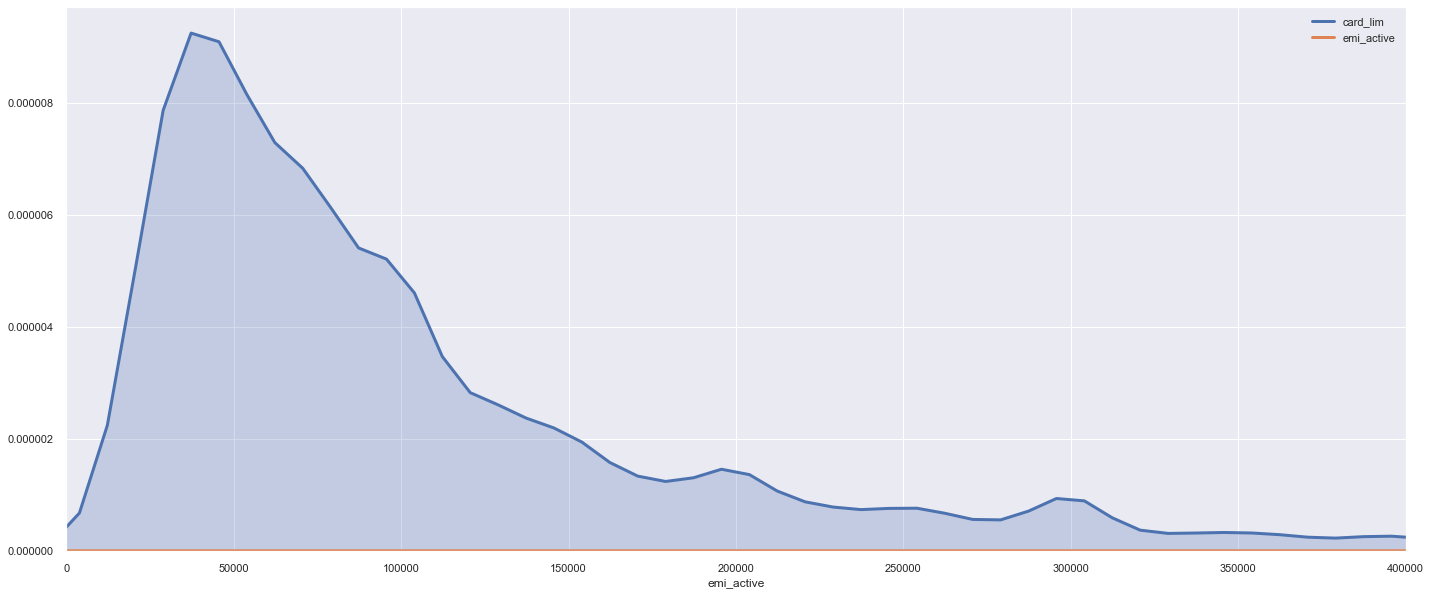

(400000, 1400000)

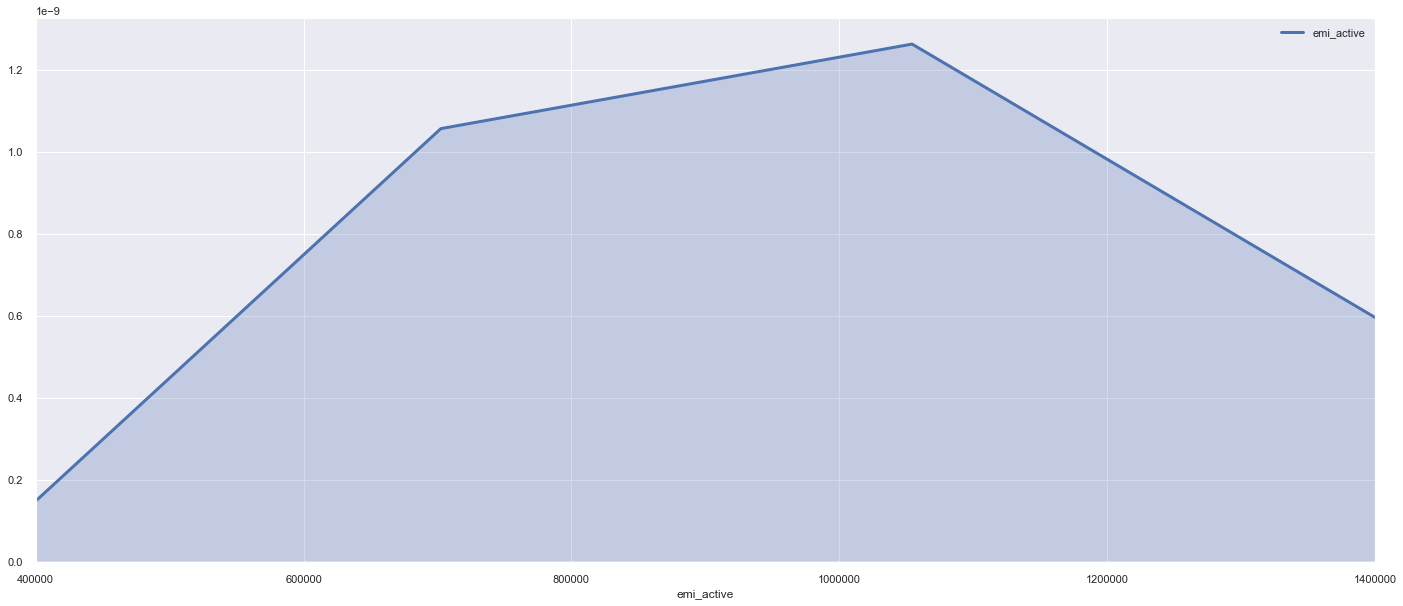

In [170]:
ax1 = sns.distplot(cc_spent_train['card_lim'], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label='card_lim')
ax1 = sns.distplot(cc_spent_train['emi_active'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='emi_active')
ax1.set_xlim(0,400000)
plt.show()
   
ax2 = sns.distplot(cc_spent_train['emi_active'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='emi_active')
plt.xlim(400000, 1400000)

Since, emi_active is present in the higher range,for better visualization created any subplot. 
Above graph gives us a comparison of credit card limit allocated to users and the debt 
being transferred as other banks. Majority of the users account for 50000 as the card limit.
When comes to credit debts, huge EMI's are active ranging from 400000 - 1400000. Will the help
of card_limit and emi_active, we can calcuate the credit_utlization.

<b> Credit_Utilization = EMI_active / Card_lim </b>

In [171]:
cc_spent_train['credit_utilization'] = cc_spent_train['emi_active'] / cc_spent_train['card_lim']

##### <font color='green'> Plotting of credit_ultization with age</font>

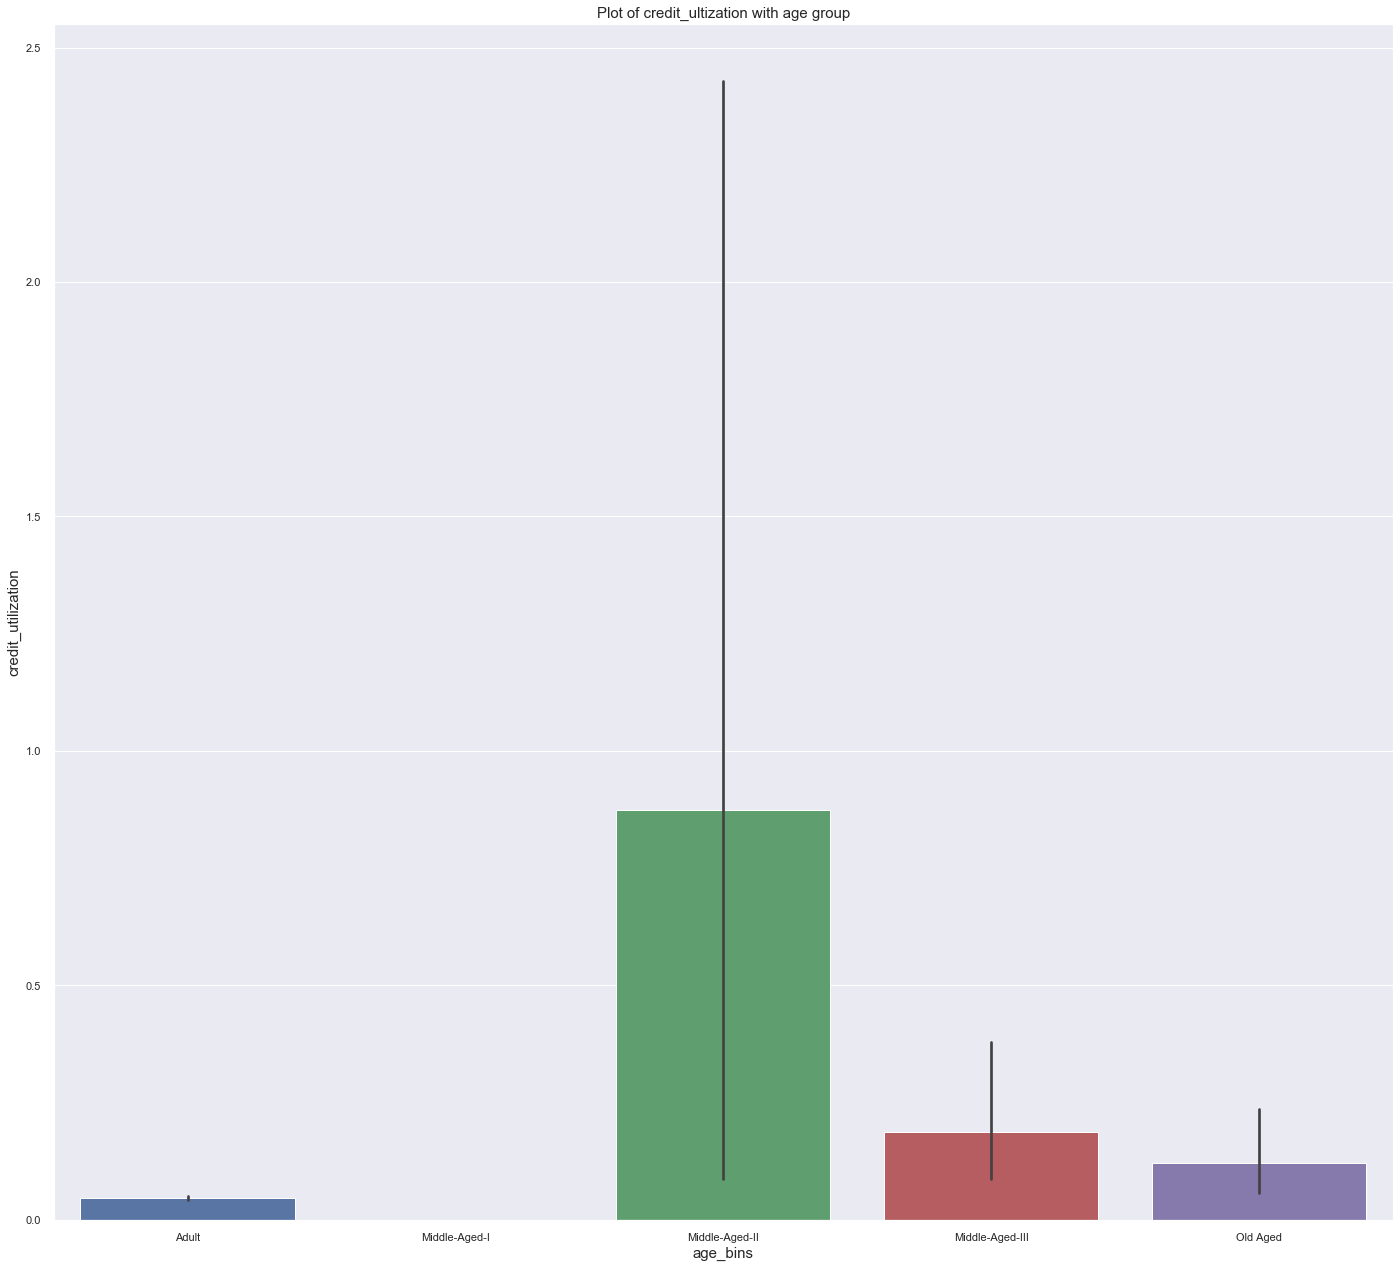

In [178]:
fig, ax = plt.subplots(figsize=(24,22))
sns.barplot('age_bins','credit_utilization',data=cc_spent_train, ax=ax)
#ax.set_ylim(0,350000)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('credit_utilization', fontsize=15)
plt.title("Plot of credit_ultization with age group",fontsize=15)
plt.show()

Consumers with zero emi_active, have zero credit ultization. Credit Ultization increases from across
Middle-Aged-II i.e 41 and 51 and then again falls drastically for the Middle-Aged-III and Old Aged groups
accordingly. This concludes that the middle aged-II spent maximum credit amount.